# Thesis computational workflow — English commented version

This version keeps **all original code cells and stored outputs unchanged** and adds an explanatory Markdown cell before each code cell.

The added notes distinguish technical/reproducibility operations from scientific experiments, explain the method used in each step, and interpret the main stored results. Validation and held-out test results are explicitly separated, and surrogate online timing is not presented as a Full Order Model speedup.


### Step 1 — Mount Google Drive

**Method.** Mount persistent Drive storage so datasets, checkpoints, logs, and backups survive Colab runtime resets.

**Comment on the stored result.** The stored run reports that Drive was already mounted, so no scientific state was changed.


In [9]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Step 2 — Audit original thesis assets

**Method.** Check the Python environment and verify that the historical 40x10 dataset and the two static checkpoints are available.

**Comment on the stored result.** The original 40x10 dataset and both static checkpoints were found. The Drive folder itself was not a Git checkout, which is why a separate local repository was used.


In [10]:
from pathlib import Path
import sys

# Percorso usato nel lavoro precedente.
ROOT = Path(
    "/content/drive/MyDrive/Tesi/generative-spde-surrogates"
)

print("=== AMBIENTE ===")
print("Versione Python:", sys.version.split()[0])

print("\n=== CARTELLA DEL PROGETTO ===")
print("Percorso controllato:", ROOT)
print("Cartella presente:", ROOT.is_dir())

if not ROOT.is_dir():
    print(
        "\nLa cartella non e' stata trovata in questo percorso."
        "\nNon creare nuove cartelle e non rigenerare i dati:"
        "\nprima individuiamo la posizione corretta."
    )

else:
    print(
        "Elemento .git presente:",
        (ROOT / ".git").exists()
    )

    print(
        "Cartella src/spde_surrogates presente:",
        (ROOT / "src" / "spde_surrogates").is_dir()
    )

    print(
        "Cartella completion presente:",
        (ROOT / "src" / "spde_surrogates" / "completion").is_dir()
    )

    files_to_check = {
        "Dataset FOM 40x10":
            "data/static_comparison_40x10.npz",

        "Checkpoint RealNVP 40x10":
            "outputs/static_comparison_40x10/checkpoints/realnvp.pt",

        "Checkpoint Flow Matching 40x10":
            "outputs/static_comparison_40x10/checkpoints/flow_matching.pt",
    }

    print("\n=== FILE DEL LAVORO PRECEDENTE ===")

    for label, relative_path in files_to_check.items():
        path = ROOT / relative_path

        print(f"\n{label}")
        print(f"Percorso: {path}")

        try:
            if path.is_file():
                size_bytes = path.stat().st_size

                if size_bytes == 0:
                    print("Esito: PRESENTE, MA VUOTO")
                else:
                    size_mib = size_bytes / (1024 ** 2)
                    print("Esito: TROVATO")
                    print(f"Dimensione: {size_mib:.2f} MiB")
            else:
                print("Esito: NON TROVATO IN QUESTO PERCORSO")

        except OSError as error:
            print(f"Esito: ERRORE DI ACCESSO — {error}")

=== AMBIENTE ===
Versione Python: 3.13.16

=== CARTELLA DEL PROGETTO ===
Percorso controllato: /content/drive/MyDrive/Tesi/generative-spde-surrogates
Cartella presente: True
Elemento .git presente: False
Cartella src/spde_surrogates presente: False
Cartella completion presente: False

=== FILE DEL LAVORO PRECEDENTE ===

Dataset FOM 40x10
Percorso: /content/drive/MyDrive/Tesi/generative-spde-surrogates/data/static_comparison_40x10.npz
Esito: TROVATO
Dimensione: 806.80 MiB

Checkpoint RealNVP 40x10
Percorso: /content/drive/MyDrive/Tesi/generative-spde-surrogates/outputs/static_comparison_40x10/checkpoints/realnvp.pt
Esito: TROVATO
Dimensione: 3.71 MiB

Checkpoint Flow Matching 40x10
Percorso: /content/drive/MyDrive/Tesi/generative-spde-surrogates/outputs/static_comparison_40x10/checkpoints/flow_matching.pt
Esito: TROVATO
Dimensione: 2.40 MiB


### Step 3 — Inspect the original dataset

**Method.** Read NPZ headers without loading the full tensor, verifying shapes, time grid, parameter groups, and realizations.

**Comment on the stored result.** The dataset contains 400 trajectories = 40 parameter groups x 10 realizations, with 101 times from 0 to 5 (dt = 0.05) and 2763 spatial degrees of freedom.


In [11]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/Tesi/generative-spde-surrogates"
)

DATASET = ROOT / "data/static_comparison_40x10.npz"

print("=== LIBRERIA NUMPY ===")
print("Versione:", np.__version__)

print("\n=== STRUTTURA DEL DATASET ===")

# Leggiamo solo le intestazioni degli array:
# la matrice delle traiettorie NON viene caricata in memoria.
with ZipFile(DATASET, "r") as archive:

    for name in archive.namelist():

        if not name.endswith(".npy"):
            continue

        with archive.open(name, "r") as stream:
            version = np.lib.format.read_magic(stream)

            if version == (1, 0):
                shape, _, dtype = (
                    np.lib.format.read_array_header_1_0(stream)
                )

            elif version == (2, 0):
                shape, _, dtype = (
                    np.lib.format.read_array_header_2_0(stream)
                )

            else:
                raise ValueError(
                    f"Formato NPY da verificare: {version}"
                )

        print(
            f"{Path(name).stem:15s} "
            f"forma={shape}, tipo={dtype}"
        )

# Questi due array sono piccoli.
# Non accediamo a data["trajectories"].
with np.load(DATASET, allow_pickle=False) as data:
    times = data["times"]
    group_ids = data["group_ids"]

groups, counts = np.unique(
    group_ids,
    return_counts=True,
)

print("\n=== GRIGLIA TEMPORALE ===")
print("Numero di istanti:", len(times))
print("Tempo iniziale:", times[0])
print("Tempo finale:", times[-1])
print(
    "Tutti gli intervalli sono pari a 0.05:",
    bool(np.allclose(np.diff(times), 0.05)),
)

print("\n=== GRUPPI DI PARAMETRI ===")
print("Numero di gruppi:", len(groups))
print("Traiettorie totali:", len(group_ids))
print("Minimo di traiettorie per gruppo:", counts.min())
print("Massimo di traiettorie per gruppo:", counts.max())

=== LIBRERIA NUMPY ===
Versione: 2.1.3

=== STRUTTURA DEL DATASET ===
mu_bank         forma=(40, 3), tipo=float64
times           forma=(101,), tipo=float64
conds           forma=(400, 3), tipo=float64
trajectories    forma=(400, 101, 2763), tipo=float64
group_ids       forma=(400,), tipo=int64

=== GRIGLIA TEMPORALE ===
Numero di istanti: 101
Tempo iniziale: 0.0
Tempo finale: 5.0
Tutti gli intervalli sono pari a 0.05: True

=== GRUPPI DI PARAMETRI ===
Numero di gruppi: 40
Traiettorie totali: 400
Minimo di traiettorie per gruppo: 10
Massimo di traiettorie per gruppo: 10


### Step 4 — Inspect historical checkpoints

**Method.** Load checkpoint metadata and verify model type, POD dimension, physical dimension, and saved preprocessing.

**Comment on the stored result.** Both static checkpoints use the same 79-mode POD representation over 2763 degrees of freedom, making a controlled static comparison possible.


In [12]:
from pathlib import Path
import torch

ROOT = Path(
    "/content/drive/MyDrive/Tesi/generative-spde-surrogates"
)

CHECKPOINT_DIR = (
    ROOT
    / "outputs"
    / "static_comparison_40x10"
    / "checkpoints"
)

print("=== LIBRERIA PYTORCH ===")
print("Versione:", torch.__version__)

# Conserviamo in memoria solo i due piccoli checkpoint.
checkpoints = {}

required_keys = {
    "model_type",
    "model_state_dict",
    "pod",
    "condition_normalizer",
    "coefficient_normalizer",
}

for name in ("realnvp", "flow_matching"):

    path = CHECKPOINT_DIR / f"{name}.pt"

    print(f"\n=== CHECKPOINT: {name} ===")
    print("Percorso:", path)
    print(
        "Dimensione:",
        f"{path.stat().st_size / (1024 ** 2):.2f} MiB",
    )

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"{name}: formato diverso dal dizionario atteso."
        )

    missing = required_keys - set(checkpoint)

    if missing:
        raise ValueError(
            f"{name}: chiavi attese mancanti: {sorted(missing)}"
        )

    pod = checkpoint["pod"]

    print("Tipo di modello:", checkpoint["model_type"])
    print("Modi POD:", pod["n_modes"])
    print("Gradi di liberta':", pod["n_dofs"])
    print("Forma della base POD:", tuple(pod["basis"].shape))
    print("Caricamento del checkpoint: OK")

    checkpoints[name] = checkpoint

print("\n=== CONFRONTO DEL PREPROCESSING SALVATO ===")

fields_to_compare = {
    "pod": ("mean", "basis"),
    "condition_normalizer": ("mean", "std"),
    "coefficient_normalizer": ("mean", "std"),
}

for section, fields in fields_to_compare.items():

    for field in fields:
        first = checkpoints["realnvp"][section][field]
        second = checkpoints["flow_matching"][section][field]

        identical = torch.equal(first, second)

        print(
            f"{section}.{field}: "
            f"identici = {identical}"
        )

=== LIBRERIA PYTORCH ===
Versione: 2.11.0+cpu

=== CHECKPOINT: realnvp ===
Percorso: /content/drive/MyDrive/Tesi/generative-spde-surrogates/outputs/static_comparison_40x10/checkpoints/realnvp.pt
Dimensione: 3.71 MiB
Tipo di modello: realnvp
Modi POD: 79
Gradi di liberta': 2763
Forma della base POD: (79, 2763)
Caricamento del checkpoint: OK

=== CHECKPOINT: flow_matching ===
Percorso: /content/drive/MyDrive/Tesi/generative-spde-surrogates/outputs/static_comparison_40x10/checkpoints/flow_matching.pt
Dimensione: 2.40 MiB
Tipo di modello: flow_matching
Modi POD: 79
Gradi di liberta': 2763
Forma della base POD: (79, 2763)
Caricamento del checkpoint: OK

=== CONFRONTO DEL PREPROCESSING SALVATO ===
pod.mean: identici = True
pod.basis: identici = True
condition_normalizer.mean: identici = True
condition_normalizer.std: identici = True
coefficient_normalizer.mean: identici = True
coefficient_normalizer.std: identici = True


### Step 5 — Create a clean Git checkout

**Method.** Prepare a separate local Git working copy so code development is isolated from large scientific files on Drive.

**Comment on the stored result.** The recorded execution was manually interrupted while waiting for repository input. Later repository checks/restoration succeed, so this is only a setup interruption.


In [13]:
from pathlib import Path
import os
import re
import subprocess

# Nuova cartella del codice, separata dai risultati su Drive.
REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

REPO_URL = input(
    "Incolla l'URL HTTPS della tua repository GitHub: "
).strip()

# Accettiamo solo il normale indirizzo della repository,
# senza credenziali, parametri o percorsi di singoli file.
if not re.fullmatch(
    r"https://github\.com/[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+/?",
    REPO_URL,
):
    raise ValueError(
        "Indirizzo non valido. Copia l'URL da Code > HTTPS, "
        "senza password o token."
    )

# Non sovrascriviamo eventuali copie di lavoro gia' presenti.
if REPO_DIR.exists():
    raise FileExistsError(
        f"La cartella esiste gia': {REPO_DIR}\n"
        "Fermati e riportami questo messaggio: non cancellarla."
    )

REPO_DIR.parent.mkdir(parents=True, exist_ok=True)

# Se serve autenticazione, Git deve fermarsi invece di
# restare in attesa di una password nel terminale.
git_env = os.environ.copy()
git_env["GIT_TERMINAL_PROMPT"] = "0"

print("\n=== RECUPERO DEL CODICE ===", flush=True)

subprocess.run(
    ["git", "clone", REPO_URL, str(REPO_DIR)],
    env=git_env,
    check=True,
)

print("\n=== CONTROLLO DELLA COPIA DI LAVORO ===")
print("Repository:", REPO_URL)
print("Cartella:", REPO_DIR)
print("Elemento .git presente:", (REPO_DIR / ".git").exists())
print(
    "Pacchetto originale presente:",
    (REPO_DIR / "src" / "spde_surrogates").is_dir(),
)
print(
    "Estensione completion presente:",
    (REPO_DIR / "src" / "spde_surrogates" / "completion").is_dir(),
)

revision = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"],
    cwd=REPO_DIR,
    text=True,
).strip()

print("Revisione Git recuperata:", revision)

KeyboardInterrupt: Interrupted by user

### Step 6 — Select the thesis branch

**Method.** Use the dedicated thesis/dynamic-completion branch to keep the extension separate from the historical main branch.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [ ]:
from pathlib import Path
import subprocess

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

BRANCH = "thesis/dynamic-completion"

if not (REPO_DIR / ".git").exists():
    raise RuntimeError(
        "La copia Git non e' presente nel percorso previsto. "
        "Fermati e riportami questo messaggio."
    )

def git(*args):
    return subprocess.check_output(
        ["git", "-C", str(REPO_DIR), *args],
        text=True,
    ).strip()

# Prima di cambiare branch, controlliamo eventuali modifiche.
status = git("status", "--short")

if status:
    print("Modifiche presenti:\n", status)
    raise RuntimeError(
        "Ci sono modifiche da controllare. "
        "Non cancellare nulla: incollami questo output."
    )

current_branch = git("branch", "--show-current")

local_branches = git(
    "for-each-ref",
    "--format=%(refname:short)",
    "refs/heads",
).splitlines()

if current_branch == BRANCH:
    print("Il branch dedicato e' gia' attivo.")

elif BRANCH in local_branches:
    git("switch", BRANCH)
    print("Riutilizzato il branch dedicato.")

else:
    git("switch", "-c", BRANCH)
    print("Creato il branch dedicato.")

print("\n=== STATO DEL CODICE ===")
print("Cartella:", REPO_DIR)
print("Branch attivo:", git("branch", "--show-current"))
print("Revisione:", git("rev-parse", "--short", "HEAD"))
print("Modifiche locali:", git("status", "--short") or "Nessuna")

### Step 7 — Load the completion package

**Method.** Upload and extract the prepared extension package without modifying the repository yet.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [8]:
from pathlib import Path
from zipfile import ZipFile
import tempfile
from google.colab import files as colab_files

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        "Google Drive non risulta collegato. "
        "Riesegui soltanto la cella drive.mount, poi riprova."
    )

UPLOAD_DIR = DRIVE_ROOT / "Tesi" / "materiale_completamento"
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("Seleziona generative-spde-surrogates-completed.zip")

uploaded = colab_files.upload(target_dir=str(UPLOAD_DIR))

if len(uploaded) != 1:
    raise RuntimeError(
        "Devi selezionare un solo file ZIP."
    )

ZIP_PATH = Path(next(iter(uploaded)))

# Ogni esecuzione usa una cartella di estrazione nuova,
# senza sovrascrivere la repository o estrazioni precedenti.
EXTRACT_DIR = Path(
    tempfile.mkdtemp(prefix="tesi-consegna-", dir="/content")
)

with ZipFile(ZIP_PATH, "r") as archive:
    names = archive.namelist()

    expected_installer = (
        "generative-spde-surrogates-completed/"
        "scripts/install_into_checkout.py"
    )

    if expected_installer not in names:
        raise RuntimeError(
            "Questo non sembra lo ZIP completed previsto. "
            "Fermati e controlliamo il file selezionato."
        )

    # Verifica dei percorsi prima dell'estrazione.
    for name in names:
        path = Path(name)
        if path.is_absolute() or ".." in path.parts:
            raise RuntimeError(
                "L'archivio contiene un percorso non valido."
            )

    archive.extractall(EXTRACT_DIR)

EXT_DIR = EXTRACT_DIR / "generative-spde-surrogates-completed"

print("\n=== CONSEGNA DISPONIBILE ===")
print("ZIP salvato su Drive:", ZIP_PATH)
print("Cartella estratta:", EXT_DIR)
print(
    "Script di integrazione presente:",
    (EXT_DIR / "scripts" / "install_into_checkout.py").is_file(),
)
print("Nessun file copiato nella repository.")

Seleziona generative-spde-surrogates-completed.zip


Saving generative-spde-surrogates-completed.zip to /content/drive/MyDrive/Tesi/materiale_completamento/generative-spde-surrogates-completed (3).zip

=== CONSEGNA DISPONIBILE ===
ZIP salvato su Drive: /content/drive/MyDrive/Tesi/materiale_completamento/generative-spde-surrogates-completed (3).zip
Cartella estratta: /content/tesi-consegna-cd0giyyr/generative-spde-surrogates-completed
Script di integrazione presente: True
Nessun file copiato nella repository.


### Step 8 — Dry-run the integration

**Method.** Run the installer in inspection mode to list additions and detect possible collisions before applying changes.

**Comment on the stored result.** The dry-run reports 38 new files and explicitly leaves the original files unchanged.


In [14]:
import subprocess
import sys

INSTALLER = EXT_DIR / "scripts" / "install_into_checkout.py"

result = subprocess.run(
    [
        sys.executable,
        str(INSTALLER),
        "--target",
        str(REPO_DIR),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout, end="")

if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        "Il controllo preliminare si e' fermato. "
        "Non aggiungere --apply e non modificare i file: "
        "incollami l'output."
    )

print("\nCONTROLLO PRELIMINARE SUPERATO.")
print("Le aggiunte non sono ancora state applicate.")

38 new files; original files are left unchanged, including README.md.
pyproject.toml
README_COMPLETION.md
docs/Tutorial_completamento_tesi.pdf
docs/TUTORIAL_COMPLETO.md
docs/pdf_header.tex
tests/test_completion.py
thesis/preview.pdf
thesis/INTEGRAZIONE.md
thesis/abstract_provvisorio.tex
thesis/references.bib
thesis/continuation.tex
thesis/preview.tex
configs/completion_heat_smoke.yaml
configs/completion_heat.yaml
configs/completion_rad.yaml
reports/delivery_record.json
reports/HISTORICAL_BASELINE.md
reports/original_manifest.json
scripts/check_original_sources.py
scripts/make_variant.py
scripts/run_completion_smoke.sh
scripts/install_into_checkout.py
reports/verification/smoke_summary_NOT_SCIENTIFIC.csv
reports/verification/pytest.txt
reports/verification/environment.json
reports/verification/end_to_end_smoke.txt
reports/verification/smoke_report_NOT_SCIENTIFIC.md
reports/verification/README.md
src/spde_surrogates/completion/heat.py
src/spde_surrogates/completion/report.py
src/spde_sur

### Step 9 — Apply the extension

**Method.** Add the new completion modules, configurations, tests, reports, and thesis-support files to the working checkout.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [15]:
from pathlib import Path
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

if "EXT_DIR" not in globals():
    raise RuntimeError(
        "La variabile EXT_DIR non e' disponibile. "
        "Fermati e riportami questo messaggio."
    )

INSTALLER = Path(EXT_DIR) / "scripts" / "install_into_checkout.py"

if not INSTALLER.is_file() or not (REPO_DIR / ".git").exists():
    raise RuntimeError(
        "Non trovo lo script o la copia Git prevista. "
        "Non ricreare cartelle: riportami questo messaggio."
    )

branch = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "branch", "--show-current"],
    text=True,
).strip()

if branch != "thesis/dynamic-completion":
    raise RuntimeError(
        f"Il branch attivo e' {branch}, diverso da quello previsto."
    )

print("=== APPLICAZIONE DELLE AGGIUNTE ===")

result = subprocess.run(
    [
        sys.executable,
        str(INSTALLER),
        "--target",
        str(REPO_DIR),
        "--apply",
    ],
    capture_output=True,
    text=True,
)

print(result.stdout, end="")

if result.stderr:
    print(result.stderr)

result.check_returncode()

print(
    "\nEstensione completion presente:",
    (REPO_DIR / "src" / "spde_surrogates" / "completion").is_dir(),
)

=== APPLICAZIONE DELLE AGGIUNTE ===
38 new files; original files are left unchanged, including README.md.
pyproject.toml
README_COMPLETION.md
docs/Tutorial_completamento_tesi.pdf
docs/TUTORIAL_COMPLETO.md
docs/pdf_header.tex
tests/test_completion.py
thesis/preview.pdf
thesis/INTEGRAZIONE.md
thesis/abstract_provvisorio.tex
thesis/references.bib
thesis/continuation.tex
thesis/preview.tex
configs/completion_heat_smoke.yaml
configs/completion_heat.yaml
configs/completion_rad.yaml
reports/delivery_record.json
reports/HISTORICAL_BASELINE.md
reports/original_manifest.json
scripts/check_original_sources.py
scripts/make_variant.py
scripts/run_completion_smoke.sh
scripts/install_into_checkout.py
reports/verification/smoke_summary_NOT_SCIENTIFIC.csv
reports/verification/pytest.txt
reports/verification/environment.json
reports/verification/end_to_end_smoke.txt
reports/verification/smoke_report_NOT_SCIENTIFIC.md
reports/verification/README.md
src/spde_surrogates/completion/heat.py
src/spde_surrogat

### Step 10 — Verify original-source integrity

**Method.** Compare original source/configuration files against the manifest to prove the historical implementation was not modified.

**Comment on the stored result.** All 35 original Python/configuration files pass the integrity check; only new extension files appear in Git status.


In [16]:
print("=== INTEGRITA' DEI FILE ORIGINALI ===")

result = subprocess.run(
    [
        sys.executable,
        str(REPO_DIR / "scripts" / "check_original_sources.py"),
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(result.stdout, end="")

if result.stderr:
    print(result.stderr)

result.check_returncode()

print("\n=== STATO GIT ===")

status = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO_DIR),
        "status",
        "--short",
    ],
    text=True,
)

print(status or "Nessuna modifica locale.")

=== INTEGRITA' DEI FILE ORIGINALI ===
PASS: 35 original Python/configuration files unchanged.

=== STATO GIT ===
?? .github/
?? README_COMPLETION.md
?? configs/completion_heat.yaml
?? configs/completion_heat_smoke.yaml
?? configs/completion_rad.yaml
?? docs/
?? pyproject.toml
?? reports/
?? scripts/check_original_sources.py
?? scripts/install_into_checkout.py
?? scripts/make_variant.py
?? scripts/run_completion_smoke.sh
?? src/spde_surrogates/completion/
?? tests/test_completion.py
?? thesis/



### Step 11 — Create a safety backup

**Method.** Archive the current code state on Drive before starting scientific experiments.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [17]:
from datetime import datetime, timezone
from zipfile import ZipFile, ZIP_DEFLATED

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        "Google Drive non risulta collegato. "
        "Fermati e riportami questo messaggio."
    )

BACKUP_DIR = DRIVE_ROOT / "Tesi" / "backup_codice"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%fZ"
)

BACKUP_PATH = BACKUP_DIR / f"codice_completion_{stamp}.zip"

# Esclusioni riferite alla radice della repository.
excluded_top = {"data", "outputs", "checkpoints", ".venv"}

# Cartelle temporanee da escludere a qualsiasi livello.
excluded_any = {
    "__pycache__",
    ".pytest_cache",
    ".ipynb_checkpoints",
}

print("=== CREAZIONE DEL BACKUP ===", flush=True)

with ZipFile(
    BACKUP_PATH,
    mode="x",
    compression=ZIP_DEFLATED,
) as archive:

    for path in sorted(REPO_DIR.rglob("*")):
        relative = path.relative_to(REPO_DIR)

        if relative.parts[0] in excluded_top:
            continue

        if any(part in excluded_any for part in relative.parts):
            continue

        if path.is_symlink():
            raise RuntimeError(
                f"Collegamento simbolico da controllare: {relative}"
            )

        if path.is_file():
            archive.write(
                path,
                arcname=(Path(REPO_DIR.name) / relative).as_posix(),
            )

# Controlliamo la leggibilita' dell'archivio appena salvato.
with ZipFile(BACKUP_PATH, "r") as archive:
    damaged_file = archive.testzip()

    if damaged_file is not None:
        raise RuntimeError(
            f"Verifica del backup fallita per: {damaged_file}"
        )

print("Backup salvato:", BACKUP_PATH)
print(
    "Dimensione:",
    f"{BACKUP_PATH.stat().st_size / (1024 ** 2):.2f} MiB",
)
print("Verifica dell'archivio: OK")

=== CREAZIONE DEL BACKUP ===
Backup salvato: /content/drive/MyDrive/Tesi/backup_codice/codice_completion_20261012_090650_594798Z.zip
Dimensione: 27.28 MiB
Verifica dell'archivio: OK


### Step 12 — Install the project

**Method.** Install the local repository in editable mode so notebook and subprocess imports point to the same source tree.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [18]:
from pathlib import Path
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

if not (REPO_DIR / "pyproject.toml").is_file():
    raise RuntimeError(
        "Non trovo pyproject.toml nella copia di lavoro. "
        "Fermati e riportami questo messaggio."
    )

if not (
    REPO_DIR / "src" / "spde_surrogates" / "completion"
).is_dir():
    raise RuntimeError(
        "Non trovo l'estensione completion. "
        "Fermati e riportami questo messaggio."
    )

print("=== INSTALLAZIONE DEL PROGETTO ===", flush=True)
print("Interprete Python:", sys.executable, flush=True)
print("Repository:", REPO_DIR, flush=True)
print("Attendi il completamento della cella.", flush=True)

install_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--disable-pip-version-check",
        "-e",
        ".[test]",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(install_result.stdout)

if install_result.stderr:
    print(install_result.stderr)

install_result.check_returncode()

print("\nINSTALLAZIONE COMPLETATA.")

=== INSTALLAZIONE DEL PROGETTO ===
Interprete Python: /usr/bin/python3
Repository: /content/tesi-work/generative-spde-surrogates
Attendi il completamento della cella.
Obtaining file:///content/tesi-work/generative-spde-surrogates
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for generative-spde-surrogates (pyproject.toml): started
  Building editable for generative-spde-surrogates (pyproject.toml): finished with status 'done'
  Created wheel for generative-spde-surrogates: filename=generative_spde_surrogates-0.2.0-0.editable

### Step 13 — Validate environment and imports

**Method.** Check the active package path, Python/NumPy/PyTorch versions, CPU/GPU state, and optional dependencies.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [19]:
diagnostic_code = """
from pathlib import Path
import spde_surrogates

expected = (
    Path.cwd()
    / "src"
    / "spde_surrogates"
    / "__init__.py"
).resolve()

actual = Path(spde_surrogates.__file__).resolve()

print("=== CONTROLLO DEL PERCORSO ===")
print("Percorso atteso:", expected)
print("Percorso utilizzato:", actual)

if actual != expected:
    raise RuntimeError(
        "Python sta importando una copia diversa del progetto. "
        "Non modificare sys.path: riportami questo output."
    )

print("Percorso corretto: True")

from spde_surrogates.completion.cli import main

print("\\n=== DIAGNOSTICA DEL PROGETTO ===")
main(["doctor"])
"""

doctor_result = subprocess.run(
    [sys.executable, "-c", diagnostic_code],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(doctor_result.stdout)

if doctor_result.stderr:
    print(doctor_result.stderr)

doctor_result.check_returncode()

print("\nDIAGNOSTICA COMPLETATA.")

=== CONTROLLO DEL PERCORSO ===
Percorso atteso: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Percorso utilizzato: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Percorso corretto: True

=== DIAGNOSTICA DEL PROGETTO ===
Imported package: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
{'python': '3.13.16', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'numpy': '2.1.3', 'torch': '2.11.0+cpu', 'cuda_available': False, 'torch_threads': 1, 'git_commit': 'd64cd8d2378158e03bc0f56977a2db8340d2cd04'}
numpy available
torch available
scipy available
yaml available
fenics not installed
dolfin not installed
dlroms not installed


DIAGNOSTICA COMPLETATA.


### Step 14 — Run automated extension tests

**Method.** Execute the dedicated small-data unit-test suite before using scientific datasets.

**Comment on the stored result.** All 24 extension tests pass. These are software tests on small data, not scientific benchmark results.


In [20]:
print("=== TEST AUTOMATICI DELL'ESTENSIONE ===", flush=True)
print(
    "Uso piccoli dati di prova, non il dataset FOM 40x10.",
    flush=True,
)

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-q",
        "tests/test_completion.py",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

if test_result.returncode != 0:
    raise RuntimeError(
        "La verifica dei test non e' terminata con successo. "
        "Non modificare il codice: incollami l'output completo."
    )

print("\nTEST DELL'ESTENSIONE SUPERATI.")

=== TEST AUTOMATICI DELL'ESTENSIONE ===
Uso piccoli dati di prova, non il dataset FOM 40x10.
........................                                                 [100%]
24 passed in 12.30s


TEST DELL'ESTENSIONE SUPERATI.


### Step 15 — Configure the smoke test

**Method.** Load a deliberately tiny stochastic-heat problem used only to verify the complete workflow.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [21]:
from pathlib import Path
import subprocess
import sys
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

SMOKE_CONFIG = REPO_DIR / "configs" / "completion_heat_smoke.yaml"

if not SMOKE_CONFIG.is_file():
    raise RuntimeError(
        "Non trovo la configurazione dello smoke test."
    )

with SMOKE_CONFIG.open(encoding="utf-8") as f:
    smoke_cfg = yaml.safe_load(f)

data_cfg = smoke_cfg["data"]

dimensions = (
    data_cfg["n_mu"],
    data_cfg["n_realizations"],
    data_cfg["steps"],
    data_cfg["n_space"],
)

if smoke_cfg["problem"]["kind"] != "heat" or dimensions != (8, 3, 8, 33):
    raise RuntimeError(
        "La configurazione non corrisponde alla piccola prova prevista. "
        "Fermati e riportami questo messaggio."
    )

for model in ("realnvp", "flow_matching", "dynamic"):
    if smoke_cfg[model]["training"]["epochs"] != 2:
        raise RuntimeError(
            f"Il modello {model} non e' configurato per 2 epoche."
        )

# Verifichiamo anche i percorsi, prima di scrivere qualsiasi risultato.
if (
    data_cfg["path"] != "data/stochastic_heat_smoke.npz"
    or smoke_cfg["experiment"]["output_dir"]
    != "outputs/completion_heat_smoke"
):
    raise RuntimeError(
        "I percorsi dello smoke test sono diversi da quelli previsti."
    )

SMOKE_DATA = REPO_DIR / data_cfg["path"]
SMOKE_OUT = REPO_DIR / smoke_cfg["experiment"]["output_dir"]

print("=== CONFIGURAZIONE DELLA PROVA ===")
print("Problema:", smoke_cfg["problem"]["kind"])
print("Traiettorie:", data_cfg["n_mu"] * data_cfg["n_realizations"])
print("Istanti:", data_cfg["steps"] + 1)
print("Punti spaziali:", data_cfg["n_space"])
print("Epoche per modello: 2")
print("Dataset di prova:", SMOKE_DATA)
print("Risultati di prova:", SMOKE_OUT)
print("\nCONFIGURAZIONE CORRETTA.")

=== CONFIGURAZIONE DELLA PROVA ===
Problema: heat
Traiettorie: 24
Istanti: 9
Punti spaziali: 33
Epoche per modello: 2
Dataset di prova: /content/tesi-work/generative-spde-surrogates/data/stochastic_heat_smoke.npz
Risultati di prova: /content/tesi-work/generative-spde-surrogates/outputs/completion_heat_smoke

CONFIGURAZIONE CORRETTA.


### Step 16 — Run the end-to-end smoke test

**Method.** Exercise generation, preparation, training, validation, freezing, testing, and reporting on tiny data.

**Comment on the stored result.** The complete tiny-data workflow finishes successfully. Its numerical metrics are intentionally not used as thesis evidence.


In [22]:
from datetime import datetime, timezone

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        "Google Drive non risulta collegato. Fermati qui."
    )

# Non ripartiamo sopra risultati di una precedente esecuzione.
if SMOKE_OUT.exists():
    raise RuntimeError(
        f"La cartella dei risultati esiste gia': {SMOKE_OUT}\n"
        "Non cancellarla e non rilanciare il training. "
        "Se hai gia' concluso questa cella, passa alla successiva; "
        "altrimenti riportami il messaggio."
    )

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%fZ")

VERIFY_DIR = (
    DRIVE_ROOT
    / "Tesi"
    / "verifiche_codice"
    / f"smoke_{stamp}"
)
VERIFY_DIR.mkdir(parents=True, exist_ok=False)

LOG_PATH = VERIFY_DIR / "smoke_run.log"

# Prima generiamo e controlliamo i piccoli dati, poi prepariamo la POD.
commands = [
    ["generate"],
    ["inspect"],
    ["prepare"],
]

# Due epoche per ciascuno dei tre modelli.
for model in ("realnvp", "flow_matching", "dynamic"):
    commands.append(
        ["train", "--model", model, "--seed", "123", "--device", "cpu"]
    )

# Valutazione, report e verifica del meccanismo di congelamento del test.
commands.extend([
    ["evaluate", "--split", "val", "--seeds", "123"],
    ["report", "--split", "val"],
    ["freeze", "--seeds", "123"],
    ["evaluate", "--split", "test", "--seeds", "123"],
    ["report", "--split", "test"],
])

print("Log salvato in:", LOG_PATH, flush=True)

with LOG_PATH.open("x", encoding="utf-8") as log:
    for number, arguments in enumerate(commands, start=1):

        heading = (
            f"\n=== OPERAZIONE {number}/{len(commands)}: "
            f"{' '.join(arguments)} ===\n"
        )

        print(heading, end="", flush=True)
        log.write(heading)
        log.flush()

        result = subprocess.run(
            [
                sys.executable,
                "-u",
                "-m",
                "spde_surrogates.completion.cli",
                *arguments,
                "--config",
                str(SMOKE_CONFIG),
            ],
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )

        print(result.stdout, end="", flush=True)
        log.write(result.stdout)
        log.flush()

        if result.returncode != 0:
            raise RuntimeError(
                f"Errore durante l'operazione {number}. "
                f"La sequenza e' stata interrotta. Log: {LOG_PATH}"
            )

    log.write("\nSMOKE TEST COMPLETATO SENZA ERRORI.\n")

print("\nSMOKE TEST COMPLETATO SENZA ERRORI.")

Log salvato in: /content/drive/MyDrive/Tesi/verifiche_codice/smoke_20261012_090743_962383Z/smoke_run.log

=== OPERAZIONE 1/11: generate ===
Dataset saved: data/stochastic_heat_smoke.npz
data/stochastic_heat_smoke.npz

=== OPERAZIONE 2/11: inspect ===
{'shape': [24, 9, 33], 'n_parameters': 2, 'n_groups': 8, 'group_sizes': {'0': 3, '1': 3, '2': 3, '3': 3, '4': 3, '5': 3, '6': 3, '7': 3}, 'initial_max_abs': 0.0}

=== OPERAZIONE 3/11: prepare ===
Prepared once: r=4, groups train/val/test=4/2/2
outputs/completion_heat_smoke/prepared.pt

=== OPERAZIONE 4/11: train --model realnvp --seed 123 --device cpu ===
Epoch    1/2 | train=5.712709e+00 | val=6.811344e+00 | best=6.811344e+00
Epoch    2/2 | train=5.616395e+00 | val=6.791268e+00 | best=6.791268e+00
outputs/completion_heat_smoke/models/realnvp_s123/best.pt

=== OPERAZIONE 5/11: train --model flow_matching --seed 123 --device cpu ===
Epoch    1/2 | train=2.008392e+00 | val=3.201840e+00 | best=3.201840e+00
Epoch    2/2 | train=2.036061e+00 | 

### Step 17 — Check smoke-test deliverables

**Method.** Verify that checkpoints, reports, CSV files, LaTeX tables, and figures were all created.

**Comment on the stored result.** Every expected smoke-test checkpoint, report, table, and figure is present.


In [23]:
from zipfile import ZipFile, ZIP_DEFLATED

required_files = [
    "prepared.pt",
    "FROZEN_TEST_PLAN.json",
]

required_files += [
    f"models/{model}_s123/best.pt"
    for model in ("realnvp", "flow_matching", "dynamic")
]

required_files += [
    f"evaluation_{split}/{filename}"
    for split in ("val", "test")
    for filename in (
        "results.json",
        "REPORT.md",
        "summary.csv",
        "comparison_table.tex",
        "marginal_energy.png",
        "probe_quantiles.png",
    )
]

print("=== CONTROLLO DEGLI OUTPUT ===")

missing = []

for relative_path in required_files:
    path = SMOKE_OUT / relative_path
    valid = path.is_file() and path.stat().st_size > 0

    print(f"{'OK' if valid else 'MANCANTE'}: {relative_path}")

    if not valid:
        missing.append(relative_path)

if missing:
    raise RuntimeError(
        "Mancano alcuni output. Non rilanciare tutto: "
        "incollami questo elenco."
    )

# Registriamo le librerie installate senza modificarle.
environment_text = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True,
)

backup_stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%fZ"
)

SMOKE_BACKUP = (
    VERIFY_DIR
    / f"smoke_outputs_NOT_SCIENTIFIC_{backup_stamp}.zip"
)

with ZipFile(SMOKE_BACKUP, "x", ZIP_DEFLATED) as archive:
    for path in sorted(SMOKE_OUT.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=(
                    Path("outputs") / path.relative_to(SMOKE_OUT)
                ).as_posix(),
            )

    archive.write(SMOKE_DATA, arcname="data/stochastic_heat_smoke.npz")
    archive.write(SMOKE_CONFIG, arcname="completion_heat_smoke.yaml")
    archive.write(LOG_PATH, arcname="smoke_run.log")
    archive.writestr("environment_local.txt", environment_text)
    archive.writestr(
        "LEGGIMI.txt",
        "Prova tecnica con piccoli dati e due epoche per modello.\n"
        "Non utilizzare questi numeri come risultati scientifici della tesi.\n",
    )

with ZipFile(SMOKE_BACKUP, "r") as archive:
    if archive.testzip() is not None:
        raise RuntimeError("La verifica dell'archivio non e' riuscita.")

print("\nTUTTI GLI OUTPUT ATTESI SONO PRESENTI.")
print("Backup della prova:", SMOKE_BACKUP)
print("Verifica dell'archivio: OK")

=== CONTROLLO DEGLI OUTPUT ===
OK: prepared.pt
OK: FROZEN_TEST_PLAN.json
OK: models/realnvp_s123/best.pt
OK: models/flow_matching_s123/best.pt
OK: models/dynamic_s123/best.pt
OK: evaluation_val/results.json
OK: evaluation_val/REPORT.md
OK: evaluation_val/summary.csv
OK: evaluation_val/comparison_table.tex
OK: evaluation_val/marginal_energy.png
OK: evaluation_val/probe_quantiles.png
OK: evaluation_test/results.json
OK: evaluation_test/REPORT.md
OK: evaluation_test/summary.csv
OK: evaluation_test/comparison_table.tex
OK: evaluation_test/marginal_energy.png
OK: evaluation_test/probe_quantiles.png

TUTTI GLI OUTPUT ATTESI SONO PRESENTI.
Backup della prova: /content/drive/MyDrive/Tesi/verifiche_codice/smoke_20261012_090743_962383Z/smoke_outputs_NOT_SCIENTIFIC_20261012_090828_175292Z.zip
Verifica dell'archivio: OK


### Step 18 — Recover scientific assets

**Method.** Copy the historical dataset and static checkpoints into the clean checkout and verify them with SHA-256 hashes.

**Comment on the stored result.** The historical dataset and both static checkpoints are recovered and verified by SHA-256 hashes.


In [24]:
from pathlib import Path
import hashlib
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

ORIGINAL_DIR = Path(
    "/content/drive/MyDrive/Tesi/generative-spde-surrogates"
)

if not (REPO_DIR / "src" / "spde_surrogates" / "completion").is_dir():
    raise RuntimeError(
        "Non trovo la copia di lavoro con l'estensione completion."
    )

LOCAL_DATA = REPO_DIR / "data" / "static_comparison_40x10.npz"
RECOVERED_DIR = REPO_DIR / "outputs" / "recovered_original"

RAD_REFERENCE = RECOVERED_DIR / "flow_matching.pt"


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def copy_verified(source, destination):
    if not source.is_file():
        raise FileNotFoundError(f"File originale non trovato: {source}")

    if destination.is_symlink():
        raise RuntimeError(
            f"La destinazione e' un collegamento simbolico: {destination}"
        )

    destination.parent.mkdir(parents=True, exist_ok=True)

    print(f"\nRecupero di {source.name}...", flush=True)

    if destination.exists():
        source_hash = sha256_file(source)

        if sha256_file(destination) != source_hash:
            raise RuntimeError(
                f"La copia esistente e' diversa dall'originale: {destination}\n"
                "Non cancellarla: riportami questo messaggio."
            )

        print("Copia gia' presente e identica: riutilizzata.")

    else:
        temporary = destination.with_name(destination.name + ".partial")
        digest = hashlib.sha256()

        with source.open("rb") as src, temporary.open("wb") as dst:
            for block in iter(lambda: src.read(4 * 1024 * 1024), b""):
                dst.write(block)
                digest.update(block)

        source_hash = digest.hexdigest()

        if sha256_file(temporary) != source_hash:
            raise RuntimeError(
                f"Verifica della copia fallita: {temporary}"
            )

        temporary.replace(destination)
        print("Copia completata e verificata.")

    print("Destinazione:", destination)
    print("SHA-256:", source_hash)


copy_verified(
    ORIGINAL_DIR / "data" / "static_comparison_40x10.npz",
    LOCAL_DATA,
)

for model in ("realnvp", "flow_matching"):
    copy_verified(
        ORIGINAL_DIR
        / "outputs"
        / "static_comparison_40x10"
        / "checkpoints"
        / f"{model}.pt",
        RECOVERED_DIR / f"{model}.pt",
    )

print("\nDATI E CHECKPOINT RECUPERATI.")


Recupero di static_comparison_40x10.npz...
Copia completata e verificata.
Destinazione: /content/tesi-work/generative-spde-surrogates/data/static_comparison_40x10.npz
SHA-256: 9001c101d251ddb4a111f066a5b15cde989378785bb98ccc16870705c9b280d7

Recupero di realnvp.pt...
Copia completata e verificata.
Destinazione: /content/tesi-work/generative-spde-surrogates/outputs/recovered_original/realnvp.pt
SHA-256: 6b77061105abeeab3e93d871cef72934f8bcaa596f57e39654b25b496e32115e

Recupero di flow_matching.pt...
Copia completata e verificata.
Destinazione: /content/tesi-work/generative-spde-surrogates/outputs/recovered_original/flow_matching.pt
SHA-256: 15a0c77a8858e9666e4f2984a6c906b6b4940fc318d1c8f6b9f4f9bf60da0f52

DATI E CHECKPOINT RECUPERATI.


### Step 19 — Configure the advection-diffusion case

**Method.** Create the first scientific experiment configuration with grouped train/validation/test splitting.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [25]:
import yaml

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    raise RuntimeError("Google Drive non risulta collegato.")

BASE_CONFIG = REPO_DIR / "configs" / "completion_rad.yaml"

with BASE_CONFIG.open(encoding="utf-8") as stream:
    rad_cfg = yaml.safe_load(stream)

# Controlliamo che la configurazione sia quella del caso originale.
if (
    rad_cfg["problem"]["kind"] != "rad"
    or rad_cfg["data"]["n_mu"] != 40
    or rad_cfg["data"]["n_realizations"] != 10
    or rad_cfg["data"]["steps"] != 100
    or rad_cfg["data"]["dt"] != 0.05
):
    raise RuntimeError(
        "La configurazione non corrisponde al caso RAD 40x10 previsto."
    )

expected_split = {
    "train_fraction": 0.7,
    "val_fraction": 0.15,
    "test_fraction": 0.15,
    "seed": 1,
}

if rad_cfg["split"] != expected_split:
    raise RuntimeError(
        "Lo split e' diverso da quello previsto. Non modificarlo."
    )

RAD_OUT = (
    DRIVE_ROOT
    / "Tesi"
    / "completamento_dinamico"
    / "rad_40x10"
)

RAD_OUT.mkdir(parents=True, exist_ok=True)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"

# Adattiamo soltanto i percorsi.
rad_cfg["data"]["path"] = str(LOCAL_DATA)
rad_cfg["experiment"]["output_dir"] = str(RAD_OUT)
rad_cfg["preparation"] = {
    "reference_static_checkpoint": str(RAD_REFERENCE)
}

if RAD_CONFIG.exists():
    with RAD_CONFIG.open(encoding="utf-8") as stream:
        saved_config = yaml.safe_load(stream)

    if saved_config != rad_cfg:
        raise RuntimeError(
            "Esiste gia' una configurazione diversa in questa cartella. "
            "Fermati: non la sovrascriviamo."
        )

    print("Configurazione identica gia' presente: riutilizzata.")

else:
    with RAD_CONFIG.open("x", encoding="utf-8") as stream:
        yaml.safe_dump(rad_cfg, stream, sort_keys=False)

    print("Configurazione Colab salvata.")

print("\n=== CONFIGURAZIONE DEL CASO ORIGINALE ===")
print("File di configurazione:", RAD_CONFIG)
print("Dataset da leggere:", rad_cfg["data"]["path"])
print("Checkpoint di riferimento:", RAD_REFERENCE)
print("Nuovi risultati su Drive:", RAD_OUT)
print("Split:", rad_cfg["split"])
print("\nCONFIGURAZIONE PRONTA.")

Configurazione identica gia' presente: riutilizzata.

=== CONFIGURAZIONE DEL CASO ORIGINALE ===
File di configurazione: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/config_colab.yaml
Dataset da leggere: /content/tesi-work/generative-spde-surrogates/data/static_comparison_40x10.npz
Checkpoint di riferimento: /content/tesi-work/generative-spde-surrogates/outputs/recovered_original/flow_matching.pt
Nuovi risultati su Drive: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10
Split: {'train_fraction': 0.7, 'val_fraction': 0.15, 'test_fraction': 0.15, 'seed': 1}

CONFIGURAZIONE PRONTA.


### Step 20 — Reconstruct historical preprocessing

**Method.** Inspect the dataset and reuse the original POD/normalization representation from the historical static experiment.

**Comment on the stored result.** The 400 x 101 x 2763 first-case dataset is recognized correctly and the historical preprocessing representation is reused.


In [26]:
import torch

PREPARATION_LOG = RAD_OUT / "recupero_preparazione.log"

commands = [
    ["inspect"],
    ["prepare", "--reference", str(RAD_REFERENCE)],
]

with PREPARATION_LOG.open("a", encoding="utf-8") as log:
    for arguments in commands:
        heading = f"\n=== {' '.join(arguments)} ===\n"
        print(heading, end="", flush=True)
        log.write(heading)
        log.flush()

        result = subprocess.run(
            [
                sys.executable,
                "-u",
                "-m",
                "spde_surrogates.completion.cli",
                *arguments,
                "--config",
                str(RAD_CONFIG),
            ],
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )

        print(result.stdout, end="", flush=True)
        log.write(result.stdout)
        log.flush()

        if result.returncode != 0:
            raise RuntimeError(
                f"Errore durante {arguments[0]}. "
                f"Non cambiare la configurazione. Log: {PREPARATION_LOG}"
            )

# Controlliamo i piccoli artefatti salvati, non ricarichiamo il dataset FOM.
PREPARED_PATH = RAD_OUT / "prepared.pt"

if not PREPARED_PATH.is_file() or not (RAD_OUT / "preparation.json").is_file():
    raise RuntimeError("Manca uno degli artefatti della preparazione.")

prepared = torch.load(
    PREPARED_PATH,
    map_location="cpu",
    weights_only=True,
)

reference = torch.load(
    RAD_REFERENCE,
    map_location="cpu",
    weights_only=True,
)

print("\n=== VERIFICA DELLA RAPPRESENTAZIONE RECUPERATA ===")

for section, fields in {
    "pod": ("mean", "basis"),
    "condition_normalizer": ("mean", "std"),
    "coefficient_normalizer": ("mean", "std"),
}.items():
    for field in fields:
        identical = torch.equal(
            prepared[section][field],
            reference[section][field],
        )
        print(f"{section}.{field}: identici = {identical}")

        if not identical:
            raise RuntimeError(
                "La rappresentazione salvata non coincide con il riferimento."
            )

n_modes = prepared["pod"]["n_modes"]
coefficient_shape = tuple(prepared["coefficients"].shape)
group_counts = [
    len(prepared["split"][f"{part}_groups"])
    for part in ("train", "val", "test")
]

if (
    n_modes != 79
    or coefficient_shape != (400, 101, 79)
    or group_counts != [28, 6, 6]
):
    raise RuntimeError(
        "Le dimensioni recuperate sono diverse da quelle attese. "
        "Fermati e riportami l'output."
    )

print("\n=== RISULTATO DELLA PREPARAZIONE ===")
print("Modi POD recuperati:", n_modes)
print("Forma dei coefficienti:", coefficient_shape)
print("Gruppi train / val / test:", group_counts)
print("Artefatto salvato:", PREPARED_PATH)
print("Diagnostiche:", RAD_OUT / "preparation.json")
print("Log:", PREPARATION_LOG)
print("\nPREPARAZIONE DEL CASO ORIGINALE COMPLETATA.")


=== inspect ===
{'shape': [400, 101, 2763], 'n_parameters': 3, 'n_groups': 40, 'group_sizes': {'0': 10, '1': 10, '2': 10, '3': 10, '4': 10, '5': 10, '6': 10, '7': 10, '8': 10, '9': 10, '10': 10, '11': 10, '12': 10, '13': 10, '14': 10, '15': 10, '16': 10, '17': 10, '18': 10, '19': 10, '20': 10, '21': 10, '22': 10, '23': 10, '24': 10, '25': 10, '26': 10, '27': 10, '28': 10, '29': 10, '30': 10, '31': 10, '32': 10, '33': 10, '34': 10, '35': 10, '36': 10, '37': 10, '38': 10, '39': 10}, 'initial_max_abs': 0.0}

=== prepare --reference /content/tesi-work/generative-spde-surrogates/outputs/recovered_original/flow_matching.pt ===
Reusing preprocessing: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/prepared.pt
/content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/prepared.pt

=== VERIFICA DELLA RAPPRESENTAZIONE RECUPERATA ===
pod.mean: identici = True
pod.basis: identici = True
condition_normalizer.mean: identici = True
condition_normalizer.std: identici = True
coefficient

### Step 21 — Import historical static models

**Method.** Adopt the existing RealNVP and Static Flow Matching checkpoints without retraining them.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [27]:
from pathlib import Path
import subprocess
import sys
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"
PREPARED_PATH = RAD_OUT / "prepared.pt"
RECOVERED_DIR = REPO_DIR / "outputs" / "recovered_original"

MODEL_NAMES = ("realnvp", "flow_matching")
RUN_LABEL = 123

required_paths = [
    RAD_CONFIG,
    PREPARED_PATH,
    *[RECOVERED_DIR / f"{name}.pt" for name in MODEL_NAMES],
]

for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {path}\n"
            "Fermati e riportami il messaggio."
        )

with RAD_CONFIG.open(encoding="utf-8") as stream:
    config = yaml.safe_load(stream)

if Path(config["experiment"]["output_dir"]).resolve() != RAD_OUT.resolve():
    raise RuntimeError(
        "La configurazione indica una cartella di output diversa."
    )

ADOPTION_LOG = RAD_OUT / "importazione_statici.log"

with ADOPTION_LOG.open("a", encoding="utf-8") as log:
    for name in MODEL_NAMES:
        source = RECOVERED_DIR / f"{name}.pt"
        destination = (
            RAD_OUT / "models" / f"{name}_s{RUN_LABEL}" / "best.pt"
        )

        heading = f"\n=== IMPORTAZIONE: {name} ===\n"
        print(heading, end="", flush=True)
        log.write(heading)

        # Non sovrascriviamo un modello gia' presente.
        # La prossima cella ne controllera' contenuto e provenienza.
        if destination.exists():
            message = (
                f"Checkpoint gia' presente: {destination}\n"
                "Non sovrascritto; da verificare nella prossima cella.\n"
            )
            print(message, end="", flush=True)
            log.write(message)
            continue

        result = subprocess.run(
            [
                sys.executable,
                "-u",
                "-m",
                "spde_surrogates.completion.cli",
                "adopt",
                "--config",
                str(RAD_CONFIG),
                "--model",
                name,
                "--seed",
                str(RUN_LABEL),
                "--checkpoint",
                str(source),
            ],
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )

        print(result.stdout, end="", flush=True)
        log.write(result.stdout)
        log.flush()

        if result.returncode != 0:
            raise RuntimeError(
                f"Importazione di {name} interrotta. "
                f"Non modificare i file. Log: {ADOPTION_LOG}"
            )

print("\nIMPORTAZIONE TERMINATA.")
print("Log:", ADOPTION_LOG)


=== IMPORTAZIONE: realnvp ===
Checkpoint gia' presente: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/realnvp_s123/best.pt
Non sovrascritto; da verificare nella prossima cella.

=== IMPORTAZIONE: flow_matching ===
Checkpoint gia' presente: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/flow_matching_s123/best.pt
Non sovrascritto; da verificare nella prossima cella.

IMPORTAZIONE TERMINATA.
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/importazione_statici.log


### Step 22 — Verify static-model identity

**Method.** Check model weights, model type, POD basis, normalizers, source fingerprint, and preprocessing linkage.

**Comment on the stored result.** All identity checks are true for both RealNVP and Static Flow Matching, confirming that the baselines are the historical models rather than retrained substitutes.


In [28]:
import hashlib
import json
import torch

prepared = torch.load(
    PREPARED_PATH,
    map_location="cpu",
    weights_only=True,
)

representation_fields = {
    "pod": ("mean", "basis"),
    "condition_normalizer": ("mean", "std"),
    "coefficient_normalizer": ("mean", "std"),
}

for name in MODEL_NAMES:
    source = RECOVERED_DIR / f"{name}.pt"
    model_dir = RAD_OUT / "models" / f"{name}_s{RUN_LABEL}"
    destination = model_dir / "best.pt"
    provenance_path = model_dir / "provenance.json"

    if not destination.is_file() or not provenance_path.is_file():
        raise RuntimeError(
            f"Importazione incompleta per {name}: "
            "manca best.pt oppure provenance.json."
        )

    original = torch.load(
        source, map_location="cpu", weights_only=True
    )
    imported = torch.load(
        destination, map_location="cpu", weights_only=True
    )

    with provenance_path.open(encoding="utf-8") as stream:
        provenance = json.load(stream)

    original_weights = original["model_state_dict"]
    imported_weights = imported["model_state_dict"]

    weights_identical = (
        original_weights.keys() == imported_weights.keys()
        and all(
            original_weights[key].dtype == imported_weights[key].dtype
            and torch.equal(original_weights[key], imported_weights[key])
            for key in original_weights
        )
    )

    representation_identical = all(
        torch.equal(imported[section][field], prepared[section][field])
        for section, fields in representation_fields.items()
        for field in fields
    )

    settings_identical = all(
        original[key] == imported[key]
        for key in (
            "model_type",
            "model_config",
            "sampling_config",
            "train_config",
        )
    )

    source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
    metadata = imported.get("metadata") or {}

    checks = {
        "Tipo di modello corretto":
            imported["model_type"] == name,

        "Pesi identici al checkpoint originale":
            weights_identical,

        "Impostazioni originali conservate":
            settings_identical,

        "POD e normalizzazioni identiche a prepared.pt":
            representation_identical,

        "Impronta del file di origine corretta":
            metadata.get("source_sha256") == source_hash
            and provenance.get("source_sha256") == source_hash,

        "Collegamento alla preparazione corretto":
            metadata.get("preparation_identity") == prepared["identity"]
            and provenance.get("preparation_identity") == prepared["identity"],

        "Etichetta del run corretta":
            metadata.get("seed_label") == RUN_LABEL
            and provenance.get("seed_label") == RUN_LABEL,
    }

    print(f"\n=== VERIFICA: {name} ===")

    for label, passed in checks.items():
        print(f"{label}: {passed}")

    if not all(checks.values()):
        raise RuntimeError(
            f"Un controllo non e' passato per {name}. "
            "Non cancellare o sostituire i checkpoint."
        )

print("\nRECUPERO DEI DUE MODELLI STATICI VERIFICATO.")


=== VERIFICA: realnvp ===
Tipo di modello corretto: True
Pesi identici al checkpoint originale: True
Impostazioni originali conservate: True
POD e normalizzazioni identiche a prepared.pt: True
Impronta del file di origine corretta: True
Collegamento alla preparazione corretto: True
Etichetta del run corretta: True

=== VERIFICA: flow_matching ===
Tipo di modello corretto: True
Pesi identici al checkpoint originale: True
Impostazioni originali conservate: True
POD e normalizzazioni identiche a prepared.pt: True
Impronta del file di origine corretta: True
Collegamento alla preparazione corretto: True
Etichetta del run corretta: True

RECUPERO DEI DUE MODELLI STATICI VERIFICATO.


### Step 23 — Sanity-check static generation

**Method.** Generate a few complete trajectories and verify dimensions, finite values, reconstruction, and the known initial condition.

**Comment on the stored result.** Both static models generate finite trajectories with shape (3, 101, 79), reconstruct to (3, 101, 2763), and satisfy the imposed initial condition.


In [29]:
generation_check = r"""
from pathlib import Path
import sys
import numpy as np
import torch

from spde_surrogates.completion.common import as_numpy
from spde_surrogates.completion.experiment import (
    check_representation,
    sample_pair,
)
from spde_surrogates.persistence.checkpoint import load_static_surrogate

output_dir = Path(sys.argv[1])
run_label = int(sys.argv[2])

p = torch.load(
    output_dir / "prepared.pt",
    map_location="cpu",
    weights_only=True,
)

# Usiamo soltanto il parametro di una traiettoria di training.
index = int(p["split"]["train_indices"][0])
mu = as_numpy(p["mus"])[index]
group = int(p["groups"][index])
times = as_numpy(p["times"])
u0 = as_numpy(p["initial_field"])

print("=== PICCOLA PROVA DI GENERAZIONE ===")
print("Gruppo scelto dal training:", group)
print("Parametro:", mu)
print("Campioni per modello: 3")
print("Istanti:", len(times))

for name in ("realnvp", "flow_matching"):
    checkpoint = (
        output_dir / "models" / f"{name}_s{run_label}" / "best.pt"
    )

    surrogate, info = load_static_surrogate(checkpoint, device="cpu")
    check_representation(surrogate, p)

    coefficients, fields = sample_pair(
        surrogate=surrogate,
        name=name,
        mu=mu,
        times=times,
        n=3,
        coupling="shared_noise",
        seed=2026,
        u0=u0,
        hard_initial=True,
        threads=1,
    )

    finite = bool(
        np.isfinite(coefficients).all()
        and np.isfinite(fields).all()
    )

    initial_correct = bool(
        np.array_equal(
            fields[:, 0],
            np.broadcast_to(u0, fields[:, 0].shape),
        )
    )

    print(f"\nModello: {name}")
    print("Forma coefficienti:", coefficients.shape)
    print("Forma campi ricostruiti:", fields.shape)
    print("Tutti i valori finiti:", finite)
    print("Condizione iniziale imposta rispettata:", initial_correct)

    if (
        coefficients.shape != (3, 101, 79)
        or fields.shape != (3, 101, 2763)
        or not finite
        or not initial_correct
    ):
        raise RuntimeError(
            f"Controllo della generazione non superato per {name}."
        )

print("\nGENERAZIONE DEI MODELLI STATICI VERIFICATA.")
"""

print("=== AVVIO DEL CONTROLLO ===", flush=True)

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        generation_check,
        str(RAD_OUT),
        str(RUN_LABEL),
    ],
    cwd=REPO_DIR,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

print(result.stdout, end="")

GENERATION_LOG = RAD_OUT / "verifica_generazione_statici.log"
GENERATION_LOG.write_text(result.stdout, encoding="utf-8")

if result.returncode != 0:
    raise RuntimeError(
        "La prova di generazione si e' interrotta. "
        f"Incollami l'output. Log: {GENERATION_LOG}"
    )

print("Log salvato:", GENERATION_LOG)

=== AVVIO DEL CONTROLLO ===
=== PICCOLA PROVA DI GENERAZIONE ===
Gruppo scelto dal training: 0
Parametro: [ 2.35763023 -2.56632798 -3.27778256]
Campioni per modello: 3
Istanti: 101

Modello: realnvp
Forma coefficienti: (3, 101, 79)
Forma campi ricostruiti: (3, 101, 2763)
Tutti i valori finiti: True
Condizione iniziale imposta rispettata: True

Modello: flow_matching
Forma coefficienti: (3, 101, 79)
Forma campi ricostruiti: (3, 101, 2763)
Tutti i valori finiti: True
Condizione iniziale imposta rispettata: True

GENERAZIONE DEI MODELLI STATICI VERIFICATA.
Log salvato: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/verifica_generazione_statici.log


### Step 24 — Configure initial dynamic training

**Method.** Set up a short five-epoch Recurrent Residual Flow Matching run to test checkpointing and rollout validation.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [30]:
from pathlib import Path
import copy
import json
import subprocess
import sys
import torch
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"
START_CONFIG = RAD_OUT / "config_dynamic_start_5ep.yaml"

START_EPOCHS = 5
TRAIN_SEED = 123

DYNAMIC_DIR = RAD_OUT / "models" / f"dynamic_s{TRAIN_SEED}"

required = [
    RAD_CONFIG,
    RAD_OUT / "prepared.pt",
    RAD_OUT / "models" / "realnvp_s123" / "best.pt",
    RAD_OUT / "models" / "flow_matching_s123" / "best.pt",
    REPO_DIR / "configs" / "completion_rad.yaml",
]

for path in required:
    if not path.is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {path}"
        )

if (RAD_OUT / "FROZEN_TEST_PLAN.json").exists():
    raise RuntimeError(
        "Il test del caso RAD risulta gia' congelato. "
        "Non avviare altri addestramenti: riportami il messaggio."
    )

with RAD_CONFIG.open(encoding="utf-8") as stream:
    full_cfg = yaml.safe_load(stream)

with (
    REPO_DIR / "configs" / "completion_rad.yaml"
).open(encoding="utf-8") as stream:
    template_cfg = yaml.safe_load(stream)

if full_cfg["dynamic"] != template_cfg["dynamic"]:
    raise RuntimeError(
        "Le impostazioni dinamiche sono diverse da quelle della consegna. "
        "Fermati: controlliamole prima di addestrare."
    )

if Path(full_cfg["experiment"]["output_dir"]).resolve() != RAD_OUT.resolve():
    raise RuntimeError("La cartella di output non e' quella prevista.")

if not Path(full_cfg["data"]["path"]).is_file():
    raise FileNotFoundError(
        "La copia locale del dataset non e' disponibile."
    )

start_cfg = copy.deepcopy(full_cfg)
start_cfg["dynamic"]["training"]["epochs"] = START_EPOCHS

if START_CONFIG.exists():
    with START_CONFIG.open(encoding="utf-8") as stream:
        existing = yaml.safe_load(stream)

    if existing != start_cfg:
        raise RuntimeError(
            "Esiste gia' una configurazione iniziale diversa. "
            "Non la sovrascriviamo."
        )

    print("Configurazione identica gia' presente: riutilizzata.")

else:
    with START_CONFIG.open("x", encoding="utf-8") as stream:
        yaml.safe_dump(start_cfg, stream, sort_keys=False)

    print("Configurazione iniziale salvata.")

print("\n=== PRIMO ADDESTRAMENTO DINAMICO ===")
print("Epoche di questa fase:", START_EPOCHS)
print("Limite della configurazione completa:",
      full_cfg["dynamic"]["training"]["epochs"])
print("Seed di addestramento:", TRAIN_SEED)
print("Dispositivo: cpu")
print("Configurazione:", START_CONFIG)
print("Cartella del modello:", DYNAMIC_DIR)
print("\nCONFIGURAZIONE PRONTA.")

Configurazione identica gia' presente: riutilizzata.

=== PRIMO ADDESTRAMENTO DINAMICO ===
Epoche di questa fase: 5
Limite della configurazione completa: 200
Seed di addestramento: 123
Dispositivo: cpu
Configurazione: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/config_dynamic_start_5ep.yaml
Cartella del modello: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/dynamic_s123

CONFIGURAZIONE PRONTA.


### Step 25 — Start or reuse the warm-up run

**Method.** Launch the five-epoch training only if those epochs are not already stored.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [31]:
from datetime import datetime, timezone

LAST_PATH = DYNAMIC_DIR / "last.pt"
BEST_PATH = DYNAMIC_DIR / "best.pt"

command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "train",
    "--config",
    str(START_CONFIG),
    "--model",
    "dynamic",
    "--seed",
    str(TRAIN_SEED),
    "--device",
    "cpu",
]

run_training = True

if LAST_PATH.exists():
    saved = torch.load(
        LAST_PATH,
        map_location="cpu",
        weights_only=True,
    )

    completed_epochs = int(saved["epoch"])

    if completed_epochs >= START_EPOCHS:
        print(
            f"Sono gia' salvate {completed_epochs} epoche. "
            "Non riavvio il training: passa alla terza cella."
        )
        run_training = False
    else:
        command.append("--resume")
        print(
            f"Ripresa dopo l'epoca {completed_epochs}, "
            f"fino all'epoca {START_EPOCHS}.",
            flush=True,
        )

elif BEST_PATH.exists():
    raise RuntimeError(
        "Esiste best.pt ma manca last.pt. "
        "Non sovrascrivere nulla: riportami questo messaggio."
    )

if run_training:
    stamp = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S_%fZ"
    )

    TRAIN_LOG = RAD_OUT / f"dynamic_s123_start_{stamp}.log"

    print("\n=== AVVIO DEL TRAINING DINAMICO ===", flush=True)
    print("Log:", TRAIN_LOG, flush=True)
    print(
        "Attendi la prima epoca: comprende anche la validation "
        "con traiettorie generate.",
        flush=True,
    )

    with TRAIN_LOG.open("x", encoding="utf-8") as log:
        log.write("Comando:\n" + " ".join(command) + "\n\n")
        log.flush()

        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            return_code = process.wait()

        except BaseException:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()

            print(
                "\nEsecuzione interrotta. Non cancellare i checkpoint: "
                "controlliamo l'ultima epoca salvata."
            )
            raise

        finally:
            process.stdout.close()

    if return_code != 0:
        raise RuntimeError(
            f"Training interrotto con codice {return_code}. "
            f"Incollami l'output. Log: {TRAIN_LOG}"
        )

    print("\nPRIMA FASE DI ADDESTRAMENTO TERMINATA.")
    print("Log salvato:", TRAIN_LOG)

Sono gia' salvate 5 epoche. Non riavvio il training: passa alla terza cella.


### Step 26 — Inspect early dynamic training

**Method.** Compare teacher-forced losses with the free autoregressive rollout metric over the first epochs.

**Comment on the stored result.** Training and teacher-forced validation losses decrease during the first five epochs, while free-rollout discrepancy improves from about 79.0 to 53.2. The gap shows why autoregressive validation must use free rollouts.


In [32]:
import math

HISTORY_PATH = DYNAMIC_DIR / "history.json"

print("=== CONTROLLO DEI SALVATAGGI ===")

for path in (BEST_PATH, LAST_PATH, HISTORY_PATH):
    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Salvataggio mancante o vuoto: {path}"
        )
    print("OK:", path.name)

last = torch.load(
    LAST_PATH,
    map_location="cpu",
    weights_only=True,
)

best = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True,
)

with HISTORY_PATH.open(encoding="utf-8") as stream:
    history_document = json.load(stream)

rows = history_document["history"]

required_resume_keys = {
    "epoch",
    "model",
    "optimizer",
    "generator_state",
    "history",
    "best_score",
    "bad",
    "signature",
}

if not required_resume_keys.issubset(last):
    raise RuntimeError(
        "Il checkpoint non contiene tutti gli elementi attesi "
        "per la ripresa."
    )

if (
    last["epoch"] != len(rows)
    or last["history"] != rows
    or last["signature"] != best["signature"]
):
    raise RuntimeError(
        "I salvataggi non sono coerenti tra loro. "
        "Non riavviare il training: riportami il messaggio."
    )

if last["epoch"] < START_EPOCHS:
    raise RuntimeError(
        f"Sono salvate soltanto {last['epoch']} epoche. "
        "La prima fase non e' ancora completa."
    )

print("\n=== RISULTATI PER EPOCA ===")

for row in rows:
    train_loss = row["train_fm_loss"]
    val_loss = row["validation_teacher_forced_loss"]
    rollout_score = row.get(
        "validation_free_rollout_projected_energy"
    )

    values = [train_loss, val_loss]
    if rollout_score is not None:
        values.append(rollout_score)

    if not all(math.isfinite(value) for value in values):
        raise RuntimeError(
            f"Valore non finito all'epoca {row['epoch']}."
        )

    rollout_text = (
        f"{rollout_score:.6g}"
        if rollout_score is not None
        else "non ricalcolata"
    )

    print(
        f"Epoca {row['epoch']}: "
        f"train={train_loss:.6g} | "
        f"val_teacher_forced={val_loss:.6g} | "
        f"val_free_rollout={rollout_text}"
    )

print("\n=== STATO DEL MODELLO DINAMICO ===")
print("Ultima epoca salvata:", last["epoch"])
print("Migliore epoca finora:", best["best_epoch"])
print("Migliore metrica di validation:", best["validation_score"])
print(
    "Tempo di training registrato:",
    f"{history_document['elapsed_seconds']:.1f} secondi",
)
print("Stato dell'ottimizzatore presente:", "optimizer" in last)
print("Stato del generatore casuale presente:", "generator_state" in last)
print("Checkpoint per la ripresa:", LAST_PATH)

print("\nPRIMO ADDESTRAMENTO DINAMICO SALVATO E VERIFICATO.")

=== CONTROLLO DEI SALVATAGGI ===
OK: best.pt
OK: last.pt
OK: history.json

=== RISULTATI PER EPOCA ===
Epoca 1: train=1.9773 | val_teacher_forced=2.07841 | val_free_rollout=79.0483
Epoca 2: train=1.86386 | val_teacher_forced=1.90374 | val_free_rollout=non ricalcolata
Epoca 3: train=1.6867 | val_teacher_forced=1.77937 | val_free_rollout=non ricalcolata
Epoca 4: train=1.61986 | val_teacher_forced=1.73148 | val_free_rollout=non ricalcolata
Epoca 5: train=1.56844 | val_teacher_forced=1.67196 | val_free_rollout=53.2093

=== STATO DEL MODELLO DINAMICO ===
Ultima epoca salvata: 5
Migliore epoca finora: 5
Migliore metrica di validation: 53.20928766751524
Tempo di training registrato: 27.2 secondi
Stato dell'ottimizzatore presente: True
Stato del generatore casuale presente: True
Checkpoint per la ripresa: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/dynamic_s123/last.pt

PRIMO ADDESTRAMENTO DINAMICO SALVATO E VERIFICATO.


### Step 27 — Prepare a safe resume

**Method.** Check configuration compatibility and create a backup before continuing the dynamic run.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [33]:
from pathlib import Path
from datetime import datetime, timezone
from zipfile import ZipFile, ZIP_DEFLATED
import copy
import json
import subprocess
import sys
import torch
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"
START_CONFIG = RAD_OUT / "config_dynamic_start_5ep.yaml"

TRAIN_SEED = 123
DYNAMIC_DIR = RAD_OUT / "models" / f"dynamic_s{TRAIN_SEED}"

LAST_PATH = DYNAMIC_DIR / "last.pt"
BEST_PATH = DYNAMIC_DIR / "best.pt"
HISTORY_PATH = DYNAMIC_DIR / "history.json"

for path in (
    RAD_CONFIG, START_CONFIG, LAST_PATH, BEST_PATH,
    HISTORY_PATH, RAD_OUT / "prepared.pt",
    REPO_DIR / "src" / "spde_surrogates" / "completion" / "dynamic.py",
):
    if not path.is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {path}"
        )

if (RAD_OUT / "FROZEN_TEST_PLAN.json").exists():
    raise RuntimeError(
        "Il test del caso RAD risulta gia' congelato. "
        "Fermati: non proseguiamo il training."
    )

with RAD_CONFIG.open(encoding="utf-8") as stream:
    full_cfg = yaml.safe_load(stream)

with START_CONFIG.open(encoding="utf-8") as stream:
    start_cfg = yaml.safe_load(stream)

# Le configurazioni devono differire soltanto nel limite di epoche.
comparison = copy.deepcopy(full_cfg)
comparison["dynamic"]["training"]["epochs"] = (
    start_cfg["dynamic"]["training"]["epochs"]
)

if comparison != start_cfg:
    raise RuntimeError(
        "Le configurazioni differiscono anche in altre impostazioni. "
        "Non modificare i file: riportami questo messaggio."
    )

TARGET_EPOCHS = int(full_cfg["dynamic"]["training"]["epochs"])
PATIENCE_CHECKS = int(
    full_cfg["dynamic"]["training"]["patience_checks"]
)

if TARGET_EPOCHS != 200:
    raise RuntimeError(
        f"Il limite trovato e' {TARGET_EPOCHS}, non 200."
    )

if Path(full_cfg["experiment"]["output_dir"]).resolve() != RAD_OUT.resolve():
    raise RuntimeError("La cartella di output non e' quella prevista.")

state_before = torch.load(
    LAST_PATH, map_location="cpu", weights_only=True
)

with HISTORY_PATH.open(encoding="utf-8") as stream:
    history_before = json.load(stream)

if (
    state_before["epoch"] != len(history_before["history"])
    or state_before["history"] != history_before["history"]
):
    raise RuntimeError(
        "Checkpoint e storico non sono coerenti. Fermati qui."
    )

baseline = {
    "epoch": int(state_before["epoch"]),
    "elapsed_seconds": float(state_before["elapsed_seconds"]),
    "signature": state_before["signature"],
}

BACKUP_DIR = RAD_OUT / "backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%fZ")
RESUME_BACKUP = BACKUP_DIR / (
    f"dynamic_s123_before_resume_epoch{baseline['epoch']}_{stamp}.zip"
)

with ZipFile(RESUME_BACKUP, "x", ZIP_DEFLATED) as archive:
    for path in (
        LAST_PATH, BEST_PATH, HISTORY_PATH,
        RAD_CONFIG, START_CONFIG,
    ):
        archive.write(path, arcname=path.name)

    archive.writestr(
        "resume_baseline.json",
        json.dumps(baseline, indent=2),
    )

with ZipFile(RESUME_BACKUP, "r") as archive:
    if archive.testzip() is not None:
        raise RuntimeError("Verifica del backup non riuscita.")

print("=== RIPRESA PREDISPOSTA ===")
print("Ultima epoca salvata:", baseline["epoch"])
print("Limite totale di epoche:", TARGET_EPOCHS)
print("Controlli senza miglioramento:", state_before["bad"])
print("Patience in controlli:", PATIENCE_CHECKS)
print("Configurazioni compatibili: True")
print("Backup dello stato attuale:", RESUME_BACKUP)
print("Verifica dell'archivio: OK")

=== RIPRESA PREDISPOSTA ===
Ultima epoca salvata: 5
Limite totale di epoche: 200
Controlli senza miglioramento: 0
Patience in controlli: 8
Configurazioni compatibili: True
Backup dello stato attuale: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/backups/dynamic_s123_before_resume_epoch5_20261012_091006_630671Z.zip
Verifica dell'archivio: OK


### Step 28 — Resume dynamic training

**Method.** Continue training from the saved optimizer/model state while periodically evaluating free rollouts.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [34]:
current = torch.load(
    LAST_PATH, map_location="cpu", weights_only=True
)

if int(current["epoch"]) >= TARGET_EPOCHS:
    print(
        "Il limite di epoche e' gia' stato raggiunto. "
        "Non rilancio il training: passa alla terza cella."
    )

elif int(current["bad"]) >= PATIENCE_CHECKS:
    print(
        "L'arresto anticipato e' gia' stato raggiunto. "
        "Non azzero il contatore: passa alla terza cella."
    )

else:
    command = [
        sys.executable,
        "-u",
        "-m",
        "spde_surrogates.completion.cli",
        "train",
        "--config", str(RAD_CONFIG),
        "--model", "dynamic",
        "--seed", str(TRAIN_SEED),
        "--device", "cpu",
        "--resume",
    ]

    stamp = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S_%fZ"
    )
    RESUME_LOG = RAD_OUT / f"dynamic_s123_resume_{stamp}.log"

    print("=== RIPRESA DEL TRAINING DINAMICO ===", flush=True)
    print("Ultima epoca salvata:", current["epoch"], flush=True)
    print("Prossima epoca:", int(current["epoch"]) + 1, flush=True)
    print("Limite totale:", TARGET_EPOCHS, flush=True)
    print("Log:", RESUME_LOG, flush=True)

    with RESUME_LOG.open("x", encoding="utf-8") as log:
        log.write("Comando:\n" + " ".join(command) + "\n\n")
        log.flush()

        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            return_code = process.wait()

        except BaseException:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()

            print(
                "\nEsecuzione interrotta. Non cancellare i checkpoint: "
                "controlliamo l'ultima epoca salvata."
            )
            raise

        finally:
            process.stdout.close()

    if return_code != 0:
        raise RuntimeError(
            f"Training interrotto con codice {return_code}. "
            f"Incollami l'output. Log: {RESUME_LOG}"
        )

    print("\nPROSECUZIONE DEL TRAINING TERMINATA.")
    print("Log salvato:", RESUME_LOG)

=== RIPRESA DEL TRAINING DINAMICO ===
Ultima epoca salvata: 5
Prossima epoca: 6
Limite totale: 200
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/dynamic_s123_resume_20261012_091017_476985Z.log
dynamic seed=123 epoch=6 train=1.5035 val_one_step=1.6169 best_path=53.209
dynamic seed=123 epoch=7 train=1.4603 val_one_step=1.5753 best_path=53.209
dynamic seed=123 epoch=8 train=1.4166 val_one_step=1.5349 best_path=53.209
dynamic seed=123 epoch=9 train=1.3796 val_one_step=1.4935 best_path=53.209
dynamic seed=123 epoch=10 train=1.3407 val_one_step=1.4562 best_path=34.8
dynamic seed=123 epoch=11 train=1.312 val_one_step=1.4236 best_path=34.8
dynamic seed=123 epoch=12 train=1.2805 val_one_step=1.3931 best_path=34.8
dynamic seed=123 epoch=13 train=1.2493 val_one_step=1.3624 best_path=34.8
dynamic seed=123 epoch=14 train=1.2145 val_one_step=1.3258 best_path=34.8
dynamic seed=123 epoch=15 train=1.1716 val_one_step=1.285 best_path=26.68
dynamic seed=123 epoch=16 train=1.1235 val_o

### Step 29 — Select the dynamic checkpoint

**Method.** Use free-rollout validation, not one-step loss alone, to choose the checkpoint and apply early stopping.

**Comment on the stored result.** The best free-rollout checkpoint is epoch 15. Training continues to epoch 55 and stops by patience, even though one-step losses continue improving; this is evidence of exposure/rollout effects.


In [35]:
import math

last = torch.load(
    LAST_PATH, map_location="cpu", weights_only=True
)
best = torch.load(
    BEST_PATH, map_location="cpu", weights_only=True
)

with HISTORY_PATH.open(encoding="utf-8") as stream:
    history_document = json.load(stream)

rows = history_document["history"]

# Recuperiamo dal backup lo stato precedente alla prosecuzione.
with ZipFile(RESUME_BACKUP, "r") as archive:
    previous = json.loads(archive.read("resume_baseline.json"))
    previous_rows = json.loads(
        archive.read("history.json")
    )["history"]

checks = {
    "Storico coerente con last.pt":
        rows == last["history"]
        and len(rows) == int(last["epoch"]),

    "Numerazione delle epoche continua":
        [row["epoch"] for row in rows]
        == list(range(1, int(last["epoch"]) + 1)),

    "Epoche precedenti conservate":
        rows[:previous["epoch"]] == previous_rows,

    "Firma del run invariata":
        last["signature"]
        == best["signature"]
        == previous["signature"],
}

print("=== CONTROLLI DELLA RIPRESA ===")

for label, passed in checks.items():
    print(f"{label}: {passed}")

if not all(checks.values()):
    raise RuntimeError(
        "Uno dei controlli non e' passato. Non rilanciare il training."
    )

score_key = "validation_free_rollout_projected_energy"
rollout_rows = [row for row in rows if score_key in row]

for row in rows:
    values = [
        row["train_fm_loss"],
        row["validation_teacher_forced_loss"],
    ]
    if score_key in row:
        values.append(row[score_key])

    if not all(math.isfinite(value) for value in values):
        raise RuntimeError(
            f"Valore non finito all'epoca {row['epoch']}."
        )

best_row = next(
    (
        row for row in rollout_rows
        if row["epoch"] == best["best_epoch"]
    ),
    None,
)

if (
    best_row is None
    or not math.isclose(
        best_row[score_key],
        best["validation_score"],
        rel_tol=1e-10,
        abs_tol=1e-10,
    )
    or not math.isclose(
        last["best_score"],
        best["validation_score"],
        rel_tol=1e-10,
        abs_tol=1e-10,
    )
):
    raise RuntimeError(
        "Il checkpoint migliore non e' coerente con lo storico."
    )

if int(last["epoch"]) >= TARGET_EPOCHS:
    stop_reason = "Raggiunto il limite totale di epoche."
elif int(last["bad"]) >= PATIENCE_CHECKS:
    stop_reason = "Arresto anticipato: patience esaurita."
else:
    raise RuntimeError(
        "Il training si e' fermato prima del limite e senza "
        "esaurire la patience. Riportami il log."
    )

print("\n=== VALIDATION CON TRAIETTORIE LIBERE ===")

for row in rollout_rows:
    marker = " <-- modello selezionato" if (
        row["epoch"] == best["best_epoch"]
    ) else ""

    print(
        f"Epoca {row['epoch']:3d}: "
        f"{row[score_key]:.6f}{marker}"
    )

print("\n=== RISULTATO DEL RUN DINAMICO ===")
print("Ultima epoca eseguita:", last["epoch"])
print("Migliore epoca:", best["best_epoch"])
print("Migliore metrica di validation:", best["validation_score"])
print("Motivo della conclusione:", stop_reason)
print(
    "Tempo cumulativo di training:",
    f"{last['elapsed_seconds']:.1f} secondi",
)
print(
    "Tempo aggiunto in questa prosecuzione:",
    f"{last['elapsed_seconds'] - previous['elapsed_seconds']:.1f} secondi",
)
print("Modello selezionato:", BEST_PATH)
print("Stato finale per eventuale ripresa:", LAST_PATH)

print("\nRUN DINAMICO CONCLUSO E SALVATAGGI VERIFICATI.")

=== CONTROLLI DELLA RIPRESA ===
Storico coerente con last.pt: True
Numerazione delle epoche continua: True
Epoche precedenti conservate: True
Firma del run invariata: True

=== VALIDATION CON TRAIETTORIE LIBERE ===
Epoca   1: 79.048283
Epoca   5: 53.209288
Epoca  10: 34.800394
Epoca  15: 26.679623 <-- modello selezionato
Epoca  20: 30.815284
Epoca  25: 28.805629
Epoca  30: 29.951616
Epoca  35: 32.017327
Epoca  40: 27.329878
Epoca  45: 31.944205
Epoca  50: 32.140668
Epoca  55: 31.538430

=== RISULTATO DEL RUN DINAMICO ===
Ultima epoca eseguita: 55
Migliore epoca: 15
Migliore metrica di validation: 26.679622813635216
Motivo della conclusione: Arresto anticipato: patience esaurita.
Tempo cumulativo di training: 187.3 secondi
Tempo aggiunto in questa prosecuzione: 160.1 secondi
Modello selezionato: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/dynamic_s123/best.pt
Stato finale per eventuale ripresa: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/d

### Step 30 — Define the RAD validation comparison

**Method.** Fingerprint validation inputs and fix the models, groups, sample counts, and variants before evaluation.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [36]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import torch
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"
PREPARED_PATH = RAD_OUT / "prepared.pt"
EVAL_DIR = RAD_OUT / "evaluation_val"

MODEL_NAMES = ["realnvp", "flow_matching", "dynamic"]
RUN_LABEL = 123

MODEL_FILES = {
    name: RAD_OUT / "models" / f"{name}_s{RUN_LABEL}" / "best.pt"
    for name in MODEL_NAMES
}

for path in [RAD_CONFIG, PREPARED_PATH, *MODEL_FILES.values()]:
    if not path.is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {path}"
        )

if (RAD_OUT / "FROZEN_TEST_PLAN.json").exists():
    raise RuntimeError(
        "Il test RAD risulta gia' congelato. "
        "Fermati: controlliamo prima lo stato dell'esperimento."
    )

with RAD_CONFIG.open(encoding="utf-8") as stream:
    cfg = yaml.safe_load(stream)

with (
    REPO_DIR / "configs" / "completion_rad.yaml"
).open(encoding="utf-8") as stream:
    template = yaml.safe_load(stream)

if cfg["evaluation"] != template["evaluation"]:
    raise RuntimeError(
        "Le impostazioni di valutazione sono diverse dalla consegna. "
        "Non modificarle: riportami questo messaggio."
    )

if Path(cfg["experiment"]["output_dir"]).resolve() != RAD_OUT.resolve():
    raise RuntimeError("La cartella di output non e' quella prevista.")

if not Path(cfg["data"]["path"]).is_file():
    raise FileNotFoundError(
        "La copia locale del dataset non e' disponibile."
    )

prepared = torch.load(
    PREPARED_PATH, map_location="cpu", weights_only=True
)

best_dynamic = torch.load(
    MODEL_FILES["dynamic"], map_location="cpu", weights_only=True
)

VAL_GROUPS = sorted(
    int(group) for group in prepared["split"]["val_groups"]
)

if len(VAL_GROUPS) != 6:
    raise RuntimeError("Il numero di gruppi di validation non e' sei.")

EXPECTED_LABELS = {
    "realnvp_shared",
    "realnvp_independent",
    "realnvp_shared_raw",
    "flow_matching_shared",
    "flow_matching_independent",
    "flow_matching_shared_raw",
    "dynamic",
}


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


INPUT_FILES = {
    "configuration": RAD_CONFIG,
    "preprocessing": PREPARED_PATH,
    **MODEL_FILES,
}


def validation_fingerprint():
    source_root = REPO_DIR / "src" / "spde_surrogates"
    source_hashes = {
        str(path.relative_to(source_root)): sha256_file(path)
        for path in sorted(source_root.rglob("*.py"))
    }

    return {
        "split": "val",
        "models": MODEL_NAMES,
        "seed_labels": [RUN_LABEL],
        "device": "cpu",
        "files_sha256": {
            name: sha256_file(path)
            for name, path in INPUT_FILES.items()
        },
        "source_sha256": hashlib.sha256(
            json.dumps(source_hashes, sort_keys=True).encode()
        ).hexdigest(),
    }


VALIDATION_INPUTS = validation_fingerprint()

print("=== CONFRONTO DI VALIDATION ===")
print("Gruppi:", VAL_GROUPS)
print("Traiettorie FOM di validation:",
      len(prepared["split"]["val_indices"]))
print("Campioni generati per gruppo:", cfg["evaluation"]["n_generated"])
print("Epoca del dinamico selezionato:", best_dynamic["best_epoch"])
print("Varianti valutate:", len(EXPECTED_LABELS))
print("Combinazioni variante/gruppo:",
      len(EXPECTED_LABELS) * len(VAL_GROUPS))
print("Cartella dei risultati:", EVAL_DIR)
print("\nINPUT DEL CONFRONTO VERIFICATI.")

=== CONFRONTO DI VALIDATION ===
Gruppi: [2, 10, 12, 30, 33, 37]
Traiettorie FOM di validation: 60
Campioni generati per gruppo: 100
Epoca del dinamico selezionato: 15
Varianti valutate: 7
Combinazioni variante/gruppo: 42
Cartella dei risultati: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/evaluation_val

INPUT DEL CONFRONTO VERIFICATI.


### Step 31 — Evaluate validation variants

**Method.** Compute trajectory-level and temporal diagnostics for all validation variants.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [37]:
from datetime import datetime, timezone

RESULTS_PATH = EVAL_DIR / "results.json"
PROVENANCE_PATH = EVAL_DIR / "validation_inputs.json"

if validation_fingerprint() != VALIDATION_INPUTS:
    raise RuntimeError(
        "Un input e' cambiato dopo la prima cella. Fermati qui."
    )

if EVAL_DIR.exists():
    if not RESULTS_PATH.is_file() or not PROVENANCE_PATH.is_file():
        raise RuntimeError(
            "Esiste una cartella di valutazione incompleta o priva "
            "del documento di provenienza. Non cancellarla: "
            "riportami questo messaggio."
        )

    previous_inputs = json.loads(
        PROVENANCE_PATH.read_text(encoding="utf-8")
    )

    if previous_inputs != VALIDATION_INPUTS:
        raise RuntimeError(
            "I risultati esistenti appartengono a input diversi. "
            "Non li sovrascriviamo."
        )

    print(
        "Valutazione gia' presente con gli stessi input. "
        "Rigenero soltanto il report.",
        flush=True,
    )

    operations = [["report"]]

else:
    EVAL_DIR.mkdir(parents=True, exist_ok=False)

    PROVENANCE_PATH.write_text(
        json.dumps(VALIDATION_INPUTS, indent=2),
        encoding="utf-8",
    )

    operations = [
        [
            "evaluate",
            "--models", *MODEL_NAMES,
            "--seeds", str(RUN_LABEL),
            "--device", "cpu",
        ],
        ["report"],
    ]

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%fZ")
EVAL_LOG = RAD_OUT / f"confronto_validation_{stamp}.log"

with EVAL_LOG.open("x", encoding="utf-8") as log:
    for arguments in operations:
        command = [
            sys.executable,
            "-u",
            "-m",
            "spde_surrogates.completion.cli",
            *arguments,
            "--config", str(RAD_CONFIG),
            "--split", "val",
        ]

        heading = f"\n=== {arguments[0].upper()} / VALIDATION ===\n"
        print(heading, end="", flush=True)
        log.write(heading)
        log.flush()

        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            return_code = process.wait()

        except BaseException:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
            raise

        finally:
            process.stdout.close()

        if return_code != 0:
            raise RuntimeError(
                f"Errore durante {arguments[0]}. "
                f"Non rilanciare tutto: riportami il log {EVAL_LOG}"
            )

if validation_fingerprint() != VALIDATION_INPUTS:
    raise RuntimeError(
        "Un input e' cambiato durante la valutazione. "
        "I risultati devono essere controllati."
    )

print("\nVALUTAZIONE E REPORT COMPLETATI.")
print("Checkpoint e input invariati: True")
print("Log:", EVAL_LOG)


=== EVALUATE / VALIDATION ===
val realnvp_shared_s123_g2: full-field energy=30.0061
val realnvp_shared_s123_g10: full-field energy=20.5933
val realnvp_shared_s123_g12: full-field energy=29.5024
val realnvp_shared_s123_g30: full-field energy=12.3562
val realnvp_shared_s123_g33: full-field energy=21.0289
val realnvp_shared_s123_g37: full-field energy=18.6317
val realnvp_independent_s123_g2: full-field energy=28.2414
val realnvp_independent_s123_g10: full-field energy=21.7312
val realnvp_independent_s123_g12: full-field energy=29.1265
val realnvp_independent_s123_g30: full-field energy=11.6395
val realnvp_independent_s123_g33: full-field energy=20.8975
val realnvp_independent_s123_g37: full-field energy=19.3731
val realnvp_shared_raw_s123_g2: full-field energy=30.5799
val realnvp_shared_raw_s123_g10: full-field energy=21.347
val realnvp_shared_raw_s123_g12: full-field energy=30.145
val realnvp_shared_raw_s123_g30: full-field energy=13.0703
val realnvp_shared_raw_s123_g33: full-field ener

### Step 32 — Summarize RAD validation

**Method.** Aggregate trajectory energy, increments, temporal covariance, moments, and online timing.

**Comment on the stored result.** Validation trajectory energy is about 22.02 for RealNVP, 11.25 for Static FM, and 26.91 for Recurrent FM. The recurrent model is nevertheless much better on increment error (~0.163) and temporal covariance error (~0.789).


In [38]:
import math

required_outputs = [
    "results.json",
    "per_group.csv",
    "summary.json",
    "summary.csv",
    "REPORT.md",
    "comparison_table.tex",
    "marginal_energy.png",
    "group_energy.png",
    "probe_quantiles.png",
    "temporal_covariances.npz",
]

for filename in required_outputs:
    path = EVAL_DIR / filename
    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Output mancante o vuoto: {path}"
        )

result = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
rows = result["rows"]

if (
    result["part"] != "val"
    or result["seeds"] != [RUN_LABEL]
    or result["models"] != MODEL_NAMES
    or result["configuration"] != cfg
):
    raise RuntimeError(
        "Il report non corrisponde al confronto richiesto."
    )

expected_cases = {
    (label, group, RUN_LABEL)
    for label in EXPECTED_LABELS
    for group in VAL_GROUPS
}

actual_cases = {
    (row["model"], int(row["group"]), int(row["seed"]))
    for row in rows
}

if actual_cases != expected_cases or len(rows) != len(expected_cases):
    raise RuntimeError(
        "Mancano combinazioni variante/gruppo oppure ci sono duplicati."
    )

for row in rows:
    if row["n_reference"] != 10 or row["n_generated"] != 100:
        raise RuntimeError(
            "Il numero di campioni non corrisponde al protocollo."
        )

    if not math.isfinite(row["energy_physical"]):
        raise RuntimeError("Discrepanza non finita nei risultati.")

summary_document = json.loads(
    (EVAL_DIR / "summary.json").read_text(encoding="utf-8")
)
summaries = {
    row["model"]: row
    for row in summary_document["summary"]
}

MAIN_LABELS = [
    "realnvp_shared",
    "flow_matching_shared",
    "dynamic",
]


def number(value):
    return "non disponibile" if value is None else f"{value:.6g}"


print("=== INTEGRITA' DEL CONFRONTO ===")
print("Insieme valutato:", result["part"])
print("Gruppi:", VAL_GROUPS)
print("Combinazioni complete:", len(rows))
print("Campioni per gruppo: 10 FOM / 100 generati")

print("\n=== CONFRONTO PRINCIPALE ===")

for label in MAIN_LABELS:
    summary = summaries[label]
    model_rows = [row for row in rows if row["model"] == label]

    mean_error = sum(
        row["mean_relative_error"] for row in model_rows
    ) / len(model_rows)

    std_error = sum(
        row["std_relative_error"] for row in model_rows
    ) / len(model_rows)

    print(f"\nModello: {label}")
    print("Media energy_physical:",
          number(summary["mean_energy"]))
    print("Media increment_energy:",
          number(summary["mean_increment_energy"]))
    print("Media errore relativo covarianze temporali:",
          number(summary["mean_temporal_covariance_relative_error"]))
    print("Media errore relativo del campo medio:",
          number(mean_error))
    print("Media errore relativo della deviazione standard:",
          number(std_error))
    print("Tempo mediano online, 100 traiettorie [s]:",
          number(summary["median_online_seconds"]))
    print("Massimo errore sulla condizione iniziale:",
          number(max(row["initial_absolute_error"] for row in model_rows)))

print("\n=== ENERGY_PHYSICAL PER GRUPPO ===")
print("Gruppo | RealNVP shared | FM statico shared | Dinamico")

for group in VAL_GROUPS:
    values = [
        next(
            row["energy_physical"]
            for row in rows
            if row["model"] == label and row["group"] == group
        )
        for label in MAIN_LABELS
    ]

    print(
        f"{group:6d} | {values[0]:14.6f} | "
        f"{values[1]:17.6f} | {values[2]:.6f}"
    )

print("\nRisultati completi:", EVAL_DIR / "results.json")
print("Riepilogo:", EVAL_DIR / "summary.csv")
print("Tabella per la tesi:", EVAL_DIR / "comparison_table.tex")
print("\nCONFRONTO DI VALIDATION VERIFICATO.")

=== INTEGRITA' DEL CONFRONTO ===
Insieme valutato: val
Gruppi: [2, 10, 12, 30, 33, 37]
Combinazioni complete: 42
Campioni per gruppo: 10 FOM / 100 generati

=== CONFRONTO PRINCIPALE ===

Modello: realnvp_shared
Media energy_physical: 22.0198
Media increment_energy: 0.572754
Media errore relativo covarianze temporali: 1.92699
Media errore relativo del campo medio: 0.230957
Media errore relativo della deviazione standard: 0.925448
Tempo mediano online, 100 traiettorie [s]: 0.584319
Massimo errore sulla condizione iniziale: 0

Modello: flow_matching_shared
Media energy_physical: 11.2493
Media increment_energy: 0.444334
Media errore relativo covarianze temporali: 2.67041
Media errore relativo del campo medio: 0.153211
Media errore relativo della deviazione standard: 0.788219
Tempo mediano online, 100 traiettorie [s]: 8.37276
Massimo errore sulla condizione iniziale: 0

Modello: dynamic
Media energy_physical: 26.906
Media increment_energy: 0.162903
Media errore relativo covarianze temporali

### Step 33 — Analyze time-resolved accuracy

**Method.** Compute marginal distributional discrepancy at selected physical times to locate long-horizon degradation.

**Comment on the stored result.** The recurrent model is strongest at early times (for example ~0.31 at t=0.5) but its discrepancy increases later, eventually becoming worse than Static FM. This is consistent with long-horizon autoregressive error accumulation, not proof of a unique cause.


In [39]:
from pathlib import Path
import json
import numpy as np

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

EVAL_DIR = RAD_OUT / "evaluation_val"

MAIN_LABELS = (
    "realnvp_shared",
    "flow_matching_shared",
    "dynamic",
)
SHORT_NAMES = ("RealNVP", "FM statico", "Dinamico")

for filename in (
    "results.json",
    "marginal_energy.npz",
    "temporal_covariances.npz",
):
    if not (EVAL_DIR / filename).is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {filename}"
        )

result = json.loads(
    (EVAL_DIR / "results.json").read_text(encoding="utf-8")
)

if result["part"] != "val" or result["seeds"] != [123]:
    raise RuntimeError(
        "Questi file non sono la validation del run 123."
    )

rows = result["rows"]
groups = sorted({int(row["group"]) for row in rows})

if groups != [2, 10, 12, 30, 33, 37]:
    raise RuntimeError(
        "I gruppi sono diversi da quelli appena valutati."
    )

with np.load(
    EVAL_DIR / "marginal_energy.npz",
    allow_pickle=False,
) as data:
    times = data["times"].copy()

    curves = {
        label: np.stack([
            data[f"{label}_s123_g{group}"]
            for group in groups
        ])
        for label in MAIN_LABELS
    }

if times.shape != (101,) or not np.all(np.diff(times) > 0):
    raise RuntimeError("Griglia temporale non valida.")

if any(
    values.shape != (6, 101) or not np.isfinite(values).all()
    for values in curves.values()
):
    raise RuntimeError(
        "Curve mancanti, non finite o di forma inattesa."
    )

averages = {
    label: values.mean(axis=0)
    for label, values in curves.items()
}

print("=== DISCREPANZA MARGINALE MEDIA SUI SEI GRUPPI ===")
print("Tempo |    RealNVP | FM statico |   Dinamico")

for target in (0.5, 1.0, 2.0, 3.0, 4.0, 5.0):
    indices = np.flatnonzero(np.isclose(times, target))

    if len(indices) != 1:
        raise RuntimeError(
            f"Istante {target} non identificato univocamente."
        )

    k = int(indices[0])
    values = [averages[label][k] for label in MAIN_LABELS]

    print(
        f"{times[k]:5.2f} | {values[0]:10.5f} | "
        f"{values[1]:10.5f} | {values[2]:10.5f}"
    )

intervals = [
    (times > a) & (times <= b)
    for a, b in ((0, 1), (1, 3), (3, 5))
]

print("\n=== DIFFERENZA MARGINALE: DINAMICO MENO FM STATICO ===")
print("Gruppo |   0 < t <= 1 |   1 < t <= 3 |   3 < t <= 5")

for i, group in enumerate(groups):
    difference = (
        curves["dynamic"][i]
        - curves["flow_matching_shared"][i]
    )

    values = [
        float(difference[mask].mean())
        for mask in intervals
    ]

    print(
        f"{group:6d} | {values[0]:12.5f} | "
        f"{values[1]:12.5f} | {values[2]:12.5f}"
    )

print(
    "\nValori positivi: discrepanza marginale "
    "maggiore per il dinamico."
)
print(
    "Queste medie temporali NON sono "
    "energy_physical della traiettoria."
)

=== DISCREPANZA MARGINALE MEDIA SUI SEI GRUPPI ===
Tempo |    RealNVP | FM statico |   Dinamico
 0.50 |    2.76934 |    2.21481 |    0.31462
 1.00 |    1.38510 |    1.20308 |    0.65356
 2.00 |    1.47783 |    0.41768 |    1.93845
 3.00 |    1.82925 |    0.64037 |    3.00862
 4.00 |    2.46634 |    1.24635 |    3.84362
 5.00 |    3.51597 |    1.91544 |    4.39912

=== DIFFERENZA MARGINALE: DINAMICO MENO FM STATICO ===
Gruppo |   0 < t <= 1 |   1 < t <= 3 |   3 < t <= 5
     2 |     -2.45081 |      2.07992 |      3.19732
    10 |     -1.65877 |      2.02765 |      4.18812
    12 |     -3.11822 |      0.33488 |      0.61974
    30 |     -2.26828 |      1.20602 |      1.40407
    33 |     -1.58607 |      0.99140 |      2.32500
    37 |     -1.56149 |      1.53398 |      3.43755

Valori positivi: discrepanza marginale maggiore per il dinamico.
Queste medie temporali NON sono energy_physical della traiettoria.


### Step 34 — Analyze temporal variability

**Method.** Compare increment magnitudes, leading-mode variance, and temporal covariance against the FOM ensemble.

**Comment on the stored result.** The temporal diagnostics show that the recurrent generator often reproduces leading-mode variability and covariance structure more faithfully, supporting the need for metrics beyond one global trajectory score.


In [40]:
lookup = {
    (row["model"], int(row["group"])): row
    for row in rows
    if row["model"] in MAIN_LABELS
}


def ratio_text(numerator, denominator):
    if abs(denominator) <= 1e-12:
        return "n.d."
    return f"{numerator / denominator:.4f}"


with np.load(
    EVAL_DIR / "temporal_covariances.npz",
    allow_pickle=False,
) as data:

    if not np.array_equal(data["times"], times):
        raise RuntimeError(
            "Le griglie temporali delle diagnostiche differiscono."
        )

    print("=== AMPIEZZA DEGLI INCREMENTI E VARIABILITA' ===")

    for group in groups:
        reference_cov = data[f"reference_g{group}"]
        expected_shape = (3, len(times), len(times))

        if (
            reference_cov.shape != expected_shape
            or not np.isfinite(reference_cov).all()
        ):
            raise RuntimeError(
                "Covarianze FOM di forma inattesa o non finite."
            )

        ref_norm = float(np.linalg.norm(reference_cov))

        # La diagonale di ogni matrice contiene le varianze
        # del rispettivo coefficiente ai vari istanti.
        ref_variance = float(
            np.trace(
                reference_cov, axis1=1, axis2=2
            ).sum()
        )

        print(
            f"\nGruppo {group}: "
            f"norma covarianze FOM = {ref_norm:.6g}"
        )
        print(
            "Modello    | R_incrementi | "
            "R_varianza_3modi | R_norma_cov"
        )

        for label, short_name in zip(MAIN_LABELS, SHORT_NAMES):
            generated_cov = data[f"{label}_s123_g{group}"]

            if (
                generated_cov.shape != expected_shape
                or not np.isfinite(generated_cov).all()
            ):
                raise RuntimeError(
                    f"Covarianze da verificare: "
                    f"{label}, gruppo {group}."
                )

            generated_variance = float(
                np.trace(
                    generated_cov, axis1=1, axis2=2
                ).sum()
            )

            row = lookup[(label, group)]

            r_inc = ratio_text(
                row["generated_increment_mean"],
                row["reference_increment_mean"],
            )
            r_var = ratio_text(
                generated_variance,
                ref_variance,
            )
            r_cov = ratio_text(
                float(np.linalg.norm(generated_cov)),
                ref_norm,
            )

            print(
                f"{short_name:10s} | {r_inc:>12s} | "
                f"{r_var:>16s} | {r_cov:>11s}"
            )

print(
    "\nRapporti generato/FOM; n.d. indica "
    "un denominatore troppo piccolo."
)
print(
    "Nessun campione rigenerato e "
    "nessun checkpoint modificato."
)

=== AMPIEZZA DEGLI INCREMENTI E VARIABILITA' ===

Gruppo 2: norma covarianze FOM = 179.168
Modello    | R_incrementi | R_varianza_3modi | R_norma_cov
RealNVP    |       0.8292 |           1.7375 |      1.0872
FM statico |       0.8617 |           2.9780 |      2.2793
Dinamico   |       1.4025 |           0.9477 |      0.6915

Gruppo 10: norma covarianze FOM = 86.9215
Modello    | R_incrementi | R_varianza_3modi | R_norma_cov
RealNVP    |       0.7990 |           4.2624 |      3.9075
FM statico |       0.8885 |           4.0788 |      3.5259
Dinamico   |       1.3486 |           1.5445 |      1.2153

Gruppo 12: norma covarianze FOM = 85.4445
Modello    | R_incrementi | R_varianza_3modi | R_norma_cov
RealNVP    |       0.8232 |           4.1431 |      2.7222
FM statico |       0.8497 |           5.4967 |      4.0298
Dinamico   |       1.3873 |           2.0279 |      1.2523

Gruppo 30: norma covarianze FOM = 177.337
Modello    | R_incrementi | R_varianza_3modi | R_norma_cov
RealNVP    | 

### Step 35 — Display validation figures

**Method.** Visualize time-resolved discrepancy and probe-quantile figures as qualitative complements to scalar metrics.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.



=== DISCREPANZA MARGINALE MEDIA NEL TEMPO ===


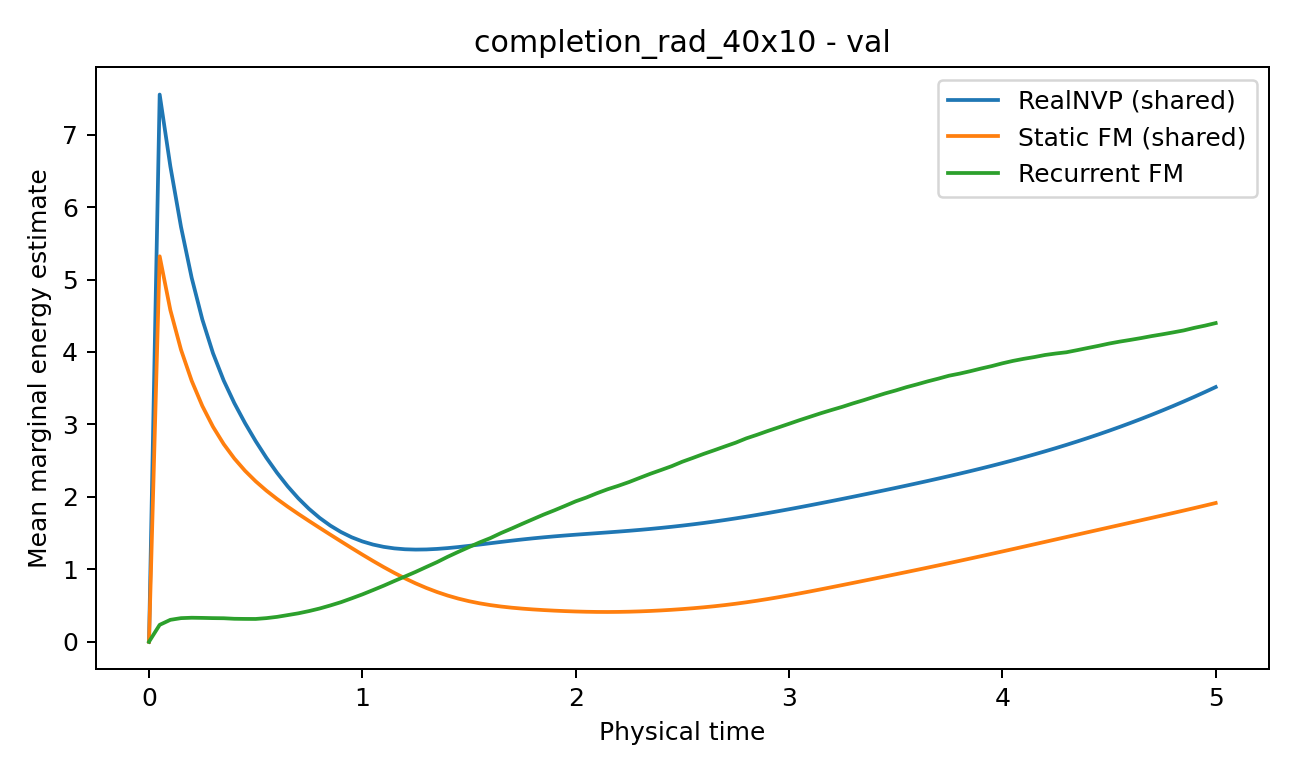


=== SONDA SPAZIALE: MEDIANE E FASCE DEI CAMPIONI ===


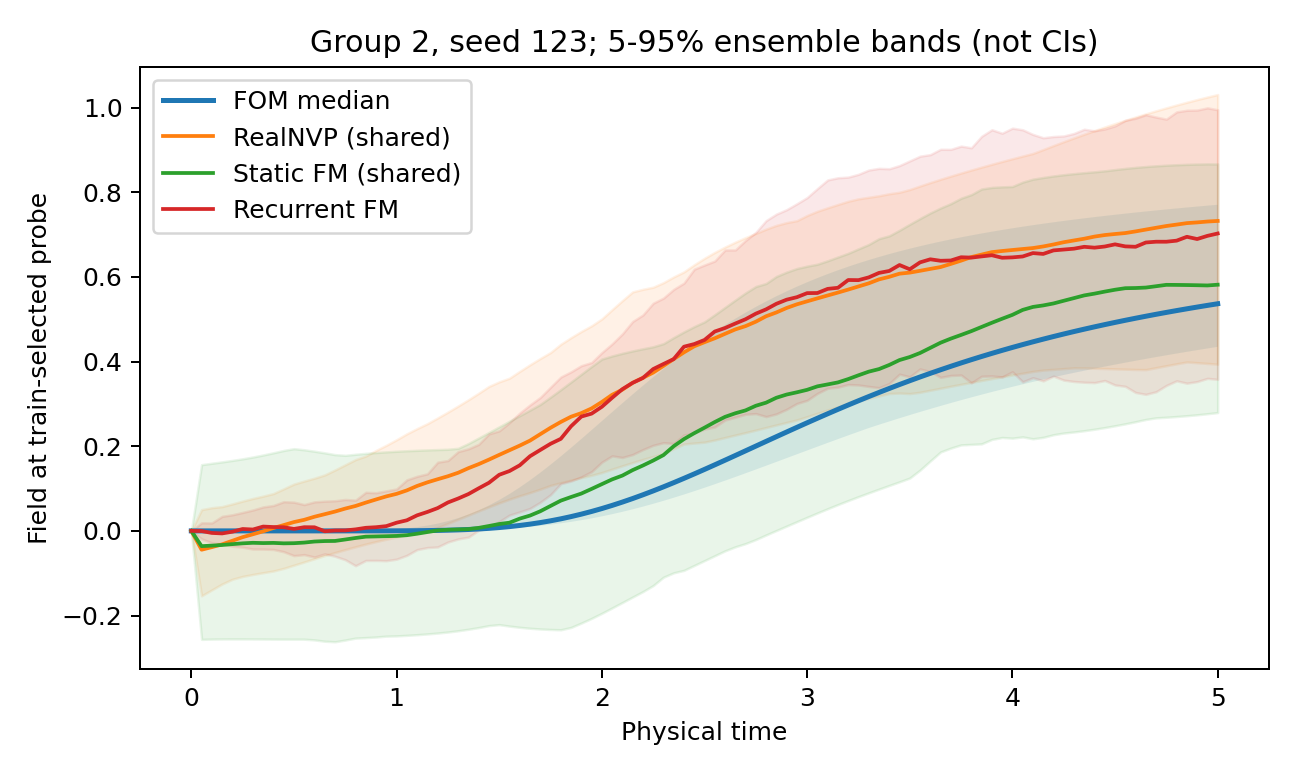


FIGURE DI VALIDATION VISUALIZZATE.


In [41]:
from IPython.display import Image, display

figures = [
    (
        "marginal_energy.png",
        "DISCREPANZA MARGINALE MEDIA NEL TEMPO",
    ),
    (
        "probe_quantiles.png",
        "SONDA SPAZIALE: MEDIANE E FASCE DEI CAMPIONI",
    ),
]

for filename, title in figures:
    path = EVAL_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Figura non trovata: {path}"
        )

    print(f"\n=== {title} ===")
    display(Image(filename=str(path), width=900))

print("\nFIGURE DI VALIDATION VISUALIZZATE.")

### Step 36 — Check repository after runtime change

**Method.** Verify that the local Git checkout and package files still exist after a Colab runtime transition.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [45]:
from pathlib import Path
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

print("=== CONTROLLO DELLA REPOSITORY ===")
print("Repository presente:", REPO_DIR.is_dir())
print(".git presente:", (REPO_DIR / ".git").is_dir())
print(
    "Pacchetto presente:",
    (REPO_DIR / "src" / "spde_surrogates").is_dir()
)
print(
    "Completion presente:",
    (
        REPO_DIR
        / "src"
        / "spde_surrogates"
        / "completion"
    ).is_dir()
)
print("Python:", sys.version)

=== CONTROLLO DELLA REPOSITORY ===
Repository presente: True
.git presente: True
Pacchetto presente: True
Completion presente: True
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


### Step 37 — Restore editable installation

**Method.** Reinstall the restored checkout in editable mode after the runtime transition.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [46]:
import subprocess
import sys

print("=== RIPRISTINO INSTALLAZIONE EDITABLE ===", flush=True)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--disable-pip-version-check",
        "-e",
        ".[test]",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

result.check_returncode()

print("\nINSTALLAZIONE RIPRISTINATA.")

=== RIPRISTINO INSTALLAZIONE EDITABLE ===
Obtaining file:///content/tesi-work/generative-spde-surrogates
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for generative-spde-surrogates (pyproject.toml): started
  Building editable for generative-spde-surrogates (pyproject.toml): finished with status 'done'
  Created wheel for generative-spde-surrogates: filename=generative_spde_surrogates-0.2.0-0.editable-py3-none-any.whl size=1879 sha256=0bdf2c18aeb189a95b9d3cf7710ab1804313ffa56634f288d5af077bcc63b3a1
  Stored in directory: /t

### Step 38 — Revalidate notebook/subprocess imports

**Method.** Confirm both the current kernel and a fresh Python process use the same thesis source tree.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [48]:
from pathlib import Path
import sys
import importlib
import subprocess

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

SRC_DIR = REPO_DIR / "src"

print("=== RIPRISTINO IMPORT NEL NOTEBOOK ===")
print("Repository presente:", REPO_DIR.is_dir())
print("Cartella src presente:", SRC_DIR.is_dir())
print(
    "Pacchetto presente:",
    (SRC_DIR / "spde_surrogates" / "__init__.py").is_file()
)

if not (SRC_DIR / "spde_surrogates" / "__init__.py").is_file():
    raise RuntimeError(
        "Il codice sorgente non e' presente nella posizione prevista. "
        "Fermati e riportami questo output."
    )

# Rende immediatamente visibile il pacchetto al kernel
# Python gia' aperto, senza reinstallare o modificare il codice.
src_string = str(SRC_DIR.resolve())

if src_string not in sys.path:
    sys.path.insert(0, src_string)

importlib.invalidate_caches()

import spde_surrogates

actual = Path(spde_surrogates.__file__).resolve()
expected = (
    SRC_DIR / "spde_surrogates" / "__init__.py"
).resolve()

print("\n=== CONTROLLO IMPORT NEL NOTEBOOK ===")
print("Percorso atteso:", expected)
print("Percorso utilizzato:", actual)
print("Percorso corretto:", actual == expected)

if actual != expected:
    raise RuntimeError(
        "Python sta usando una copia diversa di spde_surrogates."
    )

# Controlliamo anche gli import necessari al Passo 14.
from spde_surrogates.completion.common import (
    as_numpy,
    seed_all,
)
from spde_surrogates.completion.data import (
    load_prepared,
    validate_dataset,
)
from spde_surrogates.completion.dynamic import (
    load_dynamic,
)
from spde_surrogates.completion.metrics import (
    physical_energy,
    diagnostics,
)
from spde_surrogates.data.dataset import (
    load_fom_dataset,
)

print("\nIMPORT DI TUTTI I MODULI DEL PASSO 14: OK")

# Un nuovo processo Python dovrebbe inoltre vedere
# l'installazione editable fatta con pip.
check = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import spde_surrogates; "
            "print(spde_surrogates.__file__)"
        ),
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print("\n=== CONTROLLO NUOVO PROCESSO PYTHON ===")
print(check.stdout.strip())

if check.stderr:
    print(check.stderr)

if check.returncode != 0:
    raise RuntimeError(
        "Il notebook ora vede il pacchetto, ma i nuovi processi "
        "Python no. Incollami questo output prima di proseguire."
    )

print("\nAMBIENTE RIPRISTINATO CORRETTAMENTE.")

=== RIPRISTINO IMPORT NEL NOTEBOOK ===
Repository presente: True
Cartella src presente: True
Pacchetto presente: True

=== CONTROLLO IMPORT NEL NOTEBOOK ===
Percorso atteso: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Percorso utilizzato: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Percorso corretto: True

IMPORT DI TUTTI I MODULI DEL PASSO 14: OK

=== CONTROLLO NUOVO PROCESSO PYTHON ===
/content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py

AMBIENTE RIPRISTINATO CORRETTAMENTE.


### Step 39 — Set up sampler sensitivity

**Method.** Keep the trained dynamic checkpoint fixed and compare Euler-20, Heun-10, and Euler-40 samplers.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [49]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import torch
import yaml

from spde_surrogates.completion.common import as_numpy, seed_all
from spde_surrogates.completion.data import (
    load_prepared,
    validate_dataset,
)
from spde_surrogates.completion.dynamic import load_dynamic
from spde_surrogates.completion.metrics import (
    physical_energy,
    diagnostics,
)
from spde_surrogates.data.dataset import load_fom_dataset


REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"

DYNAMIC_CHECKPOINT = (
    RAD_OUT
    / "models"
    / "dynamic_s123"
    / "best.pt"
)

BASELINE_RESULTS = (
    RAD_OUT
    / "evaluation_val"
    / "results.json"
)


# -------------------------
# Controllo file necessari
# -------------------------

for path in (
    RAD_CONFIG,
    DYNAMIC_CHECKPOINT,
    BASELINE_RESULTS,
    RAD_OUT / "prepared.pt",
):
    if not path.is_file():
        raise FileNotFoundError(
            f"File necessario non trovato: {path}"
        )


# -------------------------
# Configurazione
# -------------------------

with RAD_CONFIG.open(encoding="utf-8") as stream:
    cfg = yaml.safe_load(stream)


prepared = load_prepared(cfg)

dataset = load_fom_dataset(
    cfg["data"]["path"]
)

validate_dataset(
    dataset,
    cfg,
)


mu_bank, times, mus, reference, groups = dataset


# -------------------------
# Gruppi di validation
# -------------------------

val_ids = as_numpy(
    prepared["split"]["val_indices"]
).astype(int)

VAL_GROUPS = sorted(
    int(x)
    for x in np.unique(groups[val_ids])
)

if VAL_GROUPS != [2, 10, 12, 30, 33, 37]:
    raise RuntimeError(
        f"Gruppi inattesi: {VAL_GROUPS}"
    )


# -------------------------
# Cartella risultati
# -------------------------

SENSITIVITY_DIR = (
    RAD_OUT
    / "dynamic_sampling_sensitivity"
)

SENSITIVITY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# -------------------------
# Sampler da confrontare
# -------------------------

SAMPLERS = {
    "heun10": {
        "n_steps": 10,
        "solver": "heun",
    },

    "euler40": {
        "n_steps": 40,
        "solver": "euler",
    },
}


print("=== SENSITIVITY DEL SAMPLER DINAMICO ===")
print("Gruppi di validation:", VAL_GROUPS)
print(
    "Campioni per gruppo:",
    cfg["evaluation"]["n_generated"],
)
print("Checkpoint:", DYNAMIC_CHECKPOINT)

print("\nSampler:")
print("Baseline : Euler 20")
print("Test A   : Heun 10")
print("Test B   : Euler 40")

print("\nOutput:", SENSITIVITY_DIR)

print(
    "\nNESSUN MODELLO VERRA' RIADDESTRATO."
)

=== SENSITIVITY DEL SAMPLER DINAMICO ===
Gruppi di validation: [2, 10, 12, 30, 33, 37]
Campioni per gruppo: 100
Checkpoint: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/models/dynamic_s123/best.pt

Sampler:
Baseline : Euler 20
Test A   : Heun 10
Test B   : Euler 40

Output: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/dynamic_sampling_sensitivity

NESSUN MODELLO VERRA' RIADDESTRATO.


### Step 40 — Run alternative samplers

**Method.** Evaluate the alternative artificial-time ODE solvers on the same validation groups.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [50]:
N_GENERATED = int(
    cfg["evaluation"]["n_generated"]
)

EVAL_SEED = int(
    cfg["evaluation"]["seed"]
)

THREADS = int(
    cfg["experiment"].get(
        "threads",
        1,
    )
)

u0 = as_numpy(
    prepared["initial_field"]
)


rows = []


# =========================================================
# Valutazione sui sei gruppi di validation
# =========================================================

for variant_name, sampling_cfg in SAMPLERS.items():

    print(
        f"\n{'=' * 60}"
    )
    print(
        f"SAMPLER: {variant_name}"
    )
    print(
        f"Configurazione: {sampling_cfg}"
    )
    print(
        f"{'=' * 60}",
        flush=True,
    )

    surrogate, info = load_dynamic(
        DYNAMIC_CHECKPOINT,
        device="cpu",
    )

    # Sovrascriviamo SOLTANTO il sampler di inferenza.
    # I pesi della rete restano identici.
    surrogate.sampling_config = dict(
        sampling_cfg
    )


    for group in VAL_GROUPS:

        # Tutte le 10 traiettorie FOM del gruppo
        ids = np.flatnonzero(
            groups == group
        )

        real = reference[ids]

        # Tutte le traiettorie del gruppo
        # condividono lo stesso mu.
        mu = mus[ids[0]]


        # Stessa logica di seed usata nella
        # valutazione principale.
        eval_seed = (
            EVAL_SEED
            + 1009 * int(group)
        )

        seed_all(
            eval_seed,
            THREADS,
        )


        # -------------------------
        # Generazione dinamica
        # -------------------------

        Cg = surrogate.sample_coefficients(
            mu,
            times,
            n_samples=N_GENERATED,
            temporal_coupling="autoregressive",
            seed=eval_seed,
        )


        # Ricostruzione fisica
        Ug = surrogate.pod.inverse_transform(
            Cg
        )


        # -------------------------
        # Condizione iniziale
        # -------------------------

        Ug[:, 0] = u0

        Cg = Cg.copy()

        Cg[:, 0] = surrogate.pod.transform(
            u0[None]
        )[0]


        # -------------------------
        # Coefficienti FOM
        # -------------------------

        Cr = surrogate.pod.transform(
            real
        )


        # -------------------------
        # Diagnostiche
        # -------------------------

        diag = diagnostics(
            real,
            Ug,
            Cr,
            Cg,
        )


        # Metrica principale:
        # full physical trajectory
        d2 = physical_energy(
            real,
            Cg,
            surrogate.pod,
            hard_initial=True,
        )


        row = {
            "variant": variant_name,
            "group": int(group),
            "n_reference": int(len(real)),
            "n_generated": int(N_GENERATED),
            "energy_physical": float(d2),
            **diag,
        }

        rows.append(row)


        print(
            f"gruppo {group:2d}: "
            f"energy_physical = {d2:.6f}",
            flush=True,
        )


# =========================================================
# Benchmark del costo online
# =========================================================

benchmark_group = VAL_GROUPS[0]

ids = np.flatnonzero(
    groups == benchmark_group
)

mu = mus[ids[0]]


print(
    "\n=== BENCHMARK DEL COSTO ONLINE ===",
    flush=True,
)


for variant_name, sampling_cfg in SAMPLERS.items():

    surrogate, _ = load_dynamic(
        DYNAMIC_CHECKPOINT,
        device="cpu",
    )

    surrogate.sampling_config = dict(
        sampling_cfg
    )

    durations = []

    n_warmup = int(
        cfg["evaluation"]["benchmark_warmup"]
    )

    n_repeats = int(
        cfg["evaluation"]["benchmark_repeats"]
    )

    total_repetitions = (
        n_warmup
        + n_repeats
    )


    for rep in range(total_repetitions):

        run_seed = (
            EVAL_SEED
            + 1009 * benchmark_group
            + rep
        )

        seed_all(
            run_seed,
            THREADS,
        )


        start = perf_counter()


        Cg = surrogate.sample_coefficients(
            mu,
            times,
            n_samples=N_GENERATED,
            temporal_coupling="autoregressive",
            seed=run_seed,
        )


        Ug = surrogate.pod.inverse_transform(
            Cg
        )

        Ug[:, 0] = u0


        elapsed = (
            perf_counter()
            - start
        )


        if rep >= n_warmup:
            durations.append(
                elapsed
            )


    median_seconds = float(
        np.median(durations)
    )


    # Salviamo il benchmark nelle righe
    # della variante corrispondente.
    for row in rows:

        if (
            row["variant"]
            == variant_name
        ):
            row[
                "online_median_seconds"
            ] = median_seconds


    print(
        f"{variant_name}: "
        f"{median_seconds:.6f} s "
        f"per {N_GENERATED} traiettorie"
    )


# =========================================================
# Salvataggio
# =========================================================

RESULT_PATH = (
    SENSITIVITY_DIR
    / "sampling_sensitivity.json"
)


result_document = {
    "checkpoint": str(
        DYNAMIC_CHECKPOINT
    ),

    "split": "validation",

    "n_generated": (
        N_GENERATED
    ),

    "baseline_sampler": {
        "n_steps": 20,
        "solver": "euler",
    },

    "tested_samplers": (
        SAMPLERS
    ),

    "rows": rows,
}


RESULT_PATH.write_text(
    json.dumps(
        result_document,
        indent=2,
    ),
    encoding="utf-8",
)


print(
    "\nSENSITIVITY COMPLETATA."
)

print(
    "Risultati salvati:",
    RESULT_PATH,
)


SAMPLER: heun10
Configurazione: {'n_steps': 10, 'solver': 'heun'}
gruppo  2: energy_physical = 31.394186
gruppo 10: energy_physical = 35.844964
gruppo 12: energy_physical = 26.304345
gruppo 30: energy_physical = 14.209643
gruppo 33: energy_physical = 24.029687
gruppo 37: energy_physical = 29.796736

SAMPLER: euler40
Configurazione: {'n_steps': 40, 'solver': 'euler'}
gruppo  2: energy_physical = 31.377944
gruppo 10: energy_physical = 35.870593
gruppo 12: energy_physical = 26.302421
gruppo 30: energy_physical = 14.164207
gruppo 33: energy_physical = 24.033335
gruppo 37: energy_physical = 29.751760

=== BENCHMARK DEL COSTO ONLINE ===
heun10: 1.923091 s per 100 traiettorie
euler40: 3.329272 s per 100 traiettorie

SENSITIVITY COMPLETATA.
Risultati salvati: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/dynamic_sampling_sensitivity/sampling_sensitivity.json


### Step 41 — Interpret sampler sensitivity

**Method.** Compare accuracy and runtime to determine whether the FM numerical solver explains late-time errors.

**Comment on the stored result.** Euler-20, Heun-10, and Euler-40 give nearly identical trajectory energy (~26.91), increment error (~0.163), and covariance error (~0.789). Therefore the late-time degradation is not mainly a numerical ODE-solver artifact.


In [51]:
# =========================================================
# Baseline Euler20 già calcolata
# =========================================================

baseline_document = json.loads(
    BASELINE_RESULTS.read_text(
        encoding="utf-8"
    )
)


baseline_rows = [
    row
    for row in baseline_document["rows"]
    if row["model"] == "dynamic"
]


if len(baseline_rows) != 6:
    raise RuntimeError(
        "La baseline dinamica dovrebbe "
        "contenere 6 gruppi di validation."
    )


# =========================================================
# Nuove varianti
# =========================================================

sensitivity_document = json.loads(
    RESULT_PATH.read_text(
        encoding="utf-8"
    )
)

new_rows = (
    sensitivity_document["rows"]
)


# =========================================================
# Funzione di riepilogo
# =========================================================

def summarize(rows_subset):

    if len(rows_subset) != 6:
        raise RuntimeError(
            "Ogni variante deve avere "
            "esattamente 6 gruppi."
        )

    return {

        "energy": float(
            np.mean([
                row["energy_physical"]
                for row in rows_subset
            ])
        ),

        "increment": float(
            np.mean([
                row["increment_energy"]
                for row in rows_subset
            ])
        ),

        "covariance": float(
            np.mean([
                row[
                    "temporal_covariance_relative_error"
                ]
                for row in rows_subset
            ])
        ),

        "mean_error": float(
            np.mean([
                row[
                    "mean_relative_error"
                ]
                for row in rows_subset
            ])
        ),

        "std_error": float(
            np.mean([
                row[
                    "std_relative_error"
                ]
                for row in rows_subset
            ])
        ),

        "time": next(
            (
                row[
                    "online_median_seconds"
                ]
                for row in rows_subset
                if row.get(
                    "online_median_seconds"
                ) is not None
            ),
            None,
        ),
    }


# =========================================================
# Riepiloghi
# =========================================================

summaries = {
    "euler20": summarize(
        baseline_rows
    ),
}


for variant in SAMPLERS:

    summaries[variant] = summarize([
        row
        for row in new_rows
        if row["variant"] == variant
    ])


baseline_energy = (
    summaries["euler20"]["energy"]
)


# =========================================================
# Tabella aggregata
# =========================================================

print(
    "=== SENSITIVITY DEL MODELLO DINAMICO ==="
)

print(
    "Sampler   | energy   | delta vs Euler20 | "
    "increment | cov.error | tempo [s]"
)

print(
    "-" * 82
)


for name in (
    "euler20",
    "heun10",
    "euler40",
):

    s = summaries[name]

    delta = (
        100
        * (
            s["energy"]
            - baseline_energy
        )
        / baseline_energy
    )

    print(
        f"{name:9s} | "
        f"{s['energy']:8.4f} | "
        f"{delta:+15.2f}% | "
        f"{s['increment']:9.4f} | "
        f"{s['covariance']:9.4f} | "
        f"{s['time']:9.4f}"
    )


# =========================================================
# Dettaglio per gruppo
# =========================================================

print(
    "\n=== ENERGY_PHYSICAL PER GRUPPO ==="
)

print(
    "Gruppo | Euler20  | Heun10   | Euler40"
)

print(
    "-" * 46
)


for group in VAL_GROUPS:

    baseline = next(
        row["energy_physical"]
        for row in baseline_rows
        if int(row["group"]) == group
    )

    h10 = next(
        row["energy_physical"]
        for row in new_rows
        if (
            row["variant"]
            == "heun10"
            and int(row["group"])
            == group
        )
    )

    e40 = next(
        row["energy_physical"]
        for row in new_rows
        if (
            row["variant"]
            == "euler40"
            and int(row["group"])
            == group
        )
    )

    print(
        f"{group:6d} | "
        f"{baseline:8.4f} | "
        f"{h10:8.4f} | "
        f"{e40:8.4f}"
    )


# =========================================================
# Controllo automatico
# =========================================================

best_sampler = min(
    summaries,
    key=lambda key:
        summaries[key]["energy"]
)

best_energy = (
    summaries[
        best_sampler
    ]["energy"]
)

improvement = (
    100
    * (
        baseline_energy
        - best_energy
    )
    / baseline_energy
)


print(
    "\n=== RISULTATO DEL CONTROLLO ==="
)

print(
    "Sampler con energy media minore:",
    best_sampler,
)

print(
    "Energy media migliore:",
    f"{best_energy:.6f}",
)

print(
    "Miglioramento rispetto a Euler20:",
    f"{improvement:.2f}%",
)


print(
    "\nNESSUNA CONFIGURAZIONE FINALE "
    "E' STATA ANCORA SCELTA."
)

=== SENSITIVITY DEL MODELLO DINAMICO ===
Sampler   | energy   | delta vs Euler20 | increment | cov.error | tempo [s]
----------------------------------------------------------------------------------
euler20   |  26.9060 |           +0.00% |    0.1629 |    0.7894 |    1.8486
heun10    |  26.9299 |           +0.09% |    0.1633 |    0.7890 |    1.9231
euler40   |  26.9167 |           +0.04% |    0.1631 |    0.7892 |    3.3293

=== ENERGY_PHYSICAL PER GRUPPO ===
Gruppo | Euler20  | Heun10   | Euler40
----------------------------------------------
     2 |  31.3641 |  31.3942 |  31.3779
    10 |  35.8953 |  35.8450 |  35.8706
    12 |  26.3027 |  26.3043 |  26.3024
    30 |  14.1222 |  14.2096 |  14.1642
    33 |  24.0388 |  24.0297 |  24.0333
    37 |  29.7126 |  29.7967 |  29.7518

=== RISULTATO DEL CONTROLLO ===
Sampler con energy media minore: euler20
Energy media migliore: 26.905959
Miglioramento rispetto a Euler20: 0.00%

NESSUNA CONFIGURAZIONE FINALE E' STATA ANCORA SCELTA.


### Step 42 — Record final RAD dynamic settings

**Method.** Store the selected checkpoint, Euler solver, and number of FM steps as the final first-case configuration.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [52]:
from pathlib import Path
from datetime import datetime, timezone
import json
import yaml

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"

SENSITIVITY_PATH = (
    RAD_OUT
    / "dynamic_sampling_sensitivity"
    / "sampling_sensitivity.json"
)

DECISION_PATH = (
    RAD_OUT
    / "DYNAMIC_MODEL_SELECTION.json"
)

if not RAD_CONFIG.is_file():
    raise FileNotFoundError(RAD_CONFIG)

if not SENSITIVITY_PATH.is_file():
    raise FileNotFoundError(SENSITIVITY_PATH)


with RAD_CONFIG.open(
    encoding="utf-8"
) as stream:
    cfg = yaml.safe_load(stream)


# Controllo che la configurazione finale
# sia ancora Euler20.
dynamic_sampling = cfg["dynamic"]["sampling"]

if dynamic_sampling != {
    "n_steps": 20,
    "solver": "euler",
}:
    raise RuntimeError(
        "La configurazione dinamica non e' Euler20. "
        "Non congelare il test."
    )


sensitivity = json.loads(
    SENSITIVITY_PATH.read_text(
        encoding="utf-8"
    )
)


decision = {
    "timestamp_utc": (
        datetime.now(timezone.utc)
        .isoformat()
    ),

    "selected_dynamic_checkpoint": (
        str(
            RAD_OUT
            / "models"
            / "dynamic_s123"
            / "best.pt"
        )
    ),

    "selected_epoch": 15,

    "selected_sampler": {
        "solver": "euler",
        "n_steps": 20,
    },

    "validation_energy": {
        "euler20": 26.905959,
        "heun10": 26.9299,
        "euler40": 26.9167,
    },

    "validation_online_seconds": {
        "euler20": 1.8486,
        "heun10": 1.9231,
        "euler40": 3.3293,
    },

    "decision": (
        "Keep Euler with 20 artificial-time steps. "
        "Heun10 and Euler40 do not provide a meaningful "
        "improvement in validation trajectory energy. "
        "The long-horizon discrepancy is therefore not "
        "primarily attributed to the numerical FM sampler."
    ),

    "no_more_tuning_on_rad_validation": True,
}


if DECISION_PATH.exists():

    existing = json.loads(
        DECISION_PATH.read_text(
            encoding="utf-8"
        )
    )

    # Il timestamp può ovviamente essere diverso.
    comparable_existing = dict(existing)
    comparable_new = dict(decision)

    comparable_existing.pop(
        "timestamp_utc",
        None,
    )

    comparable_new.pop(
        "timestamp_utc",
        None,
    )

    if comparable_existing != comparable_new:
        raise RuntimeError(
            "Esiste gia' una decisione finale diversa. "
            "Non sovrascriverla."
        )

    print(
        "Decisione finale gia' registrata "
        "e compatibile."
    )

else:

    DECISION_PATH.write_text(
        json.dumps(
            decision,
            indent=2,
        ),
        encoding="utf-8",
    )

    print(
        "Decisione finale registrata."
    )


print("\n=== CONFIGURAZIONE DINAMICA FINALE ===")
print("Checkpoint: dynamic_s123/best.pt")
print("Epoca selezionata: 15")
print("Solver: Euler")
print("Passi FM per transizione: 20")
print("Ulteriore tuning sul primo caso: NO")
print("\nDocumento:", DECISION_PATH)

Decisione finale registrata.

=== CONFIGURAZIONE DINAMICA FINALE ===
Checkpoint: dynamic_s123/best.pt
Epoca selezionata: 15
Solver: Euler
Passi FM per transizione: 20
Ulteriore tuning sul primo caso: NO

Documento: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/DYNAMIC_MODEL_SELECTION.json


### Step 43 — Freeze the RAD test

**Method.** Serialize the final test plan before opening the held-out test groups.

**Comment on the stored result.** The first benchmark is frozen before test evaluation, so subsequent test values are genuinely held out.


In [53]:
import subprocess
import sys
from pathlib import Path

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

RAD_CONFIG = RAD_OUT / "config_colab.yaml"

FROZEN_PLAN = (
    RAD_OUT
    / "FROZEN_TEST_PLAN.json"
)


print("=== CONGELAMENTO DEL TEST ===")


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "freeze",

    "--config",
    str(RAD_CONFIG),

    "--models",
    "realnvp",
    "flow_matching",
    "dynamic",

    "--seeds",
    "123",
]


result = subprocess.run(
    command,
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)


print(result.stdout)

if result.stderr:
    print(result.stderr)


if result.returncode != 0:
    raise RuntimeError(
        "Freeze non riuscito. "
        "Non procedere al test."
    )


if not FROZEN_PLAN.is_file():
    raise RuntimeError(
        "FROZEN_TEST_PLAN.json non trovato."
    )


print(
    "Piano congelato:",
    FROZEN_PLAN,
)

print(
    "\nDA QUESTO MOMENTO IL PRIMO "
    "TEST CASE NON VIENE PIU' TUNATO."
)

=== CONGELAMENTO DEL TEST ===
Frozen test plan: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/FROZEN_TEST_PLAN.json

Piano congelato: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/FROZEN_TEST_PLAN.json

DA QUESTO MOMENTO IL PRIMO TEST CASE NON VIENE PIU' TUNATO.


### Step 44 — Run the final RAD test

**Method.** Evaluate the frozen models on the six held-out advection-diffusion parameter groups.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [54]:
from datetime import datetime, timezone

TEST_DIR = (
    RAD_OUT
    / "evaluation_test"
)

stamp = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%d_%H%M%S_%fZ")
)

TEST_LOG = (
    RAD_OUT
    / f"confronto_test_finale_{stamp}.log"
)


# Evitiamo di sovrascrivere un test
# eventualmente già completato.
if (
    TEST_DIR
    / "results.json"
).is_file():

    print(
        "results.json del test esiste gia'."
    )

    print(
        "Non rigenero il test. "
        "Passa alla cella 15.4."
    )

else:

    commands = [

        [
            "evaluate",

            "--models",
            "realnvp",
            "flow_matching",
            "dynamic",

            "--seeds",
            "123",

            "--device",
            "cpu",

            "--split",
            "test",
        ],

        [
            "report",
            "--split",
            "test",
        ],
    ]


    print(
        "=== VALUTAZIONE FINALE SUL TEST ===",
        flush=True,
    )

    print(
        "Log:",
        TEST_LOG,
        flush=True,
    )


    with TEST_LOG.open(
        "x",
        encoding="utf-8",
    ) as log:

        for arguments in commands:

            command = [
                sys.executable,
                "-u",
                "-m",
                "spde_surrogates.completion.cli",
                *arguments,
                "--config",
                str(RAD_CONFIG),
            ]

            heading = (
                "\n=== "
                + arguments[0].upper()
                + " / TEST ===\n"
            )

            print(
                heading,
                end="",
                flush=True,
            )

            log.write(
                heading
            )

            log.flush()


            process = subprocess.Popen(
                command,
                cwd=REPO_DIR,
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
                bufsize=1,
            )


            try:

                for line in process.stdout:

                    print(
                        line,
                        end="",
                        flush=True,
                    )

                    log.write(
                        line
                    )

                    log.flush()


                return_code = (
                    process.wait()
                )


            finally:

                process.stdout.close()


            if return_code != 0:

                raise RuntimeError(
                    "Errore durante "
                    f"{arguments[0]}. "
                    f"Log: {TEST_LOG}"
                )


    print(
        "\nTEST FINALE COMPLETATO."
    )

=== VALUTAZIONE FINALE SUL TEST ===
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/rad_40x10/confronto_test_finale_20261012_101659_852439Z.log

=== EVALUATE / TEST ===
test realnvp_shared_s123_g5: full-field energy=12.6747
test realnvp_shared_s123_g8: full-field energy=19.7787
test realnvp_shared_s123_g13: full-field energy=24.474
test realnvp_shared_s123_g18: full-field energy=15.6509
test realnvp_shared_s123_g32: full-field energy=15.9162
test realnvp_shared_s123_g38: full-field energy=23.0873
test realnvp_independent_s123_g5: full-field energy=14.4228
test realnvp_independent_s123_g8: full-field energy=18.8211
test realnvp_independent_s123_g13: full-field energy=23.7199
test realnvp_independent_s123_g18: full-field energy=16.2749
test realnvp_independent_s123_g32: full-field energy=15.6388
test realnvp_independent_s123_g38: full-field energy=22.8925
test realnvp_shared_raw_s123_g5: full-field energy=13.3492
test realnvp_shared_raw_s123_g8: full-field energy=20.3999
test rea

### Step 45 — Summarize final RAD results

**Method.** Aggregate the final held-out trajectory, increment, covariance, and timing metrics.

**Comment on the stored result.** Final RAD test: Static FM has the best trajectory energy (7.75483) versus RealNVP (18.59696) and Recurrent FM (21.66954), and it wins all six test groups. Recurrent FM has the best increment (0.16463) and covariance (0.72970) diagnostics.


In [55]:
import json
import numpy as np

TEST_DIR = (
    RAD_OUT
    / "evaluation_test"
)

RESULTS_PATH = (
    TEST_DIR
    / "results.json"
)

SUMMARY_PATH = (
    TEST_DIR
    / "summary.json"
)


for path in (
    RESULTS_PATH,
    SUMMARY_PATH,
    TEST_DIR / "summary.csv",
    TEST_DIR / "comparison_table.tex",
    TEST_DIR / "REPORT.md",
    TEST_DIR / "marginal_energy.png",
    TEST_DIR / "probe_quantiles.png",
):

    if (
        not path.is_file()
        or path.stat().st_size == 0
    ):

        raise RuntimeError(
            f"Output mancante: {path}"
        )


result = json.loads(
    RESULTS_PATH.read_text(
        encoding="utf-8"
    )
)

summary_document = json.loads(
    SUMMARY_PATH.read_text(
        encoding="utf-8"
    )
)


summaries = {
    row["model"]: row
    for row in summary_document["summary"]
}


MAIN_LABELS = [
    "realnvp_shared",
    "flow_matching_shared",
    "dynamic",
]


def fmt(value):

    if value is None:
        return "n.d."

    return f"{value:.6g}"


print(
    "=== RISULTATO FINALE "
    "DEL PRIMO TEST CASE ==="
)


print(
    "\nGruppi di test:",
    sorted(
        {
            int(row["group"])
            for row in result["rows"]
        }
    ),
)


print(
    "\nModello                 "
    "| Energy traj. | Increment | "
    "Cov.error | Tempo [s]"
)

print(
    "-" * 79
)


for label in MAIN_LABELS:

    s = summaries[label]

    print(
        f"{label:22s} | "
        f"{s['mean_energy']:12.5f} | "
        f"{s['mean_increment_energy']:9.5f} | "
        f"{s['mean_temporal_covariance_relative_error']:9.5f} | "
        f"{s['median_online_seconds']:9.4f}"
    )


print(
    "\n=== ENERGY_PHYSICAL PER GRUPPO ==="
)

groups_test = sorted(
    {
        int(row["group"])
        for row in result["rows"]
    }
)


print(
    "Gruppo | RealNVP | Static FM | Dynamic"
)

print(
    "-" * 47
)


for group in groups_test:

    values = []

    for label in MAIN_LABELS:

        value = next(
            row["energy_physical"]
            for row in result["rows"]
            if (
                row["model"] == label
                and int(row["group"])
                == group
            )
        )

        values.append(
            value
        )


    print(
        f"{group:6d} | "
        f"{values[0]:7.4f} | "
        f"{values[1]:9.4f} | "
        f"{values[2]:7.4f}"
    )


winner = min(
    MAIN_LABELS,
    key=lambda label:
        summaries[label]["mean_energy"]
)


print(
    "\n=== METRICA PRINCIPALE ==="
)

print(
    "Modello con minore trajectory energy:",
    winner,
)

print(
    "Energy media:",
    summaries[winner]["mean_energy"],
)


print(
    "\nReport completo:",
    TEST_DIR / "REPORT.md"
)

print(
    "Tabella LaTeX:",
    TEST_DIR / "comparison_table.tex"
)

print(
    "\nPRIMO TEST CASE SCIENTIFICAMENTE CHIUSO."
)

=== RISULTATO FINALE DEL PRIMO TEST CASE ===

Gruppi di test: [5, 8, 13, 18, 32, 38]

Modello                 | Energy traj. | Increment | Cov.error | Tempo [s]
-------------------------------------------------------------------------------
realnvp_shared         |     18.59696 |   0.57321 |   1.11239 |    1.0292
flow_matching_shared   |      7.75483 |   0.39273 |   1.53402 |    8.7428
dynamic                |     21.66954 |   0.16463 |   0.72970 |    1.9691

=== ENERGY_PHYSICAL PER GRUPPO ===
Gruppo | RealNVP | Static FM | Dynamic
-----------------------------------------------
     5 | 12.6747 |    5.6314 | 15.6651
     8 | 19.7787 |    7.5615 | 21.1074
    13 | 24.4740 |    7.0809 | 20.5898
    18 | 15.6509 |    7.2538 | 20.2908
    32 | 15.9162 |    7.0961 | 25.4302
    38 | 23.0873 |   11.9053 | 26.9339

=== METRICA PRINCIPALE ===
Modello con minore trajectory energy: flow_matching_shared
Energy media: 7.754825189518897

Report completo: /content/drive/MyDrive/Tesi/completamento_d

### Step 46 — Configure the heat benchmark

**Method.** Define the second stochastic benchmark with dynamically evolving additive noise.

**Comment on the stored result.** The second case uses 40 groups x 10 trajectories, 101 time points, 129 spatial points, 16 stochastic modes, and noise amplitude 0.3.


In [56]:
from pathlib import Path
import copy
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

DRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)

BASE_HEAT_CONFIG = (
    REPO_DIR
    / "configs"
    / "completion_heat.yaml"
)

if not BASE_HEAT_CONFIG.is_file():
    raise FileNotFoundError(
        f"Configurazione non trovata: {BASE_HEAT_CONFIG}"
    )

if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        "Google Drive non risulta collegato."
    )


# =========================================================
# Nuova cartella scientifica del secondo caso
# =========================================================

HEAT_OUT = (
    DRIVE_ROOT
    / "Tesi"
    / "completamento_dinamico"
    / "heat_40x10"
)

HEAT_OUT.mkdir(
    parents=True,
    exist_ok=True,
)

HEAT_DATA_DIR = (
    HEAT_OUT
    / "data"
)

HEAT_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

HEAT_DATA = (
    HEAT_DATA_DIR
    / "stochastic_heat_40x10.npz"
)

HEAT_CONFIG = (
    HEAT_OUT
    / "config_heat_colab.yaml"
)


# =========================================================
# Leggiamo la configurazione originale
# =========================================================

with BASE_HEAT_CONFIG.open(
    encoding="utf-8"
) as stream:
    heat_cfg = yaml.safe_load(stream)


# =========================================================
# Controlli: deve essere il caso scientifico,
# non lo smoke test
# =========================================================

expected = {
    "n_mu": 40,
    "n_realizations": 10,
    "steps": 100,
    "n_space": 129,
    "noise_modes": 16,
}

for key, value in expected.items():

    if int(heat_cfg["data"][key]) != value:

        raise RuntimeError(
            f"Configurazione inattesa: "
            f"{key}={heat_cfg['data'][key]}"
        )

if heat_cfg["problem"]["kind"] != "heat":
    raise RuntimeError(
        "Questa non e' la configurazione heat."
    )

if float(heat_cfg["data"]["dt"]) != 0.05:
    raise RuntimeError(
        "dt diverso da 0.05."
    )

if float(heat_cfg["data"]["sigma"]) != 0.3:
    raise RuntimeError(
        "sigma diverso da 0.3."
    )


# =========================================================
# Modifichiamo SOLO i percorsi
# =========================================================

heat_cfg = copy.deepcopy(
    heat_cfg
)

heat_cfg["data"]["path"] = str(
    HEAT_DATA
)

heat_cfg["experiment"]["output_dir"] = str(
    HEAT_OUT
)


# =========================================================
# Non sovrascriviamo configurazioni diverse
# =========================================================

if HEAT_CONFIG.exists():

    with HEAT_CONFIG.open(
        encoding="utf-8"
    ) as stream:
        previous = yaml.safe_load(stream)

    if previous != heat_cfg:

        raise RuntimeError(
            "Esiste gia' una configurazione heat diversa. "
            "Non la sovrascriviamo."
        )

    print(
        "Configurazione identica gia' presente: "
        "riutilizzata."
    )

else:

    with HEAT_CONFIG.open(
        "x",
        encoding="utf-8",
    ) as stream:

        yaml.safe_dump(
            heat_cfg,
            stream,
            sort_keys=False,
        )

    print(
        "Configurazione scientifica heat creata."
    )


print(
    "\n=== SECONDO TEST CASE ==="
)

print(
    "Problema:",
    heat_cfg["problem"]["kind"],
)

print(
    "Gruppi parametrici:",
    heat_cfg["data"]["n_mu"],
)

print(
    "Realizzazioni per gruppo:",
    heat_cfg["data"]["n_realizations"],
)

print(
    "Traiettorie totali:",
    heat_cfg["data"]["n_mu"]
    * heat_cfg["data"]["n_realizations"],
)

print(
    "Istanti:",
    heat_cfg["data"]["steps"] + 1,
)

print(
    "Punti spaziali:",
    heat_cfg["data"]["n_space"],
)

print(
    "Modi del rumore:",
    heat_cfg["data"]["noise_modes"],
)

print(
    "Sigma:",
    heat_cfg["data"]["sigma"],
)

print(
    "Dataset:",
    HEAT_DATA,
)

print(
    "Output scientifici:",
    HEAT_OUT,
)

print(
    "\nCONFIGURAZIONE DEL SECONDO CASO PRONTA."
)

Configurazione scientifica heat creata.

=== SECONDO TEST CASE ===
Problema: heat
Gruppi parametrici: 40
Realizzazioni per gruppo: 10
Traiettorie totali: 400
Istanti: 101
Punti spaziali: 129
Modi del rumore: 16
Sigma: 0.3
Dataset: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/data/stochastic_heat_40x10.npz
Output scientifici: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10

CONFIGURAZIONE DEL SECONDO CASO PRONTA.


### Step 47 — Generate the heat dataset

**Method.** Simulate the finite-rank stochastic heat equation using exact Ornstein-Uhlenbeck modal transitions.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [57]:
import subprocess
import sys
from datetime import datetime, timezone

GENERATION_LOG = (
    HEAT_OUT
    / "heat_generation.log"
)


print(
    "=== GENERAZIONE DEL DATASET HEAT 40x10 ===",
    flush=True,
)

print(
    "400 traiettorie da generare.",
    flush=True,
)

print(
    "Il simulatore non richiede FEniCS.",
    flush=True,
)


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "generate",
    "--config",
    str(HEAT_CONFIG),
]


with GENERATION_LOG.open(
    "a",
    encoding="utf-8",
) as log:

    process = subprocess.Popen(
        command,
        cwd=REPO_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:

        for line in process.stdout:

            print(
                line,
                end="",
                flush=True,
            )

            log.write(
                line
            )

            log.flush()

        return_code = (
            process.wait()
        )

    finally:

        process.stdout.close()


if return_code != 0:

    raise RuntimeError(
        "Generazione interrotta. "
        "Non cancellare la cartella di generazione: "
        "il comando puo' essere ripreso."
    )


if not HEAT_DATA.is_file():

    raise RuntimeError(
        "Il dataset finale non e' stato creato."
    )


print(
    "\nDATASET HEAT GENERATO."
)

print(
    "Percorso:",
    HEAT_DATA,
)

print(
    "Dimensione:",
    f"{HEAT_DATA.stat().st_size / (1024**2):.2f} MiB",
)

print(
    "Log:",
    GENERATION_LOG,
)

=== GENERAZIONE DEL DATASET HEAT 40x10 ===
400 traiettorie da generare.
Il simulatore non richiede FEniCS.
Dataset saved: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/data/stochastic_heat_40x10.npz
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/data/stochastic_heat_40x10.npz

DATASET HEAT GENERATO.
Percorso: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/data/stochastic_heat_40x10.npz
Dimensione: 36.83 MiB
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/heat_generation.log


### Step 48 — Inspect the heat dataset

**Method.** Verify tensor shape, parameter count, balanced group sizes, and the prescribed initial state.

**Comment on the stored result.** The heat dataset has shape (400, 101, 129), two observed parameters, and exactly 10 realizations in each of 40 groups.


In [58]:
print(
    "=== CONTROLLO DATASET HEAT ===",
    flush=True,
)


inspect_result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "spde_surrogates.completion.cli",
        "inspect",
        "--config",
        str(HEAT_CONFIG),
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)


print(
    inspect_result.stdout
)

if inspect_result.stderr:
    print(
        inspect_result.stderr
    )


if inspect_result.returncode != 0:

    raise RuntimeError(
        "Il dataset heat non ha superato "
        "il controllo."
    )


print(
    "\nDATASET HEAT VERIFICATO."
)

=== CONTROLLO DATASET HEAT ===
{'shape': [400, 101, 129], 'n_parameters': 2, 'n_groups': 40, 'group_sizes': {'0': 10, '1': 10, '2': 10, '3': 10, '4': 10, '5': 10, '6': 10, '7': 10, '8': 10, '9': 10, '10': 10, '11': 10, '12': 10, '13': 10, '14': 10, '15': 10, '16': 10, '17': 10, '18': 10, '19': 10, '20': 10, '21': 10, '22': 10, '23': 10, '24': 10, '25': 10, '26': 10, '27': 10, '28': 10, '29': 10, '30': 10, '31': 10, '32': 10, '33': 10, '34': 10, '35': 10, '36': 10, '37': 10, '38': 10, '39': 10}, 'initial_max_abs': 0.0}


DATASET HEAT VERIFICATO.


### Step 49 — Fit heat POD/preprocessing

**Method.** Fit the POD basis and normalization on training groups only and transform validation/test with the fixed representation.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [59]:
PREPARE_LOG = (
    HEAT_OUT
    / "heat_preparation.log"
)


print(
    "=== PREPARAZIONE POD DEL SECONDO CASO ===",
    flush=True,
)


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "prepare",
    "--config",
    str(HEAT_CONFIG),
]


with PREPARE_LOG.open(
    "a",
    encoding="utf-8",
) as log:

    process = subprocess.Popen(
        command,
        cwd=REPO_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:

        for line in process.stdout:

            print(
                line,
                end="",
                flush=True,
            )

            log.write(
                line
            )

            log.flush()

        return_code = (
            process.wait()
        )

    finally:

        process.stdout.close()


if return_code != 0:

    raise RuntimeError(
        "Preparazione POD interrotta. "
        f"Controlla il log: {PREPARE_LOG}"
    )


print(
    "\nPREPARAZIONE HEAT COMPLETATA."
)

=== PREPARAZIONE POD DEL SECONDO CASO ===
Prepared once: r=6, groups train/val/test=28/6/6
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/prepared.pt

PREPARAZIONE HEAT COMPLETATA.


### Step 50 — Quantify heat POD accuracy

**Method.** Report retained modes, captured energy, compression, and reconstruction errors on train/validation/test.

**Comment on the stored result.** Only six POD modes are needed. They capture about 99.9786% of training snapshot energy; trajectory reconstruction error is ~0.86% train, ~0.99% validation, and ~0.89% test, so POD truncation is small.


In [60]:
import json
import torch

HEAT_PREPARED = (
    HEAT_OUT
    / "prepared.pt"
)

HEAT_PREPARATION = (
    HEAT_OUT
    / "preparation.json"
)


for path in (
    HEAT_PREPARED,
    HEAT_PREPARATION,
):

    if not path.is_file():

        raise FileNotFoundError(
            path
        )


prepared_heat = torch.load(
    HEAT_PREPARED,
    map_location="cpu",
    weights_only=True,
)


diagnostics_heat = json.loads(
    HEAT_PREPARATION.read_text(
        encoding="utf-8"
    )
)


n_modes = int(
    prepared_heat["pod"]["n_modes"]
)

coeff_shape = tuple(
    prepared_heat["coefficients"].shape
)

split_counts = [
    len(
        prepared_heat[
            "split"
        ][f"{part}_groups"]
    )
    for part in (
        "train",
        "val",
        "test",
    )
]


print(
    "=== POD DEL SECONDO TEST CASE ==="
)

print(
    "Numero di modi selezionati:",
    n_modes,
)

print(
    "Forma coefficienti:",
    coeff_shape,
)

print(
    "Gruppi train / val / test:",
    split_counts,
)


print(
    "\n=== ERRORI DI RICOSTRUZIONE POD ==="
)

for part in (
    "train",
    "val",
    "test",
):

    print(
        f"\n{part.upper()}:"
    )

    for key, value in (
        diagnostics_heat[
            "pod_metrics"
        ][part].items()
    ):

        print(
            f"  {key}: {value}"
        )


print(
    "\nErrore della proiezione dello "
    "stato iniziale:",
    diagnostics_heat[
        "initial_POD_projection_error"
    ],
)


if coeff_shape[:2] != (
    400,
    101,
):

    raise RuntimeError(
        "Forma dei coefficienti inattesa."
    )


if split_counts != [
    28,
    6,
    6,
]:

    raise RuntimeError(
        "Split inatteso."
    )


print(
    "\nSECONDO DATASET E POD VERIFICATI."
)

=== POD DEL SECONDO TEST CASE ===
Numero di modi selezionati: 6
Forma coefficienti: (400, 101, 6)
Gruppi train / val / test: [28, 6, 6]

=== ERRORI DI RICOSTRUZIONE POD ===

TRAIN:
  absolute_error: 20.68994453370966
  relative_error: 0.007354784224174334
  trajectory_relative_error: 0.00855154641041049
  n_dofs: 129
  n_modes: 6
  compression_factor: 21.5
  reduced_fraction: 0.046511627906976744
  cumulative_energy: 0.9997860103777201

VAL:
  absolute_error: 10.818404836898122
  relative_error: 0.007342906959751013
  trajectory_relative_error: 0.009876189550800447
  n_dofs: 129
  n_modes: 6
  compression_factor: 21.5
  reduced_fraction: 0.046511627906976744
  cumulative_energy: 0.9997860103777201

TEST:
  absolute_error: 8.511266731366181
  relative_error: 0.007336347765745146
  trajectory_relative_error: 0.008939032844514368
  n_dofs: 129
  n_modes: 6
  compression_factor: 21.5
  reduced_fraction: 0.046511627906976744
  cumulative_energy: 0.9997860103777201

Errore della proiezione d

### Step 51 — Diagnose Drive after reset

**Method.** Check whether missing paths are caused by an unmounted Drive rather than data loss.

**Comment on the stored result.** The apparent missing files are traced to Drive being unmounted, not to lost scientific data.


In [3]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

HEAT_CONFIG = (
    HEAT_OUT / "config_heat_colab.yaml"
)

print("=== DIAGNOSI PERCORSI ===")
print("Google Drive montato:", DRIVE_ROOT.is_dir())
print("Cartella heat_40x10 presente:", HEAT_OUT.is_dir())
print("Config presente:", HEAT_CONFIG.is_file())

if HEAT_OUT.is_dir():
    print("\nContenuto di heat_40x10:")
    for path in sorted(HEAT_OUT.iterdir()):
        print(" -", path.name)

if DRIVE_ROOT.is_dir():
    print("\nRicerca di config_heat_colab.yaml su Drive:")

    matches = list(
        Path("/content/drive/MyDrive").rglob(
            "config_heat_colab.yaml"
        )
    )

    if matches:
        for match in matches:
            print("TROVATO:", match)
    else:
        print("Nessun file con questo nome trovato.")

=== DIAGNOSI PERCORSI ===
Google Drive montato: False
Cartella heat_40x10 presente: False
Config presente: False


### Step 52 — Remount Google Drive

**Method.** Reconnect persistent Drive storage after the Colab reset.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [4]:
from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False,
)

print("DRIVE MONTATO.")

Mounted at /content/drive
DRIVE MONTATO.


### Step 53 — Verify recovered heat files

**Method.** Confirm that the configuration, dataset, prepared POD state, and preparation report are still present.

**Comment on the stored result.** After remounting Drive, all heat configuration, data, and prepared files are recovered successfully.


In [7]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

HEAT_CONFIG = (
    HEAT_OUT / "config_heat_colab.yaml"
)

HEAT_DATA = (
    HEAT_OUT
    / "data"
    / "stochastic_heat_40x10.npz"
)

PREPARED = (
    HEAT_OUT
    / "prepared.pt"
)

PREPARATION = (
    HEAT_OUT
    / "preparation.json"
)

print("=== CONTROLLO DOPO IL MOUNT ===")
print("Google Drive montato:", DRIVE_ROOT.is_dir())
print("Cartella heat_40x10:", HEAT_OUT.is_dir())
print("Config:", HEAT_CONFIG.is_file())
print("Dataset:", HEAT_DATA.is_file())
print("prepared.pt:", PREPARED.is_file())
print("preparation.json:", PREPARATION.is_file())

if HEAT_OUT.is_dir():
    print("\nContenuto cartella heat_40x10:")
    for p in sorted(HEAT_OUT.iterdir()):
        print(" -", p.name)

=== CONTROLLO DOPO IL MOUNT ===
Google Drive montato: True
Cartella heat_40x10: True
Config: True
Dataset: True
prepared.pt: True
preparation.json: True

Contenuto cartella heat_40x10:
 - config_heat_colab.yaml
 - data
 - heat_generation.log
 - heat_preparation.log
 - preparation.json
 - prepared.pt


### Step 54 — Restore repository from backup

**Method.** Recover the ephemeral Git checkout from a verified Drive backup and reinstall the package.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [9]:
from pathlib import Path
import zipfile
import shutil
import subprocess
import sys
import importlib

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

PACKAGE_INIT = (
    REPO_DIR
    / "src"
    / "spde_surrogates"
    / "__init__.py"
)

BACKUP_DIR = Path(
    "/content/drive/MyDrive/Tesi/backup_codice"
)

print("=== RIPRISTINO REPOSITORY ===")
print("Repository presente:", REPO_DIR.is_dir())
print("Pacchetto presente:", PACKAGE_INIT.is_file())


# =========================================================
# Se la repository è sparita, la recuperiamo dal backup
# =========================================================

if not PACKAGE_INIT.is_file():

    # Evitiamo di sovrascrivere una cartella esistente
    # ma incompleta.
    if REPO_DIR.exists():
        raise RuntimeError(
            f"La cartella {REPO_DIR} esiste ma e' incompleta.\n"
            "Non la sovrascrivo automaticamente. "
            "Mandami questo messaggio."
        )

    if not BACKUP_DIR.is_dir():
        raise RuntimeError(
            f"Cartella backup non trovata: {BACKUP_DIR}"
        )

    backups = sorted(
        BACKUP_DIR.glob(
            "codice_completion_*.zip"
        )
    )

    if not backups:
        print("\nZIP presenti nella cartella backup:")
        for p in sorted(BACKUP_DIR.glob("*.zip")):
            print(" -", p)

        raise RuntimeError(
            "Non trovo un backup codice_completion_*.zip."
        )

    # Il nome contiene timestamp, quindi l'ultimo
    # alfabeticamente è il backup più recente.
    backup = backups[-1]

    print("\nBackup scelto:")
    print(backup)

    restore_tmp = Path(
        "/content/repository_restore_tmp"
    )

    if restore_tmp.exists():
        shutil.rmtree(
            restore_tmp
        )

    restore_tmp.mkdir(
        parents=True,
        exist_ok=True,
    )

    print("\nEstrazione backup...")

    with zipfile.ZipFile(
        backup,
        "r",
    ) as zf:
        zf.extractall(
            restore_tmp
        )


    # Cerchiamo automaticamente la root della repo.
    candidates = list(
        restore_tmp.rglob(
            "src/spde_surrogates/__init__.py"
        )
    )

    if len(candidates) != 1:
        print(
            "Candidati trovati:",
            candidates,
        )
        raise RuntimeError(
            "Non riesco a identificare "
            "univocamente la repository nel backup."
        )

    source_root = (
        candidates[0]
        .parents[2]
    )

    print(
        "Repository trovata nel backup:",
        source_root,
    )


    REPO_DIR.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    shutil.move(
        str(source_root),
        str(REPO_DIR),
    )

    print(
        "\nRepository ripristinata in:",
        REPO_DIR,
    )


# =========================================================
# Controlli minimi del codice
# =========================================================

required = [
    REPO_DIR / ".git",
    REPO_DIR / "pyproject.toml",
    REPO_DIR / "src" / "spde_surrogates",
    REPO_DIR / "src" / "spde_surrogates" / "completion",
    REPO_DIR / "configs" / "completion_heat.yaml",
]

for path in required:
    if not path.exists():
        raise RuntimeError(
            f"Elemento necessario mancante: {path}"
        )


# =========================================================
# Reinstallazione editable nel NUOVO runtime
# =========================================================

print(
    "\n=== REINSTALLAZIONE DEL PACCHETTO ===",
    flush=True,
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--disable-pip-version-check",
        "-e",
        ".[test]",
    ],
    cwd=REPO_DIR,
    check=True,
)


# =========================================================
# Rende subito visibile src anche al kernel corrente
# =========================================================

SRC_DIR = (
    REPO_DIR / "src"
).resolve()

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR),
    )

importlib.invalidate_caches()

import spde_surrogates

actual = Path(
    spde_surrogates.__file__
).resolve()

expected = (
    SRC_DIR
    / "spde_surrogates"
    / "__init__.py"
).resolve()

print("\n=== CONTROLLO IMPORT ===")
print("Percorso atteso:", expected)
print("Percorso usato:", actual)
print("Corretto:", actual == expected)

if actual != expected:
    raise RuntimeError(
        "Python sta caricando una copia diversa."
    )


# =========================================================
# Controllo anche in un NUOVO processo Python
# =========================================================

check = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import spde_surrogates; "
            "print(spde_surrogates.__file__)"
        ),
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(
    "\n=== NUOVO PROCESSO PYTHON ==="
)

print(
    check.stdout.strip()
)

if check.stderr:
    print(
        check.stderr
    )

if check.returncode != 0:
    raise RuntimeError(
        "L'import funziona nel notebook "
        "ma non nei nuovi processi."
    )


# =========================================================
# Import specifici che ci servono
# =========================================================

from spde_surrogates.completion.common import (
    as_numpy,
    seed_all,
)

from spde_surrogates.completion.dynamic import (
    load_dynamic,
)

print(
    "\nREPOSITORY E AMBIENTE "
    "RIPRISTINATI CORRETTAMENTE."
)

=== RIPRISTINO REPOSITORY ===
Repository presente: False
Pacchetto presente: False

Backup scelto:
/content/drive/MyDrive/Tesi/backup_codice/codice_completion_20261012_090650_594798Z.zip

Estrazione backup...
Repository trovata nel backup: /content/repository_restore_tmp/generative-spde-surrogates

Repository ripristinata in: /content/tesi-work/generative-spde-surrogates

=== REINSTALLAZIONE DEL PACCHETTO ===

=== CONTROLLO IMPORT ===
Percorso atteso: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Percorso usato: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
Corretto: True

=== NUOVO PROCESSO PYTHON ===
/content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py

REPOSITORY E AMBIENTE RIPRISTINATI CORRETTAMENTE.


### Step 55 — Re-establish import path

**Method.** Ensure the restored `src` tree is the package actually imported by the notebook.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [10]:
from pathlib import Path
import sys
import importlib

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

SRC_DIR = REPO_DIR / "src"

if str(SRC_DIR.resolve()) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR.resolve())
    )

importlib.invalidate_caches()

import spde_surrogates

print(
    "spde_surrogates:",
    spde_surrogates.__file__
)

from spde_surrogates.completion.common import (
    as_numpy,
    seed_all,
)

print("IMPORT OK.")

spde_surrogates: /content/tesi-work/generative-spde-surrogates/src/spde_surrogates/__init__.py
IMPORT OK.


### Step 56 — Freeze the heat training protocol

**Method.** Record architectures, hyperparameters, POD dimension, and grouped split before multi-seed training.

**Comment on the stored result.** The heat protocol is fixed before multi-seed training; this prevents later hyperparameter changes from being driven by validation/test outcomes.


In [11]:
from pathlib import Path
import hashlib
import json
import torch
import yaml

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

HEAT_CONFIG = (
    HEAT_OUT / "config_heat_colab.yaml"
)

BASE_HEAT_CONFIG = (
    REPO_DIR
    / "configs"
    / "completion_heat.yaml"
)

PREPARED_HEAT = (
    HEAT_OUT / "prepared.pt"
)


# =========================================================
# Controllo file
# =========================================================

for path in (
    HEAT_CONFIG,
    BASE_HEAT_CONFIG,
    PREPARED_HEAT,
):
    if not path.is_file():
        raise FileNotFoundError(path)


# Il test non deve essere già congelato
if (
    HEAT_OUT / "FROZEN_TEST_PLAN.json"
).exists():
    raise RuntimeError(
        "Il test HEAT risulta gia' congelato. "
        "Non iniziare nuovi training."
    )


# =========================================================
# Lettura configurazioni
# =========================================================

with HEAT_CONFIG.open(
    encoding="utf-8"
) as stream:
    cfg_heat = yaml.safe_load(stream)

with BASE_HEAT_CONFIG.open(
    encoding="utf-8"
) as stream:
    base_heat = yaml.safe_load(stream)


# =========================================================
# Devono differire soltanto i percorsi
# =========================================================

check_cfg = json.loads(
    json.dumps(cfg_heat)
)

check_cfg["data"]["path"] = (
    base_heat["data"]["path"]
)

check_cfg["experiment"]["output_dir"] = (
    base_heat["experiment"]["output_dir"]
)

if check_cfg != base_heat:
    raise RuntimeError(
        "La configurazione scientifica differisce "
        "dal template anche in parametri numerici."
    )


# =========================================================
# Controllo POD già preparata
# =========================================================

prepared_heat = torch.load(
    PREPARED_HEAT,
    map_location="cpu",
    weights_only=True,
)

if int(
    prepared_heat["pod"]["n_modes"]
) != 6:
    raise RuntimeError(
        "La POD non contiene i 6 modi "
        "precedentemente verificati."
    )


# =========================================================
# Hash di sicurezza
# =========================================================

def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b"",
        ):
            h.update(block)

    return h.hexdigest()


# =========================================================
# Riepilogo
# =========================================================

print("=== PROTOCOLLO HEAT 40x10 ===")

print(
    "POD modes:",
    prepared_heat["pod"]["n_modes"],
)

print(
    "Gruppi train/val/test:",
    [
        len(
            prepared_heat["split"][
                f"{part}_groups"
            ]
        )
        for part in (
            "train",
            "val",
            "test",
        )
    ],
)

print("\nRealNVP:")
print(
    cfg_heat["realnvp"]
)

print("\nStatic Flow Matching:")
print(
    cfg_heat["flow_matching"]
)

print("\nDynamic Flow Matching:")
print(
    cfg_heat["dynamic"]
)

print(
    "\nSHA256 config:",
    sha256(HEAT_CONFIG),
)

print(
    "SHA256 prepared.pt:",
    sha256(PREPARED_HEAT),
)

print(
    "\nSeed che iniziamo ora: 123"
)

print(
    "Seed finali previsti: 123, 456, 789"
)

print(
    "\nPROTOCOLLO SCIENTIFICO VERIFICATO."
)

=== PROTOCOLLO HEAT 40x10 ===
POD modes: 6
Gruppi train/val/test: [28, 6, 6]

RealNVP:
{'model': {'n_layers': 8, 'hidden_size': 128, 'hidden_depth': 2}, 'training': {'batch_size': 128, 'epochs': 300, 'lr': 0.0001, 'weight_decay': 1e-05, 'patience': 20, 'min_delta': 0.0, 'restore_best': True}}

Static Flow Matching:
{'model': {'hidden_dims': [256, 256, 256]}, 'training': {'batch_size': 128, 'epochs': 300, 'lr': 0.0001, 'weight_decay': 1e-05, 'patience': 30, 'min_delta': 0.0, 'restore_best': True}, 'sampling': {'n_steps': 100}}

Dynamic Flow Matching:
{'model': {'hidden_size': 128, 'hidden_dims': [256, 256], 'context': 'recurrent'}, 'training': {'epochs': 200, 'batch_trajectories': 8, 'lr': 0.0001, 'weight_decay': 1e-05, 'grad_clip': 1.0, 'validate_every': 5, 'validation_samples': 32, 'patience_checks': 8, 'min_delta': 0.0}, 'sampling': {'n_steps': 20, 'solver': 'euler'}}

SHA256 config: e398097231d2946f5c57adcb8556cd283be3b1b56d053dd9cf06f534f2575361
SHA256 prepared.pt: d9d34b01e3c00343

### Step 57 — Train heat models with seed 123

**Method.** Train RealNVP, Static Flow Matching, and Recurrent Residual Flow Matching under their fixed objectives.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [12]:
import subprocess
import sys
import torch
from datetime import datetime, timezone

TRAIN_SEED = 123

MODELS = [
    "realnvp",
    "flow_matching",
    "dynamic",
]


def model_directory(name):
    return (
        HEAT_OUT
        / "models"
        / f"{name}_s{TRAIN_SEED}"
    )


print(
    "=== TRAINING SCIENTIFICO HEAT / SEED 123 ===",
    flush=True,
)


for model_name in MODELS:

    directory = model_directory(
        model_name
    )

    best_path = (
        directory / "best.pt"
    )

    history_path = (
        directory / "history.json"
    )

    last_path = (
        directory / "last.pt"
    )


    print(
        "\n" + "=" * 65
    )

    print(
        f"MODELLO: {model_name}"
    )

    print(
        "=" * 65,
        flush=True,
    )


    # =====================================================
    # REALNVP / STATIC FLOW MATCHING
    # =====================================================

    if model_name in (
        "realnvp",
        "flow_matching",
    ):

        if (
            best_path.is_file()
            and history_path.is_file()
        ):
            print(
                "Training gia' concluso: "
                "checkpoint e history presenti."
            )
            continue


        if (
            best_path.exists()
            != history_path.exists()
        ):
            raise RuntimeError(
                f"Stato statico ambiguo per "
                f"{model_name}. "
                "Non sovrascrivere nulla."
            )


        resume = False


    # =====================================================
    # DYNAMIC
    # =====================================================

    else:

        if last_path.is_file():

            state = torch.load(
                last_path,
                map_location="cpu",
                weights_only=True,
            )

            target_epochs = int(
                cfg_heat[
                    "dynamic"
                ][
                    "training"
                ][
                    "epochs"
                ]
            )

            patience = int(
                cfg_heat[
                    "dynamic"
                ][
                    "training"
                ][
                    "patience_checks"
                ]
            )


            finished = (
                int(state["epoch"])
                >= target_epochs
                or int(state["bad"])
                >= patience
            )


            if finished:

                if not best_path.is_file():
                    raise RuntimeError(
                        "Il dinamico risulta concluso "
                        "ma manca best.pt."
                    )

                print(
                    "Training dinamico gia' concluso."
                )

                print(
                    "Ultima epoca:",
                    state["epoch"],
                )

                continue


            print(
                "Training dinamico parziale trovato."
            )

            print(
                "Riprendo dall'epoca:",
                state["epoch"],
            )

            resume = True


        else:

            if best_path.exists():
                raise RuntimeError(
                    "best.pt dinamico esiste ma "
                    "last.pt manca."
                )

            resume = False


    # =====================================================
    # Comando CLI
    # =====================================================

    command = [
        sys.executable,
        "-u",
        "-m",
        "spde_surrogates.completion.cli",
        "train",
        "--config",
        str(HEAT_CONFIG),
        "--model",
        model_name,
        "--seed",
        str(TRAIN_SEED),
        "--device",
        "cpu",
    ]


    if resume:
        command.append(
            "--resume"
        )


    # =====================================================
    # Log
    # =====================================================

    stamp = (
        datetime.now(timezone.utc)
        .strftime(
            "%Y%m%d_%H%M%S_%fZ"
        )
    )

    log_path = (
        HEAT_OUT
        / (
            f"training_{model_name}"
            f"_s123_{stamp}.log"
        )
    )


    print(
        "Log:",
        log_path,
        flush=True,
    )


    # =====================================================
    # Training
    # =====================================================

    with log_path.open(
        "x",
        encoding="utf-8",
    ) as log:

        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )


        try:

            for line in process.stdout:

                print(
                    line,
                    end="",
                    flush=True,
                )

                log.write(
                    line
                )

                log.flush()


            return_code = (
                process.wait()
            )


        except BaseException:

            if process.poll() is None:

                process.terminate()

                try:
                    process.wait(
                        timeout=10
                    )

                except subprocess.TimeoutExpired:

                    process.kill()
                    process.wait()


            print(
                "\nTraining interrotto. "
                "Non cancellare i file salvati."
            )

            raise


        finally:

            if process.stdout is not None:
                process.stdout.close()


    if return_code != 0:

        raise RuntimeError(
            f"Errore nel training di "
            f"{model_name}. "
            f"Log: {log_path}"
        )


    print(
        f"\n{model_name}: TRAINING TERMINATO."
    )


print(
    "\n=== TUTTI I TRAINING DEL SEED 123 COMPLETATI ==="
)

=== TRAINING SCIENTIFICO HEAT / SEED 123 ===

MODELLO: realnvp
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/training_realnvp_s123_20261012_143249_781328Z.log
Epoch    1/300 | train=7.824079e+00 | val=8.285161e+00 | best=8.285161e+00
Epoch   30/300 | train=7.251204e+00 | val=8.146246e+00 | best=8.138426e+00
Early stopping at epoch 34. Best epoch: 14.
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/models/realnvp_s123/best.pt

realnvp: TRAINING TERMINATO.

MODELLO: flow_matching
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/training_flow_matching_s123_20261012_143511_867810Z.log
Epoch    1/300 | train=1.880842e+00 | val=2.058443e+00 | best=2.058443e+00
Epoch   30/300 | train=1.410078e+00 | val=1.610224e+00 | best=1.608377e+00
Epoch   60/300 | train=1.401833e+00 | val=1.604579e+00 | best=1.603169e+00
Epoch   90/300 | train=1.394010e+00 | val=1.600561e+00 | best=1.593872e+00
Epoch  120/300 | train=1.390018e+00 | val=1.591411e+00 | be

### Step 58 — Summarize seed-123 training

**Method.** Read the best epochs, stopping epochs, validation scores, final losses, and training times.

**Comment on the stored result.** Seed 123 shows different stopping behavior across models. Internal training/selection scores should not be compared directly across model classes because their objectives differ.


In [13]:
import json
import numpy as np
import torch


print(
    "=== RIEPILOGO TRAINING HEAT / SEED 123 ==="
)


for model_name in MODELS:

    directory = model_directory(
        model_name
    )

    best_path = (
        directory / "best.pt"
    )

    history_path = (
        directory / "history.json"
    )


    if not best_path.is_file():
        raise RuntimeError(
            f"Checkpoint mancante: {best_path}"
        )

    if not history_path.is_file():
        raise RuntimeError(
            f"History mancante: {history_path}"
        )


    history_document = json.loads(
        history_path.read_text(
            encoding="utf-8"
        )
    )


    print(
        "\n" + "-" * 60
    )

    print(
        f"MODELLO: {model_name}"
    )


    # =====================================================
    # REALNVP / STATIC FM
    # =====================================================

    if model_name != "dynamic":

        train_losses = np.asarray(
            history_document[
                "train_loss"
            ],
            dtype=float,
        )

        val_losses = np.asarray(
            history_document[
                "validation_loss"
            ],
            dtype=float,
        )


        if (
            len(train_losses)
            != len(val_losses)
            or len(train_losses) == 0
        ):
            raise RuntimeError(
                "History statico non coerente."
            )


        if not (
            np.isfinite(
                train_losses
            ).all()
            and np.isfinite(
                val_losses
            ).all()
        ):
            raise RuntimeError(
                "Loss non finite."
            )


        best_epoch = int(
            np.argmin(
                val_losses
            )
        ) + 1


        print(
            "Epoche eseguite:",
            len(train_losses),
        )

        print(
            "Migliore epoca:",
            best_epoch,
        )

        print(
            "Migliore validation loss:",
            float(
                val_losses[
                    best_epoch - 1
                ]
            ),
        )

        print(
            "Training loss finale:",
            float(
                train_losses[-1]
            ),
        )

        print(
            "Tempo training [s]:",
            history_document[
                "elapsed_seconds"
            ],
        )


    # =====================================================
    # DYNAMIC
    # =====================================================

    else:

        last_path = (
            directory / "last.pt"
        )

        if not last_path.is_file():
            raise RuntimeError(
                "last.pt dinamico mancante."
            )


        last = torch.load(
            last_path,
            map_location="cpu",
            weights_only=True,
        )

        best = torch.load(
            best_path,
            map_location="cpu",
            weights_only=True,
        )


        rows = (
            history_document[
                "history"
            ]
        )


        if len(rows) != int(
            last["epoch"]
        ):
            raise RuntimeError(
                "History dinamico non coerente."
            )


        free_rollouts = [
            row
            for row in rows
            if (
                "validation_free_rollout_projected_energy"
                in row
            )
        ]


        print(
            "Epoche eseguite:",
            last["epoch"],
        )

        print(
            "Migliore epoca:",
            best["best_epoch"],
        )

        print(
            "Migliore free-rollout validation energy:",
            best[
                "validation_score"
            ],
        )

        print(
            "Controlli senza miglioramento finali:",
            last["bad"],
        )

        print(
            "Tempo training [s]:",
            last[
                "elapsed_seconds"
            ],
        )


        print(
            "\nValidation free-rollout:"
        )

        for row in free_rollouts:

            marker = (
                " <-- BEST"
                if (
                    row["epoch"]
                    == best[
                        "best_epoch"
                    ]
                )
                else ""
            )

            print(
                f"  epoca "
                f"{row['epoch']:3d}: "
                f"{row['validation_free_rollout_projected_energy']:.6f}"
                f"{marker}"
            )


# =========================================================
# Checkpoint finali
# =========================================================

print(
    "\n=== CONTROLLO CHECKPOINT ==="
)

for model_name in MODELS:

    path = (
        model_directory(
            model_name
        )
        / "best.pt"
    )

    print(
        model_name,
        "->",
        path,
        "|",
        f"{path.stat().st_size / 1024**2:.2f} MiB",
    )


print(
    "\nSEED 123 COMPLETATO E VERIFICATO."
)

=== RIEPILOGO TRAINING HEAT / SEED 123 ===

------------------------------------------------------------
MODELLO: realnvp
Epoche eseguite: 34
Migliore epoca: 14
Migliore validation loss: 8.138425827026367
Training loss finale: 7.2454640045867444
Tempo training [s]: 133.8733219369999

------------------------------------------------------------
MODELLO: flow_matching
Epoche eseguite: 209
Migliore epoca: 179
Migliore validation loss: 1.580754041671753
Training loss finale: 1.3752446023544462
Tempo training [s]: 205.10143380600005

------------------------------------------------------------
MODELLO: dynamic
Epoche eseguite: 105
Migliore epoca: 65
Migliore free-rollout validation energy: 1.830054165878181
Controlli senza miglioramento finali: 8
Tempo training [s]: 230.6797336950001

Validation free-rollout:
  epoca   1: 51.179234
  epoca   5: 11.727003
  epoca  10: 7.493069
  epoca  15: 9.043661
  epoca  20: 9.337373
  epoca  25: 7.992744
  epoca  30: 7.371185
  epoca  35: 6.500064
  epoc

### Step 59 — Train seeds 456 and 789

**Method.** Repeat the same three-model experiment with two additional random seeds and unchanged hyperparameters.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [14]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import torch
import yaml


REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

HEAT_CONFIG = (
    HEAT_OUT / "config_heat_colab.yaml"
)


if not HEAT_CONFIG.is_file():
    raise FileNotFoundError(
        HEAT_CONFIG
    )


with HEAT_CONFIG.open(
    encoding="utf-8"
) as stream:
    cfg_heat = yaml.safe_load(stream)


TRAIN_SEEDS = [
    456,
    789,
]

MODELS = [
    "realnvp",
    "flow_matching",
    "dynamic",
]


print(
    "=== TRAINING SCIENTIFICO HEAT ==="
)

print(
    "Seed da completare:",
    TRAIN_SEEDS,
)

print(
    "Modelli:",
    MODELS,
)

print(
    "\nNESSUN IPERPARAMETRO VIENE MODIFICATO."
)


# =========================================================
# Loop sui seed
# =========================================================

for TRAIN_SEED in TRAIN_SEEDS:

    print(
        "\n\n"
        + "#" * 70
    )

    print(
        f"SEED {TRAIN_SEED}"
    )

    print(
        "#" * 70,
        flush=True,
    )


    for model_name in MODELS:

        directory = (
            HEAT_OUT
            / "models"
            / f"{model_name}_s{TRAIN_SEED}"
        )

        best_path = (
            directory / "best.pt"
        )

        history_path = (
            directory / "history.json"
        )

        last_path = (
            directory / "last.pt"
        )


        print(
            "\n"
            + "=" * 65
        )

        print(
            f"MODELLO: {model_name}"
        )

        print(
            "=" * 65,
            flush=True,
        )


        # =================================================
        # REALNVP / STATIC FLOW MATCHING
        # =================================================

        if model_name in (
            "realnvp",
            "flow_matching",
        ):

            if (
                best_path.is_file()
                and history_path.is_file()
            ):

                print(
                    "Training gia' concluso: "
                    "checkpoint e history presenti."
                )

                continue


            if (
                best_path.exists()
                != history_path.exists()
            ):

                raise RuntimeError(
                    f"Stato ambiguo per "
                    f"{model_name}, seed "
                    f"{TRAIN_SEED}. "
                    "Non sovrascrivere nulla."
                )


            resume = False


        # =================================================
        # DYNAMIC FLOW MATCHING
        # =================================================

        else:

            if last_path.is_file():

                state = torch.load(
                    last_path,
                    map_location="cpu",
                    weights_only=True,
                )


                target_epochs = int(
                    cfg_heat[
                        "dynamic"
                    ][
                        "training"
                    ][
                        "epochs"
                    ]
                )


                patience = int(
                    cfg_heat[
                        "dynamic"
                    ][
                        "training"
                    ][
                        "patience_checks"
                    ]
                )


                finished = (
                    int(
                        state["epoch"]
                    )
                    >= target_epochs

                    or

                    int(
                        state["bad"]
                    )
                    >= patience
                )


                if finished:

                    if not best_path.is_file():
                        raise RuntimeError(
                            f"Dynamic seed "
                            f"{TRAIN_SEED}: "
                            "training concluso "
                            "ma best.pt manca."
                        )

                    if not history_path.is_file():
                        raise RuntimeError(
                            f"Dynamic seed "
                            f"{TRAIN_SEED}: "
                            "history.json manca."
                        )


                    print(
                        "Training dinamico "
                        "gia' concluso."
                    )

                    print(
                        "Ultima epoca:",
                        state["epoch"],
                    )

                    continue


                print(
                    "Training dinamico "
                    "parziale trovato."
                )

                print(
                    "Riprendo dall'epoca:",
                    state["epoch"],
                )

                resume = True


            else:

                if (
                    best_path.exists()
                    or history_path.exists()
                ):

                    raise RuntimeError(
                        f"Stato dinamico ambiguo "
                        f"per seed {TRAIN_SEED}."
                    )

                resume = False


        # =================================================
        # Comando di training
        # =================================================

        command = [
            sys.executable,
            "-u",
            "-m",
            "spde_surrogates.completion.cli",
            "train",

            "--config",
            str(HEAT_CONFIG),

            "--model",
            model_name,

            "--seed",
            str(TRAIN_SEED),

            "--device",
            "cpu",
        ]


        if resume:
            command.append(
                "--resume"
            )


        # =================================================
        # Log
        # =================================================

        stamp = (
            datetime.now(
                timezone.utc
            )
            .strftime(
                "%Y%m%d_%H%M%S_%fZ"
            )
        )


        log_path = (
            HEAT_OUT
            / (
                f"training_{model_name}"
                f"_s{TRAIN_SEED}_"
                f"{stamp}.log"
            )
        )


        print(
            "Log:",
            log_path,
            flush=True,
        )


        # =================================================
        # Avvio
        # =================================================

        with log_path.open(
            "x",
            encoding="utf-8",
        ) as log:

            process = subprocess.Popen(
                command,
                cwd=REPO_DIR,
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
                bufsize=1,
            )


            try:

                for line in process.stdout:

                    print(
                        line,
                        end="",
                        flush=True,
                    )

                    log.write(
                        line
                    )

                    log.flush()


                return_code = (
                    process.wait()
                )


            except BaseException:

                if (
                    process.poll()
                    is None
                ):

                    process.terminate()

                    try:

                        process.wait(
                            timeout=10
                        )

                    except subprocess.TimeoutExpired:

                        process.kill()
                        process.wait()


                print(
                    "\nTraining interrotto. "
                    "Non cancellare i file."
                )

                raise


            finally:

                if (
                    process.stdout
                    is not None
                ):
                    process.stdout.close()


        if return_code != 0:

            raise RuntimeError(
                f"Training fallito: "
                f"{model_name}, "
                f"seed {TRAIN_SEED}. "
                f"Log: {log_path}"
            )


        print(
            f"\n{model_name} / "
            f"seed {TRAIN_SEED}: "
            "TRAINING TERMINATO."
        )


print(
    "\n"
    + "=" * 70
)

print(
    "SEED 456 E 789 COMPLETATI."
)

print(
    "=" * 70
)

=== TRAINING SCIENTIFICO HEAT ===
Seed da completare: [456, 789]
Modelli: ['realnvp', 'flow_matching', 'dynamic']

NESSUN IPERPARAMETRO VIENE MODIFICATO.


######################################################################
SEED 456
######################################################################

MODELLO: realnvp
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/training_realnvp_s456_20261012_144354_383717Z.log
Epoch    1/300 | train=7.806393e+00 | val=8.299336e+00 | best=8.299336e+00
Epoch   30/300 | train=7.252058e+00 | val=8.145789e+00 | best=8.134490e+00
Early stopping at epoch 34. Best epoch: 14.
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/models/realnvp_s456/best.pt

realnvp / seed 456: TRAINING TERMINATO.

MODELLO: flow_matching
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/training_flow_matching_s456_20261012_144603_742381Z.log
Epoch    1/300 | train=1.875785e+00 | val=2.055830e+00 | best=2.055830e+00
Epoch   30/

### Step 60 — Summarize multi-seed training

**Method.** Aggregate training behavior across seeds to quantify optimization variability.

**Comment on the stored result.** Multi-seed training reveals larger variability for the recurrent model. A slightly negative dynamic free-rollout selection score is possible because the unbiased finite-sample energy-distance estimator is not constrained to be non-negative.


In [15]:
import json
import numpy as np
import torch


ALL_SEEDS = [
    123,
    456,
    789,
]

ALL_MODELS = [
    "realnvp",
    "flow_matching",
    "dynamic",
]


print(
    "=== RIEPILOGO MULTI-SEED HEAT ==="
)


summary_rows = []


for seed in ALL_SEEDS:

    print(
        "\n"
        + "#" * 70
    )

    print(
        f"SEED {seed}"
    )

    print(
        "#" * 70
    )


    for model_name in ALL_MODELS:

        directory = (
            HEAT_OUT
            / "models"
            / f"{model_name}_s{seed}"
        )

        best_path = (
            directory / "best.pt"
        )

        history_path = (
            directory / "history.json"
        )


        if not best_path.is_file():
            raise RuntimeError(
                f"Checkpoint mancante: "
                f"{best_path}"
            )

        if not history_path.is_file():
            raise RuntimeError(
                f"History mancante: "
                f"{history_path}"
            )


        history_document = json.loads(
            history_path.read_text(
                encoding="utf-8"
            )
        )


        # =============================================
        # Statici
        # =============================================

        if model_name != "dynamic":

            train_loss = np.asarray(
                history_document[
                    "train_loss"
                ],
                dtype=float,
            )

            val_loss = np.asarray(
                history_document[
                    "validation_loss"
                ],
                dtype=float,
            )


            if (
                len(train_loss) == 0
                or
                len(train_loss)
                != len(val_loss)
            ):
                raise RuntimeError(
                    f"History non valida: "
                    f"{model_name}, seed {seed}"
                )


            best_epoch = (
                int(
                    np.argmin(
                        val_loss
                    )
                )
                + 1
            )

            best_score = float(
                val_loss[
                    best_epoch - 1
                ]
            )

            epochs = int(
                len(train_loss)
            )

            elapsed = float(
                history_document[
                    "elapsed_seconds"
                ]
            )


        # =============================================
        # Dynamic
        # =============================================

        else:

            last_path = (
                directory
                / "last.pt"
            )


            if not last_path.is_file():
                raise RuntimeError(
                    f"last.pt mancante: "
                    f"seed {seed}"
                )


            best = torch.load(
                best_path,
                map_location="cpu",
                weights_only=True,
            )

            last = torch.load(
                last_path,
                map_location="cpu",
                weights_only=True,
            )


            best_epoch = int(
                best[
                    "best_epoch"
                ]
            )

            best_score = float(
                best[
                    "validation_score"
                ]
            )

            epochs = int(
                last[
                    "epoch"
                ]
            )

            elapsed = float(
                last[
                    "elapsed_seconds"
                ]
            )


        summary_rows.append(
            {
                "seed": seed,
                "model": model_name,
                "epochs": epochs,
                "best_epoch": best_epoch,
                "best_score": best_score,
                "elapsed_seconds": elapsed,
            }
        )


        print(
            f"{model_name:15s} | "
            f"epochs={epochs:3d} | "
            f"best={best_epoch:3d} | "
            f"score={best_score:10.6f} | "
            f"time={elapsed:8.2f} s"
        )


print(
    "\n=== MEDIA DEI TEMPI DI TRAINING ==="
)


for model_name in ALL_MODELS:

    values = [
        row[
            "elapsed_seconds"
        ]
        for row in summary_rows
        if (
            row["model"]
            == model_name
        )
    ]


    print(
        f"{model_name:15s}: "
        f"{np.mean(values):.2f} "
        f"+/- {np.std(values, ddof=1):.2f} s"
    )


print(
    "\n=== CHECKPOINT ATTESI ==="
)


for model_name in ALL_MODELS:

    for seed in ALL_SEEDS:

        path = (
            HEAT_OUT
            / "models"
            / f"{model_name}_s{seed}"
            / "best.pt"
        )

        print(
            f"{model_name:15s} "
            f"seed={seed}: "
            f"{path.stat().st_size / 1024**2:.2f} MiB"
        )


print(
    "\n9 CHECKPOINT SCIENTIFICI PRESENTI."
)

print(
    "TRAINING MULTI-SEED COMPLETATO."
)

=== RIEPILOGO MULTI-SEED HEAT ===

######################################################################
SEED 123
######################################################################
realnvp         | epochs= 34 | best= 14 | score=  8.138426 | time=  133.87 s
flow_matching   | epochs=209 | best=179 | score=  1.580754 | time=  205.10 s
dynamic         | epochs=105 | best= 65 | score=  1.830054 | time=  230.68 s

######################################################################
SEED 456
######################################################################
realnvp         | epochs= 34 | best= 14 | score=  8.134490 | time=  124.28 s
flow_matching   | epochs=205 | best=175 | score=  1.585801 | time=  259.39 s
dynamic         | epochs=115 | best= 75 | score=  1.991507 | time=  270.42 s

######################################################################
SEED 789
######################################################################
realnvp         | epochs= 32 | best= 12 | score=

### Step 61 — Run multi-seed heat validation

**Method.** Evaluate all nine checkpoints on validation while keeping the test split closed.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [16]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

HEAT_CONFIG = (
    HEAT_OUT / "config_heat_colab.yaml"
)

if not HEAT_CONFIG.is_file():
    raise FileNotFoundError(
        HEAT_CONFIG
    )


# Non dobbiamo avere ancora aperto il test.
if (
    HEAT_OUT / "FROZEN_TEST_PLAN.json"
).exists():
    raise RuntimeError(
        "Il test HEAT risulta gia' congelato. "
        "Fermati prima di procedere."
    )


stamp = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%d_%H%M%S_%fZ")
)

VAL_LOG = (
    HEAT_OUT
    / f"validation_multiseed_{stamp}.log"
)


print(
    "=== VALIDATION MULTI-SEED HEAT ==="
)

print(
    "Modelli: RealNVP, Static FM, Dynamic FM"
)

print(
    "Seed: 123, 456, 789"
)

print(
    "Split: VALIDATION"
)

print(
    "Test set: ANCORA CHIUSO"
)

print(
    "Log:",
    VAL_LOG,
)


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "evaluate",

    "--config",
    str(HEAT_CONFIG),

    "--models",
    "realnvp",
    "flow_matching",
    "dynamic",

    "--seeds",
    "123",
    "456",
    "789",

    "--device",
    "cpu",

    "--split",
    "val",
]


with VAL_LOG.open(
    "x",
    encoding="utf-8",
) as log:

    process = subprocess.Popen(
        command,
        cwd=REPO_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:

        for line in process.stdout:

            print(
                line,
                end="",
                flush=True,
            )

            log.write(
                line
            )

            log.flush()

        return_code = (
            process.wait()
        )

    finally:

        if process.stdout is not None:
            process.stdout.close()


if return_code != 0:

    raise RuntimeError(
        "Validation multi-seed fallita. "
        f"Controlla: {VAL_LOG}"
    )


print(
    "\nVALIDATION MULTI-SEED COMPLETATA."
)

=== VALIDATION MULTI-SEED HEAT ===
Modelli: RealNVP, Static FM, Dynamic FM
Seed: 123, 456, 789
Split: VALIDATION
Test set: ANCORA CHIUSO
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/validation_multiseed_20261012_151002_921176Z.log
val realnvp_shared_s123_g2: full-field energy=3.38407
val realnvp_shared_s123_g10: full-field energy=1.60328
val realnvp_shared_s123_g12: full-field energy=1.79518
val realnvp_shared_s123_g30: full-field energy=0.80703
val realnvp_shared_s123_g33: full-field energy=3.68237
val realnvp_shared_s123_g37: full-field energy=2.16817
val realnvp_independent_s123_g2: full-field energy=1.95503
val realnvp_independent_s123_g10: full-field energy=1.98537
val realnvp_independent_s123_g12: full-field energy=2.37887
val realnvp_independent_s123_g30: full-field energy=0.490372
val realnvp_independent_s123_g33: full-field energy=3.11957
val realnvp_independent_s123_g37: full-field energy=1.28197
val realnvp_shared_raw_s123_g2: full-field energy=3.39109


### Step 62 — Generate validation report

**Method.** Convert raw validation measurements into reproducible tables, figures, and report files.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [17]:
print(
    "=== GENERAZIONE REPORT VALIDATION ===",
    flush=True,
)


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "report",

    "--config",
    str(HEAT_CONFIG),

    "--split",
    "val",
]


result = subprocess.run(
    command,
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)


print(
    result.stdout
)

if result.stderr:
    print(
        result.stderr
    )


if result.returncode != 0:

    raise RuntimeError(
        "Generazione report validation fallita."
    )


print(
    "\nREPORT VALIDATION COMPLETATO."
)

=== GENERAZIONE REPORT VALIDATION ===
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/evaluation_val


REPORT VALIDATION COMPLETATO.


### Step 63 — Interpret heat validation

**Method.** Aggregate trajectory, increment, covariance, mean, and standard-deviation metrics across seeds.

**Comment on the stored result.** Across validation seeds, Recurrent FM has the lowest average trajectory discrepancy (~0.762), increment error (~0.017), and temporal covariance error (~0.512), but also higher seed-to-seed variability.


In [18]:
import json
import numpy as np
from pathlib import Path

VAL_DIR = (
    HEAT_OUT
    / "evaluation_val"
)

RESULTS_PATH = (
    VAL_DIR
    / "results.json"
)

if not RESULTS_PATH.is_file():
    raise FileNotFoundError(
        RESULTS_PATH
    )


document = json.loads(
    RESULTS_PATH.read_text(
        encoding="utf-8"
    )
)

rows = document["rows"]


print(
    "=== VALIDATION MULTI-SEED: RISULTATI ==="
)

print(
    "Numero totale righe:",
    len(rows),
)

print(
    "Campi disponibili:",
    sorted(rows[0].keys()),
)


# =========================================================
# Prendiamo solo le varianti principali
# =========================================================

MAIN_MODELS = [
    "realnvp_shared",
    "flow_matching_shared",
    "dynamic",
]

SEEDS = [
    123,
    456,
    789,
]


main_rows = [
    row
    for row in rows
    if row["model"] in MAIN_MODELS
]


print(
    "\n=== METRICHE MEDIE PER MODELLO E SEED ==="
)

print(
    "Modello                 | Seed | "
    "Energy    | Increment | Cov.error | "
    "Mean err. | Std err."
)

print(
    "-" * 94
)


summary = {}


for model in MAIN_MODELS:

    summary[model] = {}

    for seed in SEEDS:

        selected = [
            row
            for row in main_rows
            if (
                row["model"] == model
                and int(row["seed"]) == seed
            )
        ]


        if len(selected) != 6:

            raise RuntimeError(
                f"{model}, seed {seed}: "
                f"attese 6 righe, trovate "
                f"{len(selected)}."
            )


        values = {
            "energy": float(
                np.mean([
                    x["energy_physical"]
                    for x in selected
                ])
            ),

            "increment": float(
                np.mean([
                    x["increment_energy"]
                    for x in selected
                ])
            ),

            "covariance": float(
                np.mean([
                    x[
                        "temporal_covariance_relative_error"
                    ]
                    for x in selected
                ])
            ),

            "mean_error": float(
                np.mean([
                    x["mean_relative_error"]
                    for x in selected
                ])
            ),

            "std_error": float(
                np.mean([
                    x["std_relative_error"]
                    for x in selected
                ])
            ),
        }


        summary[model][seed] = values


        print(
            f"{model:23s} | "
            f"{seed:4d} | "
            f"{values['energy']:9.5f} | "
            f"{values['increment']:9.5f} | "
            f"{values['covariance']:9.5f} | "
            f"{values['mean_error']:9.5f} | "
            f"{values['std_error']:8.5f}"
        )


# =========================================================
# Media e deviazione standard fra i 3 seed
# =========================================================

print(
    "\n=== MEDIA +/- DEVIAZIONE STANDARD TRA SEED ==="
)

print(
    "Modello                 | "
    "Trajectory energy       | "
    "Increment energy        | "
    "Covariance error"
)

print(
    "-" * 94
)


for model in MAIN_MODELS:

    energies = np.array([
        summary[model][seed]["energy"]
        for seed in SEEDS
    ])

    increments = np.array([
        summary[model][seed]["increment"]
        for seed in SEEDS
    ])

    covariances = np.array([
        summary[model][seed]["covariance"]
        for seed in SEEDS
    ])


    print(
        f"{model:23s} | "
        f"{energies.mean():8.5f} +/- "
        f"{energies.std(ddof=1):8.5f} | "
        f"{increments.mean():8.5f} +/- "
        f"{increments.std(ddof=1):8.5f} | "
        f"{covariances.mean():8.5f} +/- "
        f"{covariances.std(ddof=1):8.5f}"
    )


# =========================================================
# Energy per gruppo, separata per seed
# =========================================================

groups = sorted(
    set(
        int(row["group"])
        for row in main_rows
    )
)


print(
    "\nGruppi di validation:",
    groups,
)


print(
    "\n=== TRAJECTORY ENERGY PER GRUPPO ==="
)


for group in groups:

    print(
        f"\n--- GRUPPO {group} ---"
    )

    for model in MAIN_MODELS:

        values = []

        for seed in SEEDS:

            value = next(
                row["energy_physical"]
                for row in main_rows
                if (
                    row["model"] == model
                    and int(row["seed"]) == seed
                    and int(row["group"]) == group
                )
            )

            values.append(
                float(value)
            )


        print(
            f"{model:23s}: "
            f"{np.mean(values):.5f} "
            f"+/- "
            f"{np.std(values, ddof=1):.5f}"
        )


print(
    "\nVALIDATION MULTI-SEED ANALIZZATA."
)

print(
    "IL TEST SET NON E' STATO UTILIZZATO."
)

=== VALIDATION MULTI-SEED: RISULTATI ===
Numero totale righe: 126
Campi disponibili: ['energy_physical', 'energy_projected', 'energy_scale_normalized', 'generated_field_max', 'generated_field_min', 'generated_increment_mean', 'generated_increment_q95', 'group', 'heat_boundary_max_abs', 'heat_exact_mean_relative_error', 'heat_exact_variance_relative_error', 'increment_energy', 'initial_absolute_error', 'mean_relative_error', 'model', 'n_generated', 'n_reference', 'online_median_seconds', 'reference_field_max', 'reference_field_min', 'reference_increment_mean', 'reference_increment_q95', 'reference_rms_trajectory_norm', 'seed', 'std_relative_error', 'temporal_covariance_relative_error', 'velocity_evaluations']

=== METRICHE MEDIE PER MODELLO E SEED ===
Modello                 | Seed | Energy    | Increment | Cov.error | Mean err. | Std err.
----------------------------------------------------------------------------------------------
realnvp_shared          |  123 |   2.24002 |   0.54535

### Step 64 — Record the scientific decision

**Method.** Retain all three seeds, stop tuning, and document that the test set has not been used.

**Comment on the stored result.** All three seeds are retained and no further tuning is allowed. This avoids cherry-picking a favorable recurrent seed.


In [19]:
from pathlib import Path
from datetime import datetime, timezone
import json

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

DECISION_PATH = (
    HEAT_OUT
    / "FINAL_MODEL_DECISION.json"
)

decision = {

    "timestamp_utc": (
        datetime.now(timezone.utc)
        .isoformat()
    ),

    "models": [
        "realnvp",
        "flow_matching",
        "dynamic",
    ],

    "training_seeds": [
        123,
        456,
        789,
    ],

    "selection_policy": (
        "All three training seeds are retained. "
        "No seed is selected on the basis of validation performance."
    ),

    "dynamic_sampling": {
        "solver": "euler",
        "n_steps": 20,
    },

    "validation_summary": {

        "realnvp_shared": {
            "trajectory_energy_mean": 2.00001,
            "trajectory_energy_std": 0.36251,
            "increment_energy_mean": 0.55285,
            "covariance_error_mean": 0.84640,
        },

        "flow_matching_shared": {
            "trajectory_energy_mean": 2.54850,
            "trajectory_energy_std": 0.56157,
            "increment_energy_mean": 0.54580,
            "covariance_error_mean": 0.74398,
        },

        "dynamic": {
            "trajectory_energy_mean": 0.76194,
            "trajectory_energy_std": 0.82133,
            "increment_energy_mean": 0.01710,
            "covariance_error_mean": 0.51189,
        },
    },

    "decision": (
        "Freeze the current protocol without further tuning. "
        "The dynamic model provides the lowest mean validation "
        "trajectory energy and the best temporal diagnostics, "
        "although it shows larger training-seed variability."
    ),

    "test_used_for_selection": False,

    "further_tuning": False,
}


if DECISION_PATH.exists():

    existing = json.loads(
        DECISION_PATH.read_text(
            encoding="utf-8"
        )
    )

    old = dict(existing)
    new = dict(decision)

    old.pop(
        "timestamp_utc",
        None,
    )

    new.pop(
        "timestamp_utc",
        None,
    )

    if old != new:
        raise RuntimeError(
            "Esiste gia' una decisione finale diversa. "
            "Non la sovrascrivo."
        )

    print(
        "Decisione finale gia' presente "
        "e compatibile."
    )

else:

    DECISION_PATH.write_text(
        json.dumps(
            decision,
            indent=2,
        ),
        encoding="utf-8",
    )

    print(
        "Decisione scientifica registrata."
    )


print(
    "\nSeed mantenuti: 123, 456, 789"
)

print(
    "Ulteriore tuning: NO"
)

print(
    "Test usato finora: NO"
)

print(
    "\nPRONTO PER IL FREEZE."
)

Decisione scientifica registrata.

Seed mantenuti: 123, 456, 789
Ulteriore tuning: NO
Test usato finora: NO

PRONTO PER IL FREEZE.


### Step 65 — Freeze the heat test

**Method.** Serialize the final models, seeds, preprocessing, and evaluation settings before test evaluation.

**Comment on the stored result.** The heat test is frozen before test evaluation: no new training, tuning, checkpoint replacement, or configuration changes are allowed afterward.


In [20]:
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

HEAT_CONFIG = (
    HEAT_OUT
    / "config_heat_colab.yaml"
)

FROZEN_PLAN = (
    HEAT_OUT
    / "FROZEN_TEST_PLAN.json"
)


print(
    "=== FREEZE TEST HEAT ===",
    flush=True,
)


command = [
    sys.executable,
    "-u",
    "-m",
    "spde_surrogates.completion.cli",
    "freeze",

    "--config",
    str(HEAT_CONFIG),

    "--models",
    "realnvp",
    "flow_matching",
    "dynamic",

    "--seeds",
    "123",
    "456",
    "789",
]


result = subprocess.run(
    command,
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)


print(
    result.stdout
)

if result.stderr:
    print(
        result.stderr
    )


if result.returncode != 0:
    raise RuntimeError(
        "Freeze del test HEAT fallito."
    )


if not FROZEN_PLAN.is_file():
    raise RuntimeError(
        "FROZEN_TEST_PLAN.json non trovato."
    )


print(
    "\nPiano congelato:",
    FROZEN_PLAN,
)

print(
    "\nDA QUESTO MOMENTO:"
)

print(
    "- niente nuovi training"
)

print(
    "- niente tuning"
)

print(
    "- niente modifiche alla config"
)

print(
    "- niente modifiche ai checkpoint"
)

print(
    "\nTEST HEAT UFFICIALMENTE CONGELATO."
)

=== FREEZE TEST HEAT ===
Frozen test plan: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/FROZEN_TEST_PLAN.json


Piano congelato: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/FROZEN_TEST_PLAN.json

DA QUESTO MOMENTO:
- niente nuovi training
- niente tuning
- niente modifiche alla config
- niente modifiche ai checkpoint

TEST HEAT UFFICIALMENTE CONGELATO.


### Step 66 — Run the final heat test

**Method.** Evaluate every frozen model/seed combination on the six held-out heat parameter groups.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [21]:
from datetime import datetime, timezone

TEST_DIR = (
    HEAT_OUT
    / "evaluation_test"
)

stamp = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%d_%H%M%S_%fZ")
)

TEST_LOG = (
    HEAT_OUT
    / f"test_finale_multiseed_{stamp}.log"
)


if (
    TEST_DIR
    / "results.json"
).is_file():

    print(
        "Il test finale esiste gia'."
    )

    print(
        "Non lo rigenero."
    )

else:

    print(
        "=== TEST FINALE HEAT MULTI-SEED ===",
        flush=True,
    )

    print(
        "Seed: 123, 456, 789"
    )

    print(
        "Split: TEST"
    )

    print(
        "Log:",
        TEST_LOG,
    )


    command = [
        sys.executable,
        "-u",
        "-m",
        "spde_surrogates.completion.cli",
        "evaluate",

        "--config",
        str(HEAT_CONFIG),

        "--models",
        "realnvp",
        "flow_matching",
        "dynamic",

        "--seeds",
        "123",
        "456",
        "789",

        "--device",
        "cpu",

        "--split",
        "test",
    ]


    with TEST_LOG.open(
        "x",
        encoding="utf-8",
    ) as log:

        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:

            for line in process.stdout:

                print(
                    line,
                    end="",
                    flush=True,
                )

                log.write(
                    line
                )

                log.flush()

            return_code = (
                process.wait()
            )

        finally:

            if process.stdout is not None:
                process.stdout.close()


    if return_code != 0:

        raise RuntimeError(
            "Test finale fallito. "
            f"Controlla {TEST_LOG}"
        )


    print(
        "\nTEST FINALE HEAT COMPLETATO."
    )

=== TEST FINALE HEAT MULTI-SEED ===
Seed: 123, 456, 789
Split: TEST
Log: /content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/test_finale_multiseed_20261012_151911_611858Z.log
test realnvp_shared_s123_g5: full-field energy=1.63465
test realnvp_shared_s123_g8: full-field energy=0.663851
test realnvp_shared_s123_g13: full-field energy=3.62738
test realnvp_shared_s123_g18: full-field energy=0.889378
test realnvp_shared_s123_g32: full-field energy=1.47301
test realnvp_shared_s123_g38: full-field energy=0.699483
test realnvp_independent_s123_g5: full-field energy=1.07094
test realnvp_independent_s123_g8: full-field energy=-0.517001
test realnvp_independent_s123_g13: full-field energy=2.37534
test realnvp_independent_s123_g18: full-field energy=0.330205
test realnvp_independent_s123_g32: full-field energy=0.235916
test realnvp_independent_s123_g38: full-field energy=0.393145
test realnvp_shared_raw_s123_g5: full-field energy=1.65031
test realnvp_shared_raw_s123_g8: full-field energy

### Step 67 — Generate the final heat report

**Method.** Create the machine-readable and thesis-ready report for the held-out heat evaluation.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [22]:
print(
    "=== REPORT TEST HEAT ===",
    flush=True,
)

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "spde_surrogates.completion.cli",
        "report",

        "--config",
        str(HEAT_CONFIG),

        "--split",
        "test",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(
    result.stdout
)

if result.stderr:
    print(
        result.stderr
    )

if result.returncode != 0:
    raise RuntimeError(
        "Report test fallito."
    )

print(
    "\nREPORT TEST FINALE COMPLETATO."
)

=== REPORT TEST HEAT ===
/content/drive/MyDrive/Tesi/completamento_dinamico/heat_40x10/evaluation_test


REPORT TEST FINALE COMPLETATO.


### Step 68 — Summarize final heat results

**Method.** Aggregate final test metrics across seeds and compare them with exact heat-equation moments.

**Comment on the stored result.** Final heat test: Recurrent FM achieves 0.3326 +/- 0.4266 trajectory energy versus 1.5613 +/- 0.0623 for RealNVP and 1.4431 +/- 0.1021 for Static FM. It also gives the best increment/covariance metrics and wins 5 of 6 groups. RealNVP remains best for the exact mean field, while Recurrent FM is only slightly best for exact variance, so the dynamic model does not dominate every statistic.


In [23]:
import json
import numpy as np
from pathlib import Path


TEST_DIR = (
    HEAT_OUT
    / "evaluation_test"
)

RESULTS_PATH = (
    TEST_DIR
    / "results.json"
)

if not RESULTS_PATH.is_file():
    raise FileNotFoundError(
        RESULTS_PATH
    )


document = json.loads(
    RESULTS_PATH.read_text(
        encoding="utf-8"
    )
)

rows = document["rows"]


MAIN_MODELS = [
    "realnvp_shared",
    "flow_matching_shared",
    "dynamic",
]

SEEDS = [
    123,
    456,
    789,
]


main_rows = [
    row
    for row in rows
    if row["model"] in MAIN_MODELS
]


print(
    "=== RISULTATI FINALI HEAT / TEST ==="
)

print(
    "Numero righe complessive:",
    len(rows),
)

print(
    "Numero righe modelli principali:",
    len(main_rows),
)


groups = sorted(
    {
        int(row["group"])
        for row in main_rows
    }
)

print(
    "Gruppi di TEST:",
    groups,
)


if len(groups) != 6:
    raise RuntimeError(
        f"Attesi 6 gruppi di test, trovati {len(groups)}"
    )


# =========================================================
# Metriche per modello e seed
# =========================================================

summary = {}


print(
    "\n=== METRICHE MEDIE PER MODELLO E SEED ==="
)

print(
    "Modello                 | Seed | "
    "Energy    | Increment | Cov.error | "
    "Mean err. | Std err. | Tempo [s]"
)

print(
    "-" * 108
)


for model in MAIN_MODELS:

    summary[model] = {}

    for seed in SEEDS:

        selected = [
            row
            for row in main_rows
            if (
                row["model"] == model
                and int(row["seed"]) == seed
            )
        ]


        if len(selected) != 6:
            raise RuntimeError(
                f"{model}, seed {seed}: "
                f"attese 6 righe, trovate {len(selected)}"
            )


        timing_values = [
            row["online_median_seconds"]
            for row in selected
            if row.get(
                "online_median_seconds"
            ) is not None
        ]


        values = {

            "energy": float(
                np.mean([
                    row["energy_physical"]
                    for row in selected
                ])
            ),

            "increment": float(
                np.mean([
                    row["increment_energy"]
                    for row in selected
                ])
            ),

            "covariance": float(
                np.mean([
                    row[
                        "temporal_covariance_relative_error"
                    ]
                    for row in selected
                ])
            ),

            "mean_error": float(
                np.mean([
                    row["mean_relative_error"]
                    for row in selected
                ])
            ),

            "std_error": float(
                np.mean([
                    row["std_relative_error"]
                    for row in selected
                ])
            ),

            "time": (
                float(
                    np.median(
                        timing_values
                    )
                )
                if timing_values
                else np.nan
            ),
        }


        summary[model][seed] = values


        print(
            f"{model:23s} | "
            f"{seed:4d} | "
            f"{values['energy']:9.5f} | "
            f"{values['increment']:9.5f} | "
            f"{values['covariance']:9.5f} | "
            f"{values['mean_error']:9.5f} | "
            f"{values['std_error']:8.5f} | "
            f"{values['time']:9.4f}"
        )


# =========================================================
# Media +/- std tra training seed
# =========================================================

print(
    "\n=== RISULTATO FINALE: MEDIA +/- STD TRA SEED ==="
)

print(
    "Modello                 | "
    "Trajectory energy       | "
    "Increment energy        | "
    "Covariance error         | "
    "Tempo online [s]"
)

print(
    "-" * 115
)


aggregate = {}


for model in MAIN_MODELS:

    energies = np.array([
        summary[model][seed]["energy"]
        for seed in SEEDS
    ])

    increments = np.array([
        summary[model][seed]["increment"]
        for seed in SEEDS
    ])

    covariances = np.array([
        summary[model][seed]["covariance"]
        for seed in SEEDS
    ])

    times_online = np.array([
        summary[model][seed]["time"]
        for seed in SEEDS
    ])


    aggregate[model] = {
        "energy_mean": float(
            energies.mean()
        ),

        "energy_std": float(
            energies.std(
                ddof=1
            )
        ),

        "increment_mean": float(
            increments.mean()
        ),

        "increment_std": float(
            increments.std(
                ddof=1
            )
        ),

        "covariance_mean": float(
            covariances.mean()
        ),

        "covariance_std": float(
            covariances.std(
                ddof=1
            )
        ),

        "time_mean": float(
            np.nanmean(
                times_online
            )
        ),

        "time_std": float(
            np.nanstd(
                times_online,
                ddof=1
            )
        ),
    }


    a = aggregate[model]


    print(
        f"{model:23s} | "
        f"{a['energy_mean']:8.5f} +/- "
        f"{a['energy_std']:8.5f} | "
        f"{a['increment_mean']:8.5f} +/- "
        f"{a['increment_std']:8.5f} | "
        f"{a['covariance_mean']:8.5f} +/- "
        f"{a['covariance_std']:8.5f} | "
        f"{a['time_mean']:7.4f} +/- "
        f"{a['time_std']:7.4f}"
    )


# =========================================================
# Errori rispetto alle statistiche esatte del problema heat
# =========================================================

print(
    "\n=== CONFRONTO CON STATISTICHE ESATTE HEAT ==="
)

print(
    "Modello                 | "
    "Exact mean rel.err.      | "
    "Exact variance rel.err."
)

print(
    "-" * 82
)


for model in MAIN_MODELS:

    exact_mean_by_seed = []
    exact_var_by_seed = []


    for seed in SEEDS:

        selected = [
            row
            for row in main_rows
            if (
                row["model"] == model
                and int(row["seed"]) == seed
            )
        ]


        exact_mean_by_seed.append(
            np.mean([
                row[
                    "heat_exact_mean_relative_error"
                ]
                for row in selected
            ])
        )

        exact_var_by_seed.append(
            np.mean([
                row[
                    "heat_exact_variance_relative_error"
                ]
                for row in selected
            ])
        )


    exact_mean_by_seed = np.asarray(
        exact_mean_by_seed,
        dtype=float,
    )

    exact_var_by_seed = np.asarray(
        exact_var_by_seed,
        dtype=float,
    )


    print(
        f"{model:23s} | "
        f"{exact_mean_by_seed.mean():8.5f} +/- "
        f"{exact_mean_by_seed.std(ddof=1):8.5f} | "
        f"{exact_var_by_seed.mean():8.5f} +/- "
        f"{exact_var_by_seed.std(ddof=1):8.5f}"
    )


# =========================================================
# Energy per gruppo mediata sui 3 seed
# =========================================================

print(
    "\n=== TRAJECTORY ENERGY PER GRUPPO ==="
)

print(
    "Gruppo | RealNVP          | Static FM        | Dynamic"
)

print(
    "-" * 71
)


group_means = {}


for group in groups:

    group_means[group] = {}

    line = (
        f"{group:6d} | "
    )


    for model in MAIN_MODELS:

        values = np.array([
            next(
                row["energy_physical"]
                for row in main_rows
                if (
                    row["model"] == model
                    and int(row["seed"]) == seed
                    and int(row["group"]) == group
                )
            )
            for seed in SEEDS
        ])


        group_means[group][model] = float(
            values.mean()
        )


        line += (
            f"{values.mean():7.4f} +/- "
            f"{values.std(ddof=1):7.4f} | "
        )


    print(
        line[:-3]
    )


# =========================================================
# Vincitore per gruppo
# =========================================================

print(
    "\n=== MODELLO CON MINORE ENERGY PER GRUPPO ==="
)


winner_counts = {
    model: 0
    for model in MAIN_MODELS
}


for group in groups:

    winner = min(
        MAIN_MODELS,
        key=lambda model:
            group_means[group][model]
    )

    winner_counts[winner] += 1

    print(
        f"Gruppo {group:2d}: {winner}"
    )


print(
    "\nConteggio gruppi:"
)

for model in MAIN_MODELS:

    print(
        f"{model:23s}: "
        f"{winner_counts[model]} / {len(groups)}"
    )


# =========================================================
# Vincitore sulla metrica principale
# =========================================================

winner = min(
    MAIN_MODELS,
    key=lambda model:
        aggregate[model][
            "energy_mean"
        ]
)


print(
    "\n=== METRICA PRINCIPALE ==="
)

print(
    "Modello con minore trajectory energy media:",
    winner,
)

print(
    "Trajectory energy media:",
    aggregate[winner][
        "energy_mean"
    ],
)

print(
    "\nReport:",
    TEST_DIR / "REPORT.md"
)

print(
    "Tabella LaTeX:",
    TEST_DIR / "comparison_table.tex"
)

print(
    "\nSECONDO TEST CASE SCIENTIFICAMENTE CHIUSO."
)

=== RISULTATI FINALI HEAT / TEST ===
Numero righe complessive: 126
Numero righe modelli principali: 54
Gruppi di TEST: [5, 8, 13, 18, 32, 38]

=== METRICHE MEDIE PER MODELLO E SEED ===
Modello                 | Seed | Energy    | Increment | Cov.error | Mean err. | Std err. | Tempo [s]
------------------------------------------------------------------------------------------------------------
realnvp_shared          |  123 |   1.49796 |   0.70800 |   2.28170 |   0.05228 |  0.38224 |    0.1602
realnvp_shared          |  456 |   1.62241 |   0.72479 |   2.22237 |   0.05537 |  0.37315 |    0.1606
realnvp_shared          |  789 |   1.56357 |   0.70836 |   2.38517 |   0.05337 |  0.39199 |    0.2265
flow_matching_shared    |  123 |   1.37131 |   0.71127 |   1.99736 |   0.05278 |  0.33379 |    4.9406
flow_matching_shared    |  456 |   1.39815 |   0.70971 |   2.10184 |   0.05256 |  0.34037 |    4.9824
flow_matching_shared    |  789 |   1.55997 |   0.72294 |   2.02640 |   0.05399 |  0.33699 |   

### Step 69 — Verify final scientific artifacts

**Method.** Check that both frozen plans, final results, reports, decisions, and prepared data are present.

**Comment on the stored result.** All scientific artifacts for both benchmarks are present, closing the computational experiment phase.


In [24]:
from pathlib import Path
import subprocess
import json

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

RAD_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/rad_40x10"
)

HEAT_OUT = Path(
    "/content/drive/MyDrive/Tesi/"
    "completamento_dinamico/heat_40x10"
)

required = {
    "RAD frozen plan":
        RAD_OUT / "FROZEN_TEST_PLAN.json",

    "RAD final results":
        RAD_OUT / "evaluation_test" / "results.json",

    "RAD report":
        RAD_OUT / "evaluation_test" / "REPORT.md",

    "HEAT frozen plan":
        HEAT_OUT / "FROZEN_TEST_PLAN.json",

    "HEAT final results":
        HEAT_OUT / "evaluation_test" / "results.json",

    "HEAT report":
        HEAT_OUT / "evaluation_test" / "REPORT.md",

    "HEAT decision":
        HEAT_OUT / "FINAL_MODEL_DECISION.json",

    "HEAT prepared":
        HEAT_OUT / "prepared.pt",
}

print("=== CONTROLLO FINALE RISULTATI ===")

all_ok = True

for name, path in required.items():

    ok = (
        path.is_file()
        and path.stat().st_size > 0
    )

    print(
        f"{name:25s}:",
        "OK" if ok else "MANCANTE"
    )

    if not ok:
        all_ok = False


print("\n=== GIT STATUS ===")

result = subprocess.run(
    [
        "git",
        "status",
        "--short",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

print(
    result.stdout
    if result.stdout.strip()
    else "Working tree pulito."
)


print("\n=== BRANCH ===")

branch = subprocess.run(
    [
        "git",
        "branch",
        "--show-current",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

print(branch.stdout.strip())


if not all_ok:
    raise RuntimeError(
        "Manca almeno un risultato finale."
    )


print(
    "\nTUTTI I RISULTATI SCIENTIFICI "
    "SONO PRESENTI."
)

=== CONTROLLO FINALE RISULTATI ===
RAD frozen plan          : OK
RAD final results        : OK
RAD report               : OK
HEAT frozen plan         : OK
HEAT final results       : OK
HEAT report              : OK
HEAT decision            : OK
HEAT prepared            : OK

=== GIT STATUS ===
?? .github/
?? README_COMPLETION.md
?? configs/completion_heat.yaml
?? configs/completion_heat_smoke.yaml
?? configs/completion_rad.yaml
?? docs/
?? pyproject.toml
?? reports/
?? scripts/check_original_sources.py
?? scripts/install_into_checkout.py
?? scripts/make_variant.py
?? scripts/run_completion_smoke.sh
?? src/spde_surrogates/completion/
?? tests/test_completion.py
?? thesis/


=== BRANCH ===
thesis/dynamic-completion

TUTTI I RISULTATI SCIENTIFICI SONO PRESENTI.


### Step 70 — Audit the repository pre-commit

**Method.** Inspect branch, status, ignore rules, changed files, and large-file handling before staging.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [25]:
from pathlib import Path
import subprocess
import os

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

print("=== AUDIT PRE-COMMIT ===")


# =========================================================
# 1. Commit e branch correnti
# =========================================================

branch = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

commit = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

print("Branch:", branch)
print("Commit di partenza:", commit)


# =========================================================
# 2. Git status
# =========================================================

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout

print("\n=== GIT STATUS ===")
print(status if status.strip() else "Working tree pulito.")


# =========================================================
# 3. .gitignore
# =========================================================

gitignore = REPO_DIR / ".gitignore"

print("\n=== .gitignore ===")

if gitignore.is_file():
    print(gitignore.read_text(encoding="utf-8"))
else:
    print("ATTENZIONE: .gitignore non presente.")


# =========================================================
# 4. Controllo file pericolosi/pesanti
# =========================================================

dangerous_extensions = {
    ".pt",
    ".pth",
    ".npz",
    ".npy",
    ".h5",
    ".hdf5",
    ".ckpt",
}

suspect_files = []

for path in REPO_DIR.rglob("*"):

    if not path.is_file():
        continue

    # Ignoriamo la repository Git interna
    if ".git" in path.parts:
        continue

    suffix = path.suffix.lower()

    size_mb = (
        path.stat().st_size
        / (1024 ** 2)
    )

    if (
        suffix in dangerous_extensions
        or size_mb > 10
    ):
        suspect_files.append(
            (
                str(
                    path.relative_to(
                        REPO_DIR
                    )
                ),
                size_mb,
            )
        )


print("\n=== FILE POTENZIALMENTE PESANTI ===")

if suspect_files:

    for name, size in sorted(
        suspect_files,
        key=lambda x: -x[1],
    ):
        print(
            f"{size:10.2f} MiB  {name}"
        )

else:
    print(
        "Nessun checkpoint/dataset/file >10 MiB "
        "presente nel checkout."
    )


# =========================================================
# 5. Contenuto dei nuovi blocchi principali
# =========================================================

folders_to_check = [
    ".github",
    "configs",
    "docs",
    "reports",
    "src/spde_surrogates/completion",
    "tests",
    "thesis",
]

print("\n=== NUOVI FILE PER CARTELLA ===")

for folder in folders_to_check:

    root = REPO_DIR / folder

    print(
        f"\n[{folder}]"
    )

    if not root.exists():
        print("  NON PRESENTE")
        continue

    files = sorted(
        path
        for path in root.rglob("*")
        if path.is_file()
    )

    total_size = sum(
        path.stat().st_size
        for path in files
    )

    print(
        f"  file: {len(files)}"
    )

    print(
        f"  dimensione totale: "
        f"{total_size / (1024**2):.2f} MiB"
    )

    for path in files[:30]:
        print(
            "  -",
            path.relative_to(
                REPO_DIR
            )
        )

    if len(files) > 30:
        print(
            f"  ... +{len(files)-30} file"
        )


# =========================================================
# 6. Verifica sorgenti originali
# =========================================================

checker = (
    REPO_DIR
    / "scripts"
    / "check_original_sources.py"
)

print("\n=== VERIFICA SORGENTI ORIGINALI ===")

if checker.is_file():

    result = subprocess.run(
        [
            "python",
            str(checker),
        ],
        cwd=REPO_DIR,
        capture_output=True,
        text=True,
    )

    print(result.stdout)

    if result.stderr:
        print(result.stderr)

    if result.returncode != 0:
        raise RuntimeError(
            "La verifica dei sorgenti originali "
            "non e' passata."
        )

else:
    raise FileNotFoundError(
        checker
    )


print("\nAUDIT PRE-COMMIT COMPLETATO.")
print(
    "NESSUN FILE E' STATO MODIFICATO."
)

=== AUDIT PRE-COMMIT ===
Branch: thesis/dynamic-completion
Commit di partenza: d64cd8d

=== GIT STATUS ===
?? .github/
?? README_COMPLETION.md
?? configs/completion_heat.yaml
?? configs/completion_heat_smoke.yaml
?? configs/completion_rad.yaml
?? docs/
?? pyproject.toml
?? reports/
?? scripts/check_original_sources.py
?? scripts/install_into_checkout.py
?? scripts/make_variant.py
?? scripts/run_completion_smoke.sh
?? src/spde_surrogates/completion/
?? tests/test_completion.py
?? thesis/


=== .gitignore ===
# Byte-compiled / optimized / DLL files
__pycache__/
*.py[codz]
*$py.class

# C extensions
*.so

# Distribution / packaging
.Python
build/
develop-eggs/
dist/
downloads/
eggs/
.eggs/
lib/
lib64/
parts/
sdist/
var/
wheels/
share/python-wheels/
*.egg-info/
.installed.cfg
*.egg
MANIFEST

# PyInstaller
#   Usually these files are written by a python script from a template
#   before PyInstaller builds the exe, so as to inject date/other infos into it.
*.manifest
*.spec

# Installer logs

### Step 71 — Run final automated checks

**Method.** Run unit tests, original-source integrity checks, and syntax compilation before committing.

**Comment on the stored result.** All 24 tests pass again, the 35 historical source/configuration files remain unchanged, and syntax compilation succeeds.


In [26]:
from pathlib import Path
import subprocess
import sys

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

print("=== TEST AUTOMATICI FINALI ===")


# =========================================================
# 1. Test completion
# =========================================================

print(
    "\n[1/3] pytest tests/test_completion.py",
    flush=True,
)

pytest_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-q",
        "tests/test_completion.py",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(pytest_result.stdout)

if pytest_result.stderr:
    print(pytest_result.stderr)

if pytest_result.returncode != 0:
    raise RuntimeError(
        "I test automatici non sono passati. "
        "Non procedere al commit."
    )


# =========================================================
# 2. Verifica sorgenti originali
# =========================================================

print(
    "\n[2/3] verifica sorgenti originali",
    flush=True,
)

original_result = subprocess.run(
    [
        sys.executable,
        "scripts/check_original_sources.py",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(original_result.stdout)

if original_result.stderr:
    print(original_result.stderr)

if original_result.returncode != 0:
    raise RuntimeError(
        "La verifica dei sorgenti originali "
        "non e' passata."
    )


# =========================================================
# 3. Verifica sintattica dei nuovi moduli
# =========================================================

print(
    "\n[3/3] compilazione sintattica",
    flush=True,
)

compile_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "compileall",
        "-q",
        "src/spde_surrogates/completion",
        "tests/test_completion.py",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

if compile_result.stdout:
    print(compile_result.stdout)

if compile_result.stderr:
    print(compile_result.stderr)

if compile_result.returncode != 0:
    raise RuntimeError(
        "Errore nella compilazione sintattica."
    )


print(
    "\n===================================="
)

print(
    "TUTTI I TEST FINALI SONO PASSATI."
)

print(
    "IL CODICE E' PRONTO PER ESSERE "
    "AGGIUNTO A GIT."
)

print(
    "===================================="
)

=== TEST AUTOMATICI FINALI ===

[1/3] pytest tests/test_completion.py
........................                                                 [100%]
24 passed in 4.77s


[2/3] verifica sorgenti originali
PASS: 35 original Python/configuration files unchanged.


[3/3] compilazione sintattica

TUTTI I TEST FINALI SONO PASSATI.
IL CODICE E' PRONTO PER ESSERE AGGIUNTO A GIT.


### Step 72 — Clean whitespace only

**Method.** Remove trailing whitespace from a technical smoke-test CSV and run Git's whitespace checker.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [28]:
from pathlib import Path
import subprocess

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

CSV_PATH = (
    REPO_DIR
    / "reports"
    / "verification"
    / "smoke_summary_NOT_SCIENTIFIC.csv"
)

print("=== CORREZIONE WHITESPACE CSV ===")

if not CSV_PATH.is_file():
    raise FileNotFoundError(CSV_PATH)


# =========================================================
# 1. Rimuoviamo SOLO whitespace a fine riga
# =========================================================

text = CSV_PATH.read_text(
    encoding="utf-8"
)

clean_lines = [
    line.rstrip(" \t\r")
    for line in text.splitlines()
]

clean_text = (
    "\n".join(clean_lines)
    + "\n"
)

CSV_PATH.write_text(
    clean_text,
    encoding="utf-8",
    newline="\n",
)

print(
    "Whitespace finale rimosso da:",
    CSV_PATH.relative_to(REPO_DIR),
)


# =========================================================
# 2. Aggiorniamo SOLO questo file nello staging
# =========================================================

subprocess.run(
    [
        "git",
        "add",
        "--",
        str(
            CSV_PATH.relative_to(
                REPO_DIR
            )
        ),
    ],
    cwd=REPO_DIR,
    check=True,
)


# =========================================================
# 3. Controllo whitespace
# =========================================================

print(
    "\n=== git diff --cached --check ==="
)

check = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--check",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

if check.stdout:
    print(check.stdout)

if check.stderr:
    print(check.stderr)

if check.returncode != 0:
    raise RuntimeError(
        "Sono ancora presenti problemi "
        "di whitespace nello staging."
    )

print(
    "NESSUN ERRORE DI WHITESPACE."
)


# =========================================================
# 4. Controllo file staged
# =========================================================

staged = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--name-status",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

print(
    "\n=== FILE STAGED ==="
)

print(
    staged.stdout
)


# =========================================================
# 5. Conteggio
# =========================================================

names = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--name-only",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.splitlines()

names = [
    name.strip()
    for name in names
    if name.strip()
]

print(
    "Numero file staged:",
    len(names),
)


# =========================================================
# 6. Ultimo controllo file vietati
# =========================================================

forbidden_suffixes = (
    ".pt",
    ".pth",
    ".npz",
    ".npy",
    ".ckpt",
)

forbidden = [
    name
    for name in names
    if (
        name.endswith(
            forbidden_suffixes
        )
        or name.startswith("data/")
        or name.startswith("outputs/")
        or name.startswith("checkpoints/")
    )
]

if forbidden:
    raise RuntimeError(
        "File vietati nello staging:\n"
        + "\n".join(forbidden)
    )


print(
    "\nSTAGING FINALE VERIFICATO."
)

print(
    "PRONTO PER IL COMMIT."
)

=== CORREZIONE WHITESPACE CSV ===
Whitespace finale rimosso da: reports/verification/smoke_summary_NOT_SCIENTIFIC.csv

=== git diff --cached --check ===
NESSUN ERRORE DI WHITESPACE.

=== FILE STAGED ===
A	.github/workflows/tests.yml
A	README_COMPLETION.md
A	configs/completion_heat.yaml
A	configs/completion_heat_smoke.yaml
A	configs/completion_rad.yaml
A	docs/TUTORIAL_COMPLETO.md
A	docs/Tutorial_completamento_tesi.pdf
A	docs/pdf_header.tex
A	pyproject.toml
A	reports/HISTORICAL_BASELINE.md
A	reports/delivery_record.json
A	reports/original_manifest.json
A	reports/verification/README.md
A	reports/verification/end_to_end_smoke.txt
A	reports/verification/environment.json
A	reports/verification/pytest.txt
A	reports/verification/smoke_report_NOT_SCIENTIFIC.md
A	reports/verification/smoke_summary_NOT_SCIENTIFIC.csv
A	scripts/check_original_sources.py
A	scripts/install_into_checkout.py
A	scripts/make_variant.py
A	scripts/run_completion_smoke.sh
A	src/spde_surrogates/completion/__init__.py
A	src/

### Step 73 — Stage intended files

**Method.** Stage only the controlled thesis-extension code, reports, configs, documentation, and tests.

**Comment on the stored result.** Exactly 38 intended new files are staged; large generated datasets/checkpoints are kept outside Git.


In [29]:
from pathlib import Path
import subprocess

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

print("=== STAGING GIT CONTROLLATO ===")


# =========================================================
# File/cartelle che VOGLIAMO aggiungere
# =========================================================

paths_to_stage = [
    ".github",
    "README_COMPLETION.md",

    "configs/completion_heat.yaml",
    "configs/completion_heat_smoke.yaml",
    "configs/completion_rad.yaml",

    "docs",
    "reports",

    "pyproject.toml",

    "scripts/check_original_sources.py",
    "scripts/install_into_checkout.py",
    "scripts/make_variant.py",
    "scripts/run_completion_smoke.sh",

    "src/spde_surrogates/completion",

    "tests/test_completion.py",

    "thesis",
]


# =========================================================
# Verifica che esistano
# =========================================================

for relative in paths_to_stage:

    path = REPO_DIR / relative

    if not path.exists():
        raise FileNotFoundError(
            f"Percorso atteso mancante: {path}"
        )


# =========================================================
# git add ESPLICITO
# =========================================================

command = [
    "git",
    "add",
    "--",
    *paths_to_stage,
]

subprocess.run(
    command,
    cwd=REPO_DIR,
    check=True,
)


# =========================================================
# Elenco dei file staged
# =========================================================

staged_result = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--name-only",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

staged_files = [
    line.strip()
    for line in staged_result.stdout.splitlines()
    if line.strip()
]


if not staged_files:
    raise RuntimeError(
        "Nessun file e' stato aggiunto allo staging."
    )


print(
    "\nFile staged:",
    len(staged_files),
)


# =========================================================
# Controlli di sicurezza
# =========================================================

forbidden_extensions = {
    ".pt",
    ".pth",
    ".npz",
    ".npy",
    ".ckpt",
    ".h5",
    ".hdf5",
}

forbidden_roots = (
    "data/",
    "outputs/",
    "checkpoints/",
)

problems = []


for relative in staged_files:

    path = (
        REPO_DIR / relative
    )

    suffix = (
        path.suffix.lower()
    )

    if suffix in forbidden_extensions:
        problems.append(
            f"Estensione vietata: {relative}"
        )

    if relative.startswith(
        forbidden_roots
    ):
        problems.append(
            f"Cartella vietata: {relative}"
        )

    if (
        path.is_file()
        and path.stat().st_size
        > 10 * 1024 * 1024
    ):
        problems.append(
            f"File >10 MiB: {relative}"
        )


if problems:

    # Rimuoviamo tutto dallo staging,
    # senza cancellare i file.
    subprocess.run(
        [
            "git",
            "reset",
        ],
        cwd=REPO_DIR,
        check=True,
    )

    print(
        "\nATTENZIONE: staging annullato."
    )

    for problem in problems:
        print(
            " -",
            problem,
        )

    raise RuntimeError(
        "Trovato almeno un file non ammesso."
    )


# =========================================================
# Controllo whitespace Git
# =========================================================

check = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--check",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)


if check.stdout:
    print(
        "\n=== AVVISI git diff --check ==="
    )
    print(
        check.stdout
    )

if check.stderr:
    print(
        check.stderr
    )

if check.returncode != 0:
    raise RuntimeError(
        "Git ha rilevato problemi nello staging."
    )


# =========================================================
# Stato staged
# =========================================================

print(
    "\n=== FILE NELLO STAGING ==="
)

status = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--name-status",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

print(
    status.stdout
)


print(
    "=== STATISTICHE COMMIT ==="
)

stats = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--stat",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
)

print(
    stats.stdout
)


print(
    "STAGING COMPLETATO E VERIFICATO."
)

print(
    "NESSUN COMMIT E' STATO ANCORA ESEGUITO."
)

=== STAGING GIT CONTROLLATO ===

File staged: 38

=== FILE NELLO STAGING ===
A	.github/workflows/tests.yml
A	README_COMPLETION.md
A	configs/completion_heat.yaml
A	configs/completion_heat_smoke.yaml
A	configs/completion_rad.yaml
A	docs/TUTORIAL_COMPLETO.md
A	docs/Tutorial_completamento_tesi.pdf
A	docs/pdf_header.tex
A	pyproject.toml
A	reports/HISTORICAL_BASELINE.md
A	reports/delivery_record.json
A	reports/original_manifest.json
A	reports/verification/README.md
A	reports/verification/end_to_end_smoke.txt
A	reports/verification/environment.json
A	reports/verification/pytest.txt
A	reports/verification/smoke_report_NOT_SCIENTIFIC.md
A	reports/verification/smoke_summary_NOT_SCIENTIFIC.csv
A	scripts/check_original_sources.py
A	scripts/install_into_checkout.py
A	scripts/make_variant.py
A	scripts/run_completion_smoke.sh
A	src/spde_surrogates/completion/__init__.py
A	src/spde_surrogates/completion/cli.py
A	src/spde_surrogates/completion/common.py
A	src/spde_surrogates/completion/data.py
A	src/sp

### Step 74 — Configure local Git identity

**Method.** Set repository-local author metadata for provenance without changing global Git configuration.

**Comment on the stored result.** The stored output confirms completion of this step. This cell is primarily a technical/reproducibility operation and does not by itself change the scientific conclusions.


In [33]:
import subprocess
from pathlib import Path

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

GIT_NAME = "Francesco Saverio Mangione"

# SOSTITUISCI con l'email associata al tuo GitHub
GIT_EMAIL = "francescosaverio.mangione@mail.polimi.it"


if GIT_EMAIL == "INSERISCI_LA_TUA_EMAIL_GITHUB":
    raise RuntimeError(
        "Inserisci prima la tua email GitHub in GIT_EMAIL."
    )


subprocess.run(
    [
        "git",
        "config",
        "--local",
        "user.name",
        GIT_NAME,
    ],
    cwd=REPO_DIR,
    check=True,
)

subprocess.run(
    [
        "git",
        "config",
        "--local",
        "user.email",
        GIT_EMAIL,
    ],
    cwd=REPO_DIR,
    check=True,
)


name = subprocess.run(
    [
        "git",
        "config",
        "user.name",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

email = subprocess.run(
    [
        "git",
        "config",
        "user.email",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()


print("=== IDENTITA' GIT CONFIGURATA ===")
print("Nome:", name)
print("Email:", email)

print(
    "\nConfigurazione applicata SOLO a questa repository."
)

=== IDENTITA' GIT CONFIGURATA ===
Nome: Francesco Saverio Mangione
Email: francescosaverio.mangione@mail.polimi.it

Configurazione applicata SOLO a questa repository.


### Step 75 — Create the final code commit

**Method.** Commit the tested thesis extension on the dedicated branch.

**Comment on the stored result.** The final code commit is 23ab4cf with message 'Add dynamic generative completion pipeline and second benchmark'.


In [34]:
import subprocess
from pathlib import Path

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

COMMIT_MESSAGE = (
    "Add dynamic generative completion pipeline and second benchmark"
)


print("=== COMMIT DEFINITIVO ===")


# =========================================================
# Verifica branch
# =========================================================

branch = subprocess.run(
    [
        "git",
        "branch",
        "--show-current",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

print("Branch:", branch)

if branch != "thesis/dynamic-completion":
    raise RuntimeError(
        f"Branch inatteso: {branch}"
    )


# =========================================================
# Verifica staging ancora presente
# =========================================================

staged = subprocess.run(
    [
        "git",
        "diff",
        "--cached",
        "--name-only",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.splitlines()

staged = [
    x.strip()
    for x in staged
    if x.strip()
]


print(
    "File staged:",
    len(staged),
)

if len(staged) != 38:
    raise RuntimeError(
        f"Attesi 38 file staged, trovati {len(staged)}."
    )


# =========================================================
# Identità
# =========================================================

name = subprocess.run(
    [
        "git",
        "config",
        "user.name",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

email = subprocess.run(
    [
        "git",
        "config",
        "user.email",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

print("Autore:", name)
print("Email:", email)


# =========================================================
# Commit
# =========================================================

result = subprocess.run(
    [
        "git",
        "commit",
        "-m",
        COMMIT_MESSAGE,
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(
    "\n=== OUTPUT COMMIT ==="
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        "Commit non riuscito."
    )


# =========================================================
# Verifica commit
# =========================================================

commit_hash = subprocess.run(
    [
        "git",
        "rev-parse",
        "HEAD",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

short_hash = subprocess.run(
    [
        "git",
        "rev-parse",
        "--short",
        "HEAD",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()


print(
    "\n=== COMMIT CREATO ==="
)

print(
    "Hash completo:",
    commit_hash,
)

print(
    "Hash breve:",
    short_hash,
)

print(
    "Messaggio:",
    COMMIT_MESSAGE,
)


# =========================================================
# Stato repository
# =========================================================

status = subprocess.run(
    [
        "git",
        "status",
        "--short",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout


print(
    "\n=== GIT STATUS DOPO IL COMMIT ==="
)

if status.strip():
    print(status)
else:
    print(
        "Working tree pulito."
    )


print(
    "\n=== ULTIMI DUE COMMIT ==="
)

log = subprocess.run(
    [
        "git",
        "log",
        "-2",
        "--oneline",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout

print(log)


print(
    "======================================="
)

print(
    "COMMIT DEFINITIVO COMPLETATO."
)

print(
    "BRANCH SCIENTIFICO STABILIZZATO."
)

print(
    "======================================="
)

=== COMMIT DEFINITIVO ===
Branch: thesis/dynamic-completion
File staged: 38
Autore: Francesco Saverio Mangione
Email: francescosaverio.mangione@mail.polimi.it

=== OUTPUT COMMIT ===
[thesis/dynamic-completion 23ab4cf] Add dynamic generative completion pipeline and second benchmark
 38 files changed, 3313 insertions(+)
 create mode 100644 .github/workflows/tests.yml
 create mode 100644 README_COMPLETION.md
 create mode 100644 configs/completion_heat.yaml
 create mode 100644 configs/completion_heat_smoke.yaml
 create mode 100644 configs/completion_rad.yaml
 create mode 100644 docs/TUTORIAL_COMPLETO.md
 create mode 100644 docs/Tutorial_completamento_tesi.pdf
 create mode 100644 docs/pdf_header.tex
 create mode 100644 pyproject.toml
 create mode 100644 reports/HISTORICAL_BASELINE.md
 create mode 100644 reports/delivery_record.json
 create mode 100644 reports/original_manifest.json
 create mode 100644 reports/verification/README.md
 create mode 100644 reports/verification/end_to_end_smoke.t

### Step 76 — Create final backups

**Method.** Export both a ZIP snapshot and a Git bundle, then verify checksums and repository history.

**Comment on the stored result.** The final ZIP and Git bundle are created and verified. The ZIP stores the final code snapshot; the bundle preserves complete Git history, while large experiment data/checkpoints remain separately on Drive.


In [35]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import hashlib
import json

REPO_DIR = Path(
    "/content/tesi-work/generative-spde-surrogates"
)

BACKUP_DIR = Path(
    "/content/drive/MyDrive/Tesi/"
    "backup_codice_finale"
)

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =========================================================
# 1. Verifica repository pulita
# =========================================================

status = subprocess.run(
    [
        "git",
        "status",
        "--porcelain",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

if status:
    raise RuntimeError(
        "La repository non e' pulita. "
        "Non creo il backup finale."
    )


branch = subprocess.run(
    [
        "git",
        "branch",
        "--show-current",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

commit = subprocess.run(
    [
        "git",
        "rev-parse",
        "HEAD",
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

short_commit = commit[:7]


print("=== BACKUP DEFINITIVO ===")
print("Branch:", branch)
print("Commit:", commit)


if branch != "thesis/dynamic-completion":
    raise RuntimeError(
        f"Branch inatteso: {branch}"
    )

if commit != "23ab4cf49121eb4002ff8b7a53ba68dba5b91499":
    raise RuntimeError(
        "Il commit HEAD non coincide con "
        "quello appena stabilizzato."
    )


# =========================================================
# 2. Timestamp
# =========================================================

stamp = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%d_%H%M%S_UTC")
)


ZIP_PATH = (
    BACKUP_DIR
    / f"generative-spde-surrogates_{short_commit}_{stamp}.zip"
)

BUNDLE_PATH = (
    BACKUP_DIR
    / f"generative-spde-surrogates_{short_commit}_{stamp}.bundle"
)

MANIFEST_PATH = (
    BACKUP_DIR
    / f"backup_manifest_{short_commit}_{stamp}.json"
)


# =========================================================
# 3. ZIP ESATTO DEL COMMIT
# =========================================================

print(
    "\n[1/3] Creazione ZIP del commit..."
)

subprocess.run(
    [
        "git",
        "archive",
        "--format=zip",
        f"--output={ZIP_PATH}",
        "HEAD",
    ],
    cwd=REPO_DIR,
    check=True,
)


if not ZIP_PATH.is_file():
    raise RuntimeError(
        "ZIP non creato."
    )


# =========================================================
# 4. GIT BUNDLE CON STORIA COMPLETA
# =========================================================

print(
    "[2/3] Creazione Git bundle..."
)

subprocess.run(
    [
        "git",
        "bundle",
        "create",
        str(BUNDLE_PATH),
        "--all",
    ],
    cwd=REPO_DIR,
    check=True,
)


if not BUNDLE_PATH.is_file():
    raise RuntimeError(
        "Git bundle non creato."
    )


# Verifica integrita' bundle
bundle_check = subprocess.run(
    [
        "git",
        "bundle",
        "verify",
        str(BUNDLE_PATH),
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
)

print(
    bundle_check.stdout
)

if bundle_check.stderr:
    print(
        bundle_check.stderr
    )

if bundle_check.returncode != 0:
    raise RuntimeError(
        "Il Git bundle non supera la verifica."
    )


# =========================================================
# 5. SHA256
# =========================================================

def sha256(path):

    h = hashlib.sha256()

    with path.open("rb") as f:

        for block in iter(
            lambda: f.read(
                4 * 1024 * 1024
            ),
            b"",
        ):
            h.update(block)

    return h.hexdigest()


zip_sha = sha256(
    ZIP_PATH
)

bundle_sha = sha256(
    BUNDLE_PATH
)


# =========================================================
# 6. Manifest
# =========================================================

manifest = {

    "branch": branch,

    "commit": commit,

    "commit_short": short_commit,

    "zip": {
        "path": str(ZIP_PATH),
        "size_bytes": ZIP_PATH.stat().st_size,
        "sha256": zip_sha,
    },

    "git_bundle": {
        "path": str(BUNDLE_PATH),
        "size_bytes": BUNDLE_PATH.stat().st_size,
        "sha256": bundle_sha,
    },

    "working_tree_clean": True,
}


MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)


# =========================================================
# 7. Risultato
# =========================================================

print(
    "\n[3/3] Backup verificato."
)

print(
    "\n=== FILE CREATI ==="
)

print(
    "ZIP:",
    ZIP_PATH,
)

print(
    "Dimensione ZIP:",
    f"{ZIP_PATH.stat().st_size / 1024**2:.2f} MiB",
)

print(
    "SHA256 ZIP:",
    zip_sha,
)


print(
    "\nGit bundle:",
    BUNDLE_PATH,
)

print(
    "Dimensione bundle:",
    f"{BUNDLE_PATH.stat().st_size / 1024**2:.2f} MiB",
)

print(
    "SHA256 bundle:",
    bundle_sha,
)


print(
    "\nManifest:",
    MANIFEST_PATH,
)


print(
    "\n===================================="
)

print(
    "BACKUP DEFINITIVO COMPLETATO."
)

print(
    "CODICE SCIENTIFICO CONSOLIDATO."
)

print(
    "===================================="
)

=== BACKUP DEFINITIVO ===
Branch: thesis/dynamic-completion
Commit: 23ab4cf49121eb4002ff8b7a53ba68dba5b91499

[1/3] Creazione ZIP del commit...
[2/3] Creazione Git bundle...
The bundle contains these 5 refs:
d64cd8d2378158e03bc0f56977a2db8340d2cd04 refs/heads/main
23ab4cf49121eb4002ff8b7a53ba68dba5b91499 refs/heads/thesis/dynamic-completion
d64cd8d2378158e03bc0f56977a2db8340d2cd04 refs/remotes/origin/HEAD
d64cd8d2378158e03bc0f56977a2db8340d2cd04 refs/remotes/origin/main
23ab4cf49121eb4002ff8b7a53ba68dba5b91499 HEAD
The bundle records a complete history.
The bundle uses this hash algorithm: sha1

/content/drive/MyDrive/Tesi/backup_codice_finale/generative-spde-surrogates_23ab4cf_20261012_153830_UTC.bundle is okay


[3/3] Backup verificato.

=== FILE CREATI ===
ZIP: /content/drive/MyDrive/Tesi/backup_codice_finale/generative-spde-surrogates_23ab4cf_20261012_153830_UTC.zip
Dimensione ZIP: 13.87 MiB
SHA256 ZIP: dc017a7cb29aef58df527ae2951e1aa708951477f6f15659c8687a52689a54a3

Git bundle: /